# Escola pública × privada em Matemática: uma análise do ENEM 2023, do zero à regressão

**Curso:** Métodos Quantitativos / Tópicos de Análise Quantitativa (CAEO — CBMDF)
**Autor:** André T. Campos
**Slides de referência:** [Análise Quantitativa CAEO-2026, v12 (PDF)](https://github.com/atc857/metodos_quanti/blob/main/slides/Analise_Quantitativa_CAEO-2026_v12.pdf)

> **O problema.** Alunos de escola privada tiram **122 pontos a mais** em Matemática do que os de escola pública. **De que tamanho** é essa diferença, **com que segurança** podemos afirmá-la, e **quanto dela permanece** quando levamos em conta renda, sexo e cor/raça?

Este notebook é a parte "mão na massa" da palestra. Os slides trazem a teoria; aqui está o código que produz cada número e cada gráfico dos slides, na mesma ordem. Cada parte responde a um pedaço do problema:

| Parte | Subpergunta | Slides v12 |
|---|---|---|
| 1 | O problema e o método: de onde vem a manchete e como vamos checá-la (com IA, sob protocolo)? | 1–9 |
| 2 | Análise exploratória e limpeza: quem está na comparação, e quem ficou de fora? | 10–20 |
| 3 | Estatística descritiva: de que tamanho é a diferença, descrita com honestidade? | 21–33 |
| 4 | Probabilidade: como ler uma probabilidade, e quanto do que vemos pode ser acaso? | 34–44 |
| 5 | Amostragem: se só tivéssemos uma amostra, sorteada como, com que margem de erro, e de que tamanho? | 45–60 |
| 6 | Testes de hipóteses: a diferença é real, e importa? E entre as quatro dependências administrativas? | 61–84 |
| 7 | Regressão: quanto dos 122 pontos permanece com renda, sexo e cor/raça? E o relatório. | 85–101 |

Em cada etapa aparecem três coisas:
1. **texto** explicando a ideia, em linguagem simples;
2. o **prompt** que um analista daria a uma IA para obter o código daquela etapa, com a **verificação independente** que ele faz depois;
3. o **código**, comentado onde é menos óbvio.

**Como usar no Google Colab:** abra o notebook e clique em *Ambiente de execução → Executar tudo*. As células dependem das anteriores. A base (55 MB) é baixada na seção 1.3; a execução completa leva poucos minutos.

**Fonte dos dados:** INEP, Microdados do ENEM 2023 — <https://www.gov.br/inep/pt-br/acesso-a-informacao/dados-abertos/microdados/enem>. Cor/raça é **autodeclarada**; os recortes por cor/raça são nacionais.

**Linguagem:** os dados são observacionais. Tudo o que se mede aqui é **associação**: "diferença que permanece", nunca "efeito da escola" nem "efeito da cor".

---
# Parte 1 — O problema e o método

> *De onde vem a manchete dos 122 pontos, e como vamos checá-la (com IA, sob protocolo)?*

## 1.1 As ferramentas

Python trabalha com **bibliotecas**: pacotes de funções prontas. As usadas aqui já vêm instaladas no Colab.

In [1]:
import numpy as np                    # contas com vetores de números (médias, raízes, sorteios)
import pandas as pd                   # tabelas de dados (DataFrames): filtrar, agrupar, cruzar
import matplotlib as mpl              # gráficos (configurações gerais)
import matplotlib.pyplot as plt       # gráficos (desenho)
import seaborn as sns                 # gráficos estatísticos prontos (mapa de calor)
from scipy import stats               # distribuições e testes estatísticos (t, qui-quadrado, ANOVA)
import statsmodels.api as sm          # regressão linear
from statsmodels.stats.power import TTestIndPower, GofChisquarePower   # tamanho de amostra pelo poder
from statsmodels.stats.multicomp import pairwise_tukeyhsd              # comparações de Tukey
from statsmodels.stats.outliers_influence import variance_inflation_factor   # diagnóstico de colinearidade
from IPython.display import display   # mostra tabelas bem formatadas no meio de uma célula
import warnings
warnings.filterwarnings('ignore', category=FutureWarning)   # esconde avisos de versões futuras das bibliotecas
pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 140)
%config InlineBackend.figure_format = 'retina'

## 1.2 Estilo dos gráficos, formato dos números e rótulos do dicionário

Os gráficos têm títulos que dizem a conclusão e eixos com unidade; os números aparecem no padrão brasileiro (1.234,5), pela função `br`.

Nos microdados, quase tudo é **código**: `TP_SEXO = 'F'`, `TP_ESCOLA = 2`, `Q006 = 'C'`. O significado de cada código está no **Dicionário de Microdados do ENEM 2023**, publicado pelo INEP junto com os dados; os rótulos abaixo foram copiados dele. Regra de ouro: **nunca deduzir o significado de um código pelo nome da coluna**. `TP_ESCOLA = 1` é "Não respondeu", e não "pública".

In [2]:
# Paleta fixa: as mesmas cores em todos os gráficos (azul = pública, laranja = privada)
AZUL, LARANJA, VERDE, CINZA, VERMELHO = '#1f66c1', '#e0561c', '#12895f', '#64635f', '#d1303a'
# Letras grandes e escuras: os gráficos também são projetados em sala
mpl.rcParams.update({
    'figure.figsize': (9, 5), 'figure.dpi': 110,
    'font.size': 13, 'axes.titlesize': 14, 'axes.labelsize': 13, 'xtick.labelsize': 12, 'ytick.labelsize': 12,
    'legend.fontsize': 12, 'figure.titlesize': 15,
    'text.color': '#1a1a1a', 'axes.labelcolor': '#1a1a1a', 'xtick.color': '#2b2b2b', 'ytick.color': '#2b2b2b',
    'axes.edgecolor': '#444444', 'lines.linewidth': 2.2,
    'axes.spines.top': False, 'axes.spines.right': False,           # sem bordas desnecessárias
    'axes.grid': True, 'grid.color': '#d9d8d3', 'axes.axisbelow': True,
    'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'legend.frameon': False,
})

def br(x, casas=1):
    # 1234.5 -> '1.234,5': formata com vírgula decimal e ponto de milhar
    return f'{x:,.{casas}f}'.replace(',', 'X').replace('.', ',').replace('X', '.')

def fmt_p(p):
    # Valor-p para relatório: abaixo de 0,001 escreve-se "< 0,001"
    return '< 0,001' if p < 0.001 else br(p, 3)

# Rótulos copiados do dicionário do INEP
ROT_SEXO = {'F': 'Feminino', 'M': 'Masculino'}
ROT_COR = {0: 'Não declarado', 1: 'Branca', 2: 'Preta', 3: 'Parda', 4: 'Amarela', 5: 'Indígena', 6: 'Não dispõe da informação'}
ROT_CONCLUSAO = {1: 'Já concluiu o EM', 2: 'Concluirá o EM em 2023', 3: 'Concluirá o EM após 2023', 4: 'Não concluiu e não está cursando'}
ROT_ESCOLA = {1: 'Não respondeu', 2: 'Pública', 3: 'Privada'}
ROT_DEPENDENCIA = {1: 'Federal', 2: 'Estadual', 3: 'Municipal', 4: 'Privada'}
ROT_PRESENCA = {0: 'Faltou', 1: 'Presente', 2: 'Eliminado'}
ROT_STATUS_RED = {1: 'Sem problemas', 2: 'Anulada', 3: 'Cópia do texto motivador', 4: 'Em branco', 6: 'Fuga ao tema',
                  7: 'Não atendimento ao tipo textual', 8: 'Texto insuficiente', 9: 'Parte desconectada'}

# Q006: renda mensal da família, em 17 faixas (A a Q); salário mínimo de 2023 = R$ 1.320
FAIXAS_RENDA = list('ABCDEFGHIJKLMNOPQ')
ROT_RENDA = {'A': 'Nenhuma renda', 'B': 'até 1.320', 'C': '1.320–1.980', 'D': '1.980–2.640', 'E': '2.640–3.300',
             'F': '3.300–3.960', 'G': '3.960–5.280', 'H': '5.280–6.600', 'I': '6.600–7.920', 'J': '7.920–9.240',
             'K': '9.240–10.560', 'L': '10.560–11.880', 'M': '11.880–13.200', 'N': '13.200–15.840',
             'O': '15.840–19.800', 'P': '19.800–26.400', 'Q': 'acima de 26.400'}
# As 17 faixas agrupadas em 4, para tabelas mais curtas
RENDA_4 = {'A': '1) até R$ 1.320', 'B': '1) até R$ 1.320',
           'C': '2) R$ 1.320–3.300', 'D': '2) R$ 1.320–3.300', 'E': '2) R$ 1.320–3.300',
           'F': '3) R$ 3.300–6.600', 'G': '3) R$ 3.300–6.600', 'H': '3) R$ 3.300–6.600'}
RENDA_4.update({letra: '4) acima de R$ 6.600' for letra in 'IJKLMNOPQ'})

AREAS = ['CN', 'CH', 'LC', 'MT']
NOTAS = ['NU_NOTA_CN', 'NU_NOTA_CH', 'NU_NOTA_LC', 'NU_NOTA_MT', 'NU_NOTA_REDACAO']
NOME_NOTA = {'NU_NOTA_CN': 'Ciências da Natureza', 'NU_NOTA_CH': 'Ciências Humanas', 'NU_NOTA_LC': 'Linguagens',
             'NU_NOTA_MT': 'Matemática', 'NU_NOTA_REDACAO': 'Redação'}
print(br(1234.567), '|', br(0.5, 2), '|', fmt_p(0.00001))

1.234,6 | 0,50 | < 0,001


## 1.3 A base

O arquivo original do INEP tem 1,7 GB e 76 colunas. Para o curso, ele foi reduzido às **25 colunas** usadas, mantendo **todos os 3.933.955 inscritos** (inclusive quem faltou, porque quem falta é parte da história) e sem o número de inscrição. O resultado, em formato Parquet, tem 55 MB e fica publicado junto com o repositório do curso.

`pd.read_parquet` baixa a base e a carrega numa tabela (um **DataFrame**) chamada `insc`: uma linha por **inscrito**. Antes de qualquer análise, o analista confere a base contra o que a fonte oficial promete; cada linha abaixo deve dar `True`.

In [3]:
URL_BASE = 'https://github.com/atc857/metodos_quanti/releases/download/base-v1/enem2023_aula.parquet'
insc = pd.read_parquet(URL_BASE)          # baixa (55 MB) e lê a base

COLUNAS_ESPERADAS = ['TP_FAIXA_ETARIA', 'TP_SEXO', 'TP_COR_RACA', 'TP_ST_CONCLUSAO', 'TP_ESCOLA', 'IN_TREINEIRO',
                     'SG_UF_ESC', 'TP_DEPENDENCIA_ADM_ESC', 'CO_MUNICIPIO_PROVA', 'NO_MUNICIPIO_PROVA', 'SG_UF_PROVA',
                     'TP_PRESENCA_CN', 'TP_PRESENCA_CH', 'TP_PRESENCA_LC', 'TP_PRESENCA_MT',
                     'NU_NOTA_CN', 'NU_NOTA_CH', 'NU_NOTA_LC', 'NU_NOTA_MT', 'TP_STATUS_REDACAO', 'NU_NOTA_REDACAO',
                     'Q001', 'Q002', 'Q005', 'Q006']
print(f'{br(len(insc), 0)} linhas × {insc.shape[1]} colunas')
print('3.933.955 linhas, como no arquivo do INEP?     ', len(insc) == 3_933_955)
print('As 25 colunas esperadas, na ordem?             ', list(insc.columns) == COLUNAS_ESPERADAS)
print('Sem o número de inscrição (NU_INSCRICAO)?      ', 'NU_INSCRICAO' not in insc.columns)
print('Q006 só com as letras A a Q?                   ', set(insc.Q006.unique()) <= set(FAIXAS_RENDA))
print('Notas preenchidas entre 0 e 1.000?             ', bool(((insc[NOTAS] >= 0) & (insc[NOTAS] <= 1000) | insc[NOTAS].isna()).all().all()))
insc.head()                               # as 5 primeiras linhas, para ver a cara dos dados

3.933.955 linhas × 25 colunas
3.933.955 linhas, como no arquivo do INEP?      True
As 25 colunas esperadas, na ordem?              True
Sem o número de inscrição (NU_INSCRICAO)?       True
Q006 só com as letras A a Q?                    True


Notas preenchidas entre 0 e 1.000?              True


,TP_FAIXA_ETARIA,TP_SEXO,TP_COR_RACA,TP_ST_CONCLUSAO,TP_ESCOLA,IN_TREINEIRO,SG_UF_ESC,TP_DEPENDENCIA_ADM_ESC,CO_MUNICIPIO_PROVA,NO_MUNICIPIO_PROVA,SG_UF_PROVA,TP_PRESENCA_CN,TP_PRESENCA_CH,TP_PRESENCA_LC,TP_PRESENCA_MT,NU_NOTA_CN,NU_NOTA_CH,NU_NOTA_LC,NU_NOTA_MT,TP_STATUS_REDACAO,NU_NOTA_REDACAO,Q001,Q002,Q005,Q006
0,14,M,1,1,1,0,NaN,NaN,5300108,Brasília,DF,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN,A,F,5,F
1,12,M,1,1,1,0,NaN,NaN,5300108,Brasília,DF,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN,F,E,3,H
2,6,F,1,1,1,0,NaN,NaN,4305108,Caxias do Sul,RS,1,1,1,1,502.0,498.9,475.6,363.2,1.0,700.0,H,E,5,C
3,2,F,3,2,2,0,CE,2.0,2304400,Fortaleza,CE,1,1,1,1,459.0,508.5,507.2,466.7,1.0,880.0,D,D,5,C
4,3,F,3,2,2,0,CE,2.0,2311306,Quixadá,CE,1,1,1,1,402.5,379.2,446.9,338.3,1.0,560.0,B,B,4,B


## 1.4 A manchete, e por que ainda não dá para dizer "efeito"

A manchete compara a média de Matemática de quem estudou em escola privada (633,0) com a de quem estudou em escola pública (511,2): **122 pontos** (seção 3.2). A pergunta natural é "é o efeito da escola?". Ainda não dá para dizer, porque faltam as três coisas que dão credibilidade a uma evidência (slide 5):
- **grupo de comparação** equivalente: os alunos de pública e de privada diferem em muito mais do que a escola (renda, por exemplo);
- **sorteio**: ninguém sorteou quem estuda onde, então não há como separar a escola do resto;
- **desfecho definido antes**: escolher o que medir depois de ver os dados fabrica achados. Daí o plano da seção 1.5.

## 1.5 O plano antes dos dados

Antes de abrir os dados, o analista escreve **o que vai medir, como, e a partir de que tamanho uma diferença importa**. Fixar esse critério antes impede que o resultado escolha o critério depois.

| Item do plano | Decisão |
|---|---|
| Desfecho | nota de Matemática (`NU_NOTA_MT`) |
| Grupos | concluintes de 2023 que informaram escola pública ou privada |
| Nível de significância | α = 0,05, bilateral |
| Menor diferença que importa | **d = 0,2** |

**O que é o d.** O **d de Cohen** é a diferença de médias dividida pelo desvio padrão: diz **quantos desvios padrão** separam os grupos. Na convenção de Cohen (1988), 0,2 é o limiar de efeito **pequeno**; 0,5, médio; 0,8, grande. O critério fica em d, e não em pontos, porque o plano é escrito **antes** de ver os dados, e o d não depende da escala da prova. A conversão em pontos (cerca de 23) aparece na seção 3.6, quando o desvio padrão é medido. Numa decisão real, quem fixa o limiar é o gestor.

As decisões do plano viram constantes no código: se alguém quiser mudar um critério, muda aqui, à vista.

In [4]:
# Decisões fixadas ANTES de ver os dados (o "pré-registro" do plano)
ALFA = 0.05          # nível de significância dos testes (bilaterais)
PODER = 0.80         # chance desejada de detectar o menor efeito relevante, se ele existir
D_MIN = 0.2          # menor diferença de médias que importa, em desvios padrão (d de Cohen)
V_MIN = 0.1          # menor associação entre duas variáveis categóricas que importa (V de Cramér)
CORTE = 700          # "nota alta" em Matemática na Parte 4: perto dos 10% mais altos (conferido na seção 4.1)
ERRO_MAX = 5         # erro máximo aceito (em pontos) ao estimar a média de MT por amostra (Parte 5)
SEMENTE = 2023       # semente dos sorteios: quem rodar de novo obtém as mesmas amostras

## 1.6 O protocolo de IA

A IA entra em todas as partes, sempre com as mesmas **7 regras** (slide 8): (1) pergunta e hipótese antes dos dados; (2) não enviar dados sensíveis; (3) pedir **código**, não números; (4) contexto completo no prompt; (5) pedir premissas e limitações; (6) **verificar de forma independente**; (7) registrar tudo (seção 7.11). Todo prompt deste notebook segue o molde **Papel, Contexto, Pergunta, Tarefa, Restrições, Formato**, e cada um vem com a verificação que o analista faz depois.

---
# Parte 2 — Análise exploratória e limpeza

> *Quem está na comparação pública × privada, e quem ficou de fora?*

Roteiro de perfilamento (slide 12): **origem → estrutura → ausentes → códigos → numéricas → relações → população**. Nada é apagado na exploração. Tudo o que for encontrado vai para o **registro de qualidade** (2.7), e a limpeza só acontece com regras escritas (2.5).

### Prompt para a IA — a exploração e a limpeza

Um prompt para a parte inteira: os itens (1) a (4) são a exploração (seções 2.1 a 2.4); os itens (5) e (6), a limpeza e quem ficou de fora (seções 2.5 e 2.6). Ele segue o molde do curso: **Papel, Contexto, Pergunta, Tarefa, Restrições, Formato**; pede código (não números), dá o contexto e as restrições, e pede as premissas.

```text
Papel: Você é um analista de qualidade de dados que documenta cada decisão.

Contexto: Arquivo Parquet com os microdados do ENEM 2023 (3,9 milhões de inscritos, uma linha por inscrito). Colo abaixo o trecho do dicionário das colunas que usarei (nome, descrição, categorias). [colar o trecho do dicionário]

Pergunta: Quem está na comparação de Matemática entre escola pública e privada, e quem fica de fora?

Tarefa: Escreva código Python (pandas) que: (1) conte as linhas e o % de vazios por coluna; (2) cruze, em cada prova, a nota vazia com TP_PRESENCA_*; (3) mostre TP_ESCOLA com os rótulos do dicionário, cruzada com TP_ST_CONCLUSAO; (4) conte as notas iguais a zero e, na redação, a situação (TP_STATUS_REDACAO) dos zeros; (5) aplique, nesta ordem, as regras: presente nas 4 provas objetivas; redação sem problemas; nenhuma objetiva com nota 0; escola pública ou privada informada, e monte o funil com o n e o % dos inscritos; (6) calcule, para pública e privada, o % dos inscritos que chega à comparação e o % de presentes em MT.

Restrições: Use só colunas do dicionário que enviei; se precisar de outra, pergunte antes. Nenhuma linha sai sem regra escrita. Nenhum dado real vai no prompt: só a estrutura. Só o código: não execute nem mostre resultados.

Formato: Um bloco de código comentado por item; depois, para cada regra, quem ela tira e por que esse grupo pode ser diferente de quem fica.
```

**Verificação independente** (o que o analista confere depois de rodar o código que a IA escreveu):
- Linhas = 3.933.955 (arquivo oficial).
- Nota vazia = ausência na prova, em todas as linhas (seção 2.2).
- TP_ESCOLA = 1 é "Não respondeu", não "pública"; rótulos do dicionário, não da "memória" do modelo (seção 2.3).
- O funil termina em 2.569.190 (base de análise) e 1.002.841 (comparação) (seção 2.5).
- Chegam à comparação 67,2% dos inscritos de pública × 93,4% dos de privada (seção 2.6).
- Causa proposta pela IA é hipótese: confira na documentação do INEP.

*Nos slides: Parte 2, slide 18.*

> **Demonstração na palestra.** Do prompt acima até a frequência de `TP_ESCOLA` (seção 2.3), que revela os 64,4% de "Não respondeu".

## 2.1 Estrutura e ausências: quanto falta em cada coluna?

`insc.isna()` marca cada célula vazia com `True`; `.mean()` dá a fração de `True` em cada coluna; × 100, o % de vazios.

In [5]:
estrutura = pd.DataFrame({'tipo': insc.dtypes.astype(str),
                          '% vazios': (insc.isna().mean() * 100).round(1),      # % de células vazias em cada coluna
                          'valores distintos': insc.nunique()})                # quantos valores diferentes cada coluna tem
estrutura

,tipo,% vazios,valores distintos
TP_FAIXA_ETARIA,int64,0.0,20
TP_SEXO,str,0.0,2
TP_COR_RACA,int64,0.0,6
TP_ST_CONCLUSAO,int64,0.0,4
TP_ESCOLA,int64,0.0,3
IN_TREINEIRO,int64,0.0,2
SG_UF_ESC,str,75.6,27
TP_DEPENDENCIA_ADM_ESC,float64,75.6,4
CO_MUNICIPIO_PROVA,int64,0.0,1750
NO_MUNICIPIO_PROVA,str,0.0,1715


Uma contagem de vazios, sozinha, não diz nada. A pergunta que importa é **por que** está faltando. Chamam a atenção as notas (cerca de 30% vazias) e as duas colunas da escola (cerca de 75%).

## 2.2 Nota vazia = ausência na prova

Hipótese: a nota é vazia porque a pessoa não fez a prova. `pd.crosstab` cruza duas colunas e conta quantas linhas há em cada combinação.

In [6]:
nota_vazia = insc.NU_NOTA_MT.isna().map({True: 'nota vazia', False: 'nota preenchida'})
display(pd.crosstab(insc.TP_PRESENCA_MT.map(ROT_PRESENCA), nota_vazia, margins=True, margins_name='Total'))

# Verificação nas quatro provas: "nota vazia" coincide com "não presente" em TODAS as linhas?
for a in AREAS:
    vazia = insc[f'NU_NOTA_{a}'].isna()              # True onde a nota está vazia
    ausente = insc[f'TP_PRESENCA_{a}'] != 1          # True onde a pessoa não estava presente
    print(f'{a}: coincidem em todas as linhas? {bool((vazia == ausente).all())} | presentes: {br((~ausente).sum(), 0)}')

NU_NOTA_MT,nota preenchida,nota vazia,Total
TP_PRESENCA_MT,,,
Eliminado,0,2212,2212
Faltou,0,1239316,1239316
Presente,2692427,0,2692427
Total,2692427,1241528,3933955


CN: coincidem em todas as linhas? True | presentes: 2.692.427
CH: coincidem em todas as linhas? True | presentes: 2.822.643
LC: coincidem em todas as linhas? True | presentes: 2.822.643
MT: coincidem em todas as linhas? True | presentes: 2.692.427


**Conclusão:** o vazio **é** a ausência. Tratar nota vazia como zero criaria uma média falsa, puxada para baixo por quem nem fez a prova. Regra: usar só os presentes.

## 2.3 A armadilha da escola

A coluna central do problema é `TP_ESCOLA`. Quantos inscritos informam o tipo de escola?

In [7]:
freq_escola = pd.DataFrame({'inscritos': insc.TP_ESCOLA.value_counts().sort_index(),
                            '% dos inscritos': (100 * insc.TP_ESCOLA.value_counts(normalize=True).sort_index()).round(1)})
freq_escola.index = [f'{c} = {ROT_ESCOLA[c]}' for c in freq_escola.index]
display(freq_escola)
print(f'Sem dependência administrativa: {br(100 * insc.TP_DEPENDENCIA_ADM_ESC.isna().mean())}% dos inscritos')

,inscritos,% dos inscritos
1 = Não respondeu,2532796,64.4
2 = Pública,1166540,29.7
3 = Privada,234619,6.0


Sem dependência administrativa: 75,6% dos inscritos


Quem responde ao tipo de escola? Cruzando com a situação de conclusão do ensino médio:

In [8]:
pd.crosstab(insc.TP_ST_CONCLUSAO.map(ROT_CONCLUSAO), insc.TP_ESCOLA.map(ROT_ESCOLA), margins=True, margins_name='Total')

TP_ESCOLA,Não respondeu,Privada,Pública,Total
TP_ST_CONCLUSAO,,,,
Concluirá o EM após 2023,620067,0,0,620067
Concluirá o EM em 2023,5,234619,1166540,1401164
Já concluiu o EM,1895301,0,0,1895301
Não concluiu e não está cursando,17423,0,0,17423
Total,2532796,234619,1166540,3933955


**Conclusão:** só quem **concluirá o ensino médio em 2023** informa a escola; quem já concluiu, os treineiros e quem não estuda aparecem como "Não respondeu". A comparação pública × privada fala dos **concluintes de 2023 que informaram a escola**, e não "dos candidatos do ENEM".

## 2.4 Zeros que não medem desempenho

O zero é uma nota muito baixa ou um registro administrativo? Antes de apagar, investigar.

In [9]:
zeros = {}
for n in NOTAS:
    x = insc[n].dropna()                                   # só as notas preenchidas
    zeros[NOME_NOTA[n]] = {'zeros': (x == 0).sum(), 'menor nota acima de zero': x[x > 0].min(), 'nota máxima': x.max()}
display(pd.DataFrame(zeros).T)

# Redação: em que situação estão as redações com nota zero?
zero_red = insc.NU_NOTA_REDACAO == 0
display(insc.loc[zero_red, 'TP_STATUS_REDACAO'].map(ROT_STATUS_RED).value_counts().to_frame('redações com nota 0'))
print('Alguma redação com nota 0 está "Sem problemas"?', bool((insc.loc[zero_red, 'TP_STATUS_REDACAO'] == 1).any()))

,zeros,menor nota acima de zero,nota máxima
Ciências da Natureza,16547.0,316.1,868.4
Ciências Humanas,5612.0,289.9,823.0
Linguagens,2169.0,287.0,820.8
Matemática,16638.0,319.8,958.6
Redação,117829.0,40.0,1000.0


,redações com nota 0
TP_STATUS_REDACAO,
Em branco,55403
Fuga ao tema,24466
Cópia do texto motivador,22505
Texto insuficiente,9091
Parte desconectada,2443
Anulada,2016
Não atendimento ao tipo textual,1905


Alguma redação com nota 0 está "Sem problemas"? False


**O que os zeros são:** na **redação**, todo zero vem de uma redação com problema (em branco, fuga ao tema, cópia do texto motivador...): é um zero administrativo. Nas **objetivas**, não existe nota entre 0 e ≈ 290; consultando o arquivo completo do INEP (que traz as respostas marcadas e não está nesta base), todos esses zeros são **cartões sem nenhuma resposta marcada**. Nos dois casos, o zero não mede desempenho.

## 2.5 A limpeza: o funil, com as regras escritas

Com o perfil feito, a decisão de quem entra vira código (item 5 do prompt da Parte 2). Cada regra está ligada ao achado que a justifica: **presença** (2.2), **redação sem problemas** e **nenhuma objetiva em branco** (2.4), e, para a comparação, **escola informada** (2.3).


Cada regra vira uma **máscara**: uma coluna de `True`/`False`, uma por inscrito. Combinar máscaras com `&` ("e") e negar com `~` ("não") permite contar quem passa em cada regra e, no fim, filtrar. A **base de análise** (`base`) é usada para descrever desempenho; a **comparação** (`conc`) é a parte dela que informou escola pública ou privada.

In [10]:
# Regra 1: presente nas 4 provas objetivas (as 4 colunas de presença iguais a 1)        <- achado 2.2
presente_4 = (insc[['TP_PRESENCA_CN', 'TP_PRESENCA_CH', 'TP_PRESENCA_LC', 'TP_PRESENCA_MT']] == 1).all(axis=1)
# Regra 2: redação sem problemas                                                         <- achado 2.4
redacao_ok = insc.TP_STATUS_REDACAO == 1
# Regra 3: nenhuma prova objetiva com nota 0 (cartão em branco)                          <- achado 2.4
em_branco = (insc[['NU_NOTA_CN', 'NU_NOTA_CH', 'NU_NOTA_LC', 'NU_NOTA_MT']] == 0).any(axis=1)
# Regra 4 (só para a comparação): informou escola pública (2) ou privada (3)            <- achado 2.3
informou_escola = insc.TP_ESCOLA.isin([2, 3])

na_base = presente_4 & redacao_ok & ~em_branco
funil = pd.Series({
    'Inscritos': len(insc),
    '1) presentes nas 4 provas objetivas': presente_4.sum(),
    '2) ... e redação sem problemas': (presente_4 & redacao_ok).sum(),
    '3) ... e nenhuma objetiva em branco = BASE DE ANÁLISE': na_base.sum(),
    '4) ... e informou escola pública ou privada = COMPARAÇÃO': (na_base & informou_escola).sum(),
})
base = insc[na_base].copy()                                    # a base de análise (cópia; insc não muda)
pd.DataFrame({'participantes': funil, '% dos inscritos': (100 * funil / len(insc)).round(1)})

,participantes,% dos inscritos
Inscritos,3933955,100.0
1) presentes nas 4 provas objetivas,2678264,68.1
2) ... e redação sem problemas,2585115,65.7
3) ... e nenhuma objetiva em branco = BASE DE ANÁLISE,2569190,65.3
4) ... e informou escola pública ou privada = COMPARAÇÃO,1002841,25.5


Agora, **variáveis derivadas**: colunas novas com rótulos legíveis, feitas a partir do dicionário. O método `.map(dicionário)` troca cada código pelo seu rótulo.

In [11]:
base['renda'] = base.Q006.map({letra: i + 1 for i, letra in enumerate(FAIXAS_RENDA)})   # A=1, B=2, ..., Q=17
base['renda_4'] = base.Q006.map(RENDA_4)                     # renda em 4 faixas
base['escola'] = base.TP_ESCOLA.map(ROT_ESCOLA)
base['sexo'] = base.TP_SEXO.map(ROT_SEXO)
base['cor'] = base.TP_COR_RACA.map(ROT_COR)

conc = base[base.TP_ESCOLA.isin([2, 3])].copy()               # a comparação: concluintes de 2023 que informaram escola
pop_pub = conc.loc[conc.TP_ESCOLA == 2, 'NU_NOTA_MT'].to_numpy()    # notas de MT da pública (vetor)
pop_priv = conc.loc[conc.TP_ESCOLA == 3, 'NU_NOTA_MT'].to_numpy()   # notas de MT da privada (vetor)

# Verificação independente da limpeza
print('Base de análise com 2.569.190 participantes?', len(base) == 2_569_190)
print('Nenhum vazio nas cinco notas?               ', int(base[NOTAS].isna().sum().sum()) == 0)
print('Nenhum zero nas cinco notas?                ', int((base[NOTAS] == 0).sum().sum()) == 0)
print('insc intacto (3.933.955 linhas)?            ', len(insc) == 3_933_955)
print(f'Comparação: {br(len(conc), 0)} (pública {br(len(pop_pub), 0)}; privada {br(len(pop_priv), 0)})')

Base de análise com 2.569.190 participantes? True
Nenhum vazio nas cinco notas?                True
Nenhum zero nas cinco notas?                 True
insc intacto (3.933.955 linhas)?             True
Comparação: 1.002.841 (pública 783.634; privada 219.207)


## 2.6 Quem ficou de fora não é aleatório

As regras da limpeza tiram mais gente de um grupo do que do outro? Entre os **inscritos** que informaram escola (todos concluintes de 2023), quantos chegam à base de análise, e quantos estiveram presentes na prova de Matemática?

In [12]:
inscritos_escola = insc[informou_escola]                       # inscritos que informaram escola pública ou privada
fora = pd.DataFrame({
    'inscritos': inscritos_escola.TP_ESCOLA.value_counts(),
    'na base de análise': inscritos_escola[na_base[informou_escola]].TP_ESCOLA.value_counts(),
    '% presentes em MT': 100 * (inscritos_escola.TP_PRESENCA_MT == 1).groupby(inscritos_escola.TP_ESCOLA).mean(),
}).loc[[2, 3]]
fora['% que chega à base'] = 100 * fora['na base de análise'] / fora.inscritos
fora.index = ['Pública', 'Privada']
fora.round(1)

,inscritos,na base de análise,% presentes em MT,% que chega à base
Pública,1166540,783634,71.4,67.2
Privada,234619,219207,94.5,93.4


**Leitura:** chegam à base cerca de dois terços dos inscritos de escola pública e mais de nove em cada dez dos de privada; a diferença vem sobretudo da **presença**. Quem falta tende a ser quem teria nota mais baixa (a presença cresce com a renda: seção 5.8). A comparação descreve **quem fez a prova inteira**, e é provável, mas não verificável, que a diferença entre todos os inscritos seja maior.

## 2.7 Registro de qualidade

Tudo o que a exploração encontrou, com a evidência e a decisão aplicada. Este registro vai para o anexo do relatório.

| Problema | Evidência | Decisão |
|---|---|---|
| Nota vazia | as notas de MT vazias são todas de não presentes (2.2) | usar só presentes; nunca tratar vazio como zero |
| `TP_ESCOLA` restrita | 64,4% "Não respondeu"; só concluintes de 2023 respondem (2.3) | comparar escolas só entre concluintes de 2023 e dizer isso no relatório |
| Zero na redação | 117.829 zeros, todos de redações com problema (2.4) | manter só redações "sem problemas" |
| Zero nas objetivas | nenhuma nota entre 0 e ≈ 290; cartões em branco (2.4) | excluir quem teve alguma objetiva com 0 |
| Quem sai não é aleatório | 67,2% da pública × 93,4% da privada chegam à base (2.6) | declarar como limitação |

---
# Parte 3 — Estatística descritiva

> *De que tamanho é a diferença, descrita com honestidade?*

## 3.1 Que tipo de variável é cada coluna

O tipo da variável decide o que se pode calcular com ela (slide 23).

| Tipo | Exemplo no ENEM | O que se pode fazer |
|---|---|---|
| Qualitativa nominal | `TP_ESCOLA`, `TP_SEXO`, `TP_COR_RACA` | contar, proporção, moda; barras |
| Qualitativa ordinal | `Q006` (renda, A–Q) | contar, mediana por posição; barras na ordem natural |
| Quantitativa discreta | `Q005` (nº de moradores) | média, desvio; barras ou pontos |
| Quantitativa contínua | `NU_NOTA_MT` | média, mediana, desvio; histograma, boxplot |

**Alerta:** `Q006` é uma **faixa**, não um valor em reais. "Média de renda" calculada com os códigos A a Q é erro.

## 3.2 Matemática por tipo de escola: o resumo

### Prompt para a IA — a estatística descritiva

Primeiro, o prompt **ruim**, que é o que muita gente escreve: *"Qual é a média de Matemática das escolas públicas e privadas no ENEM 2023?"* Ele pede números (que a IA não tem, e por isso inventa ou "lembra"), não diz qual base nem quem entra, ignora os 61% que não informaram a escola e não pede nada que se possa conferir. O prompt **adequado** pede o código que calcula, com as decisões à vista. Ele segue o molde do curso: **Papel, Contexto, Pergunta, Tarefa, Restrições, Formato**; pede código (não números), dá o contexto e as restrições, e pede as premissas.

```text
Papel: Você é um analista de dados que escreve código Python claro e auditável.

Contexto: DataFrame pandas base com a base de análise do ENEM 2023 (2.569.190 participantes presentes nas quatro provas, redação sem problemas, sem notas zero). Colunas: NU_NOTA_MT (número, 0 a 1000); TP_ESCOLA (1 não respondeu, 2 pública, 3 privada; só concluintes de 2023 respondem).

Pergunta: Como se distribui a nota de Matemática em cada tipo de escola?

Tarefa: Escreva código Python (pandas e matplotlib) que: (1) calcule, por TP_ESCOLA, n, média, mediana, desvio padrão amostral, primeiro e terceiro quartis, mínimo, máximo e assimetria; (2) encontre a classe modal em faixas de 10 pontos; (3) desenhe, para pública e privada, o histograma da nota com a média, a mediana e a classe modal marcadas.

Restrições: Declare o ddof do desvio padrão e o método dos quartis. Trate TP_ESCOLA = 1 como categoria à parte e mostre quantos casos tem. Use groupby, sem laços. Só o código: não execute nem mostre resultados.

Formato: Código comentado em português e, ao final, 3 decisões de tratamento que você tomou e que eu devo confirmar.
```

**Verificação independente** (o que o analista confere depois de rodar o código que a IA escreveu):
- O desvio padrão é o amostral (ddof = 1, padrão do pandas; o NumPy usa ddof = 0)?
- O método dos quartis está declarado?
- A soma dos n dá 2.569.190 (a base de análise inteira)?
- Refazer uma linha sem `groupby` e comparar (célula seguinte).
- "Não respondeu" aparece com o seu n, e não somada à pública.

*Nos slides: Parte 3, slide 31.*

`groupby` separa a base em grupos (aqui, pelo tipo de escola) e `agg` calcula vários resumos de uma vez:
- **média** e **mediana** (o valor do meio): duas ideias de "centro";
- **desvio padrão (dp)**: o quanto as notas se espalham em torno da média;
- **Q1 e Q3** (quartis): 25% das notas ficam abaixo de Q1 e 25% acima de Q3;
- **assimetria**: positiva quando há cauda longa à direita, negativa no caso contrário.

In [13]:
resumo_escola = (base.groupby('escola').NU_NOTA_MT
                 .agg(n='count', média='mean', mediana='median',
                      dp=lambda s: s.std(ddof=1),                        # desvio padrão amostral (divide por n − 1)
                      Q1=lambda s: s.quantile(0.25), Q3=lambda s: s.quantile(0.75),   # quartis (método linear, o padrão)
                      mín='min', máx='max', assimetria='skew')
                 .loc[['Privada', 'Pública', 'Não respondeu']])
resumo_escola['% da base'] = 100 * resumo_escola.n / len(base)
display(resumo_escola.round(2))
DIF_POP = pop_priv.mean() - pop_pub.mean()                   # a diferença da manchete
print(f'Privada − pública = {br(pop_priv.mean())} − {br(pop_pub.mean())} = {br(DIF_POP)} pontos')

,n,média,mediana,dp,Q1,Q3,mín,máx,assimetria,% da base
escola,,,,,,,,,,
Privada,219207,633.03,647.9,121.30,551.0,719.4,328.2,958.6,-0.28,8.53
Pública,783634,511.23,498.9,109.41,421.3,591.3,322.1,958.6,0.43,30.50
Não respondeu,1566349,542.36,531.1,126.16,437.4,636.9,321.3,958.6,0.37,60.97


Privada − pública = 633,0 − 511,2 = 121,8 pontos


In [14]:
# Verificação independente: a soma dos n e uma linha refeita sem groupby
print('Soma dos n = tamanho da base?', resumo_escola.n.sum() == len(base))
print(f'Privada sem groupby: média {br(pop_priv.mean(), 2)} | dp com ddof=1: {br(pop_priv.std(ddof=1), 4)} | com ddof=0: {br(pop_priv.std(ddof=0), 4)}')

Soma dos n = tamanho da base? True
Privada sem groupby: média 633,03 | dp com ddof=1: 121,2985 | com ddof=0: 121,2982


**Média, mediana e moda nos dados.** A nota de MT é contínua (calculada pela TRI, com casas decimais): quase nenhum valor se repete, então a "moda" de valores exatos não diz nada. Para variável contínua, usa-se a **classe modal**: a faixa do histograma com mais alunos (aqui, faixas de 10 pontos). A média é puxada para o lado da cauda: na pública (cauda à direita), ela fica acima da mediana; na privada (cauda à esquerda), abaixo.

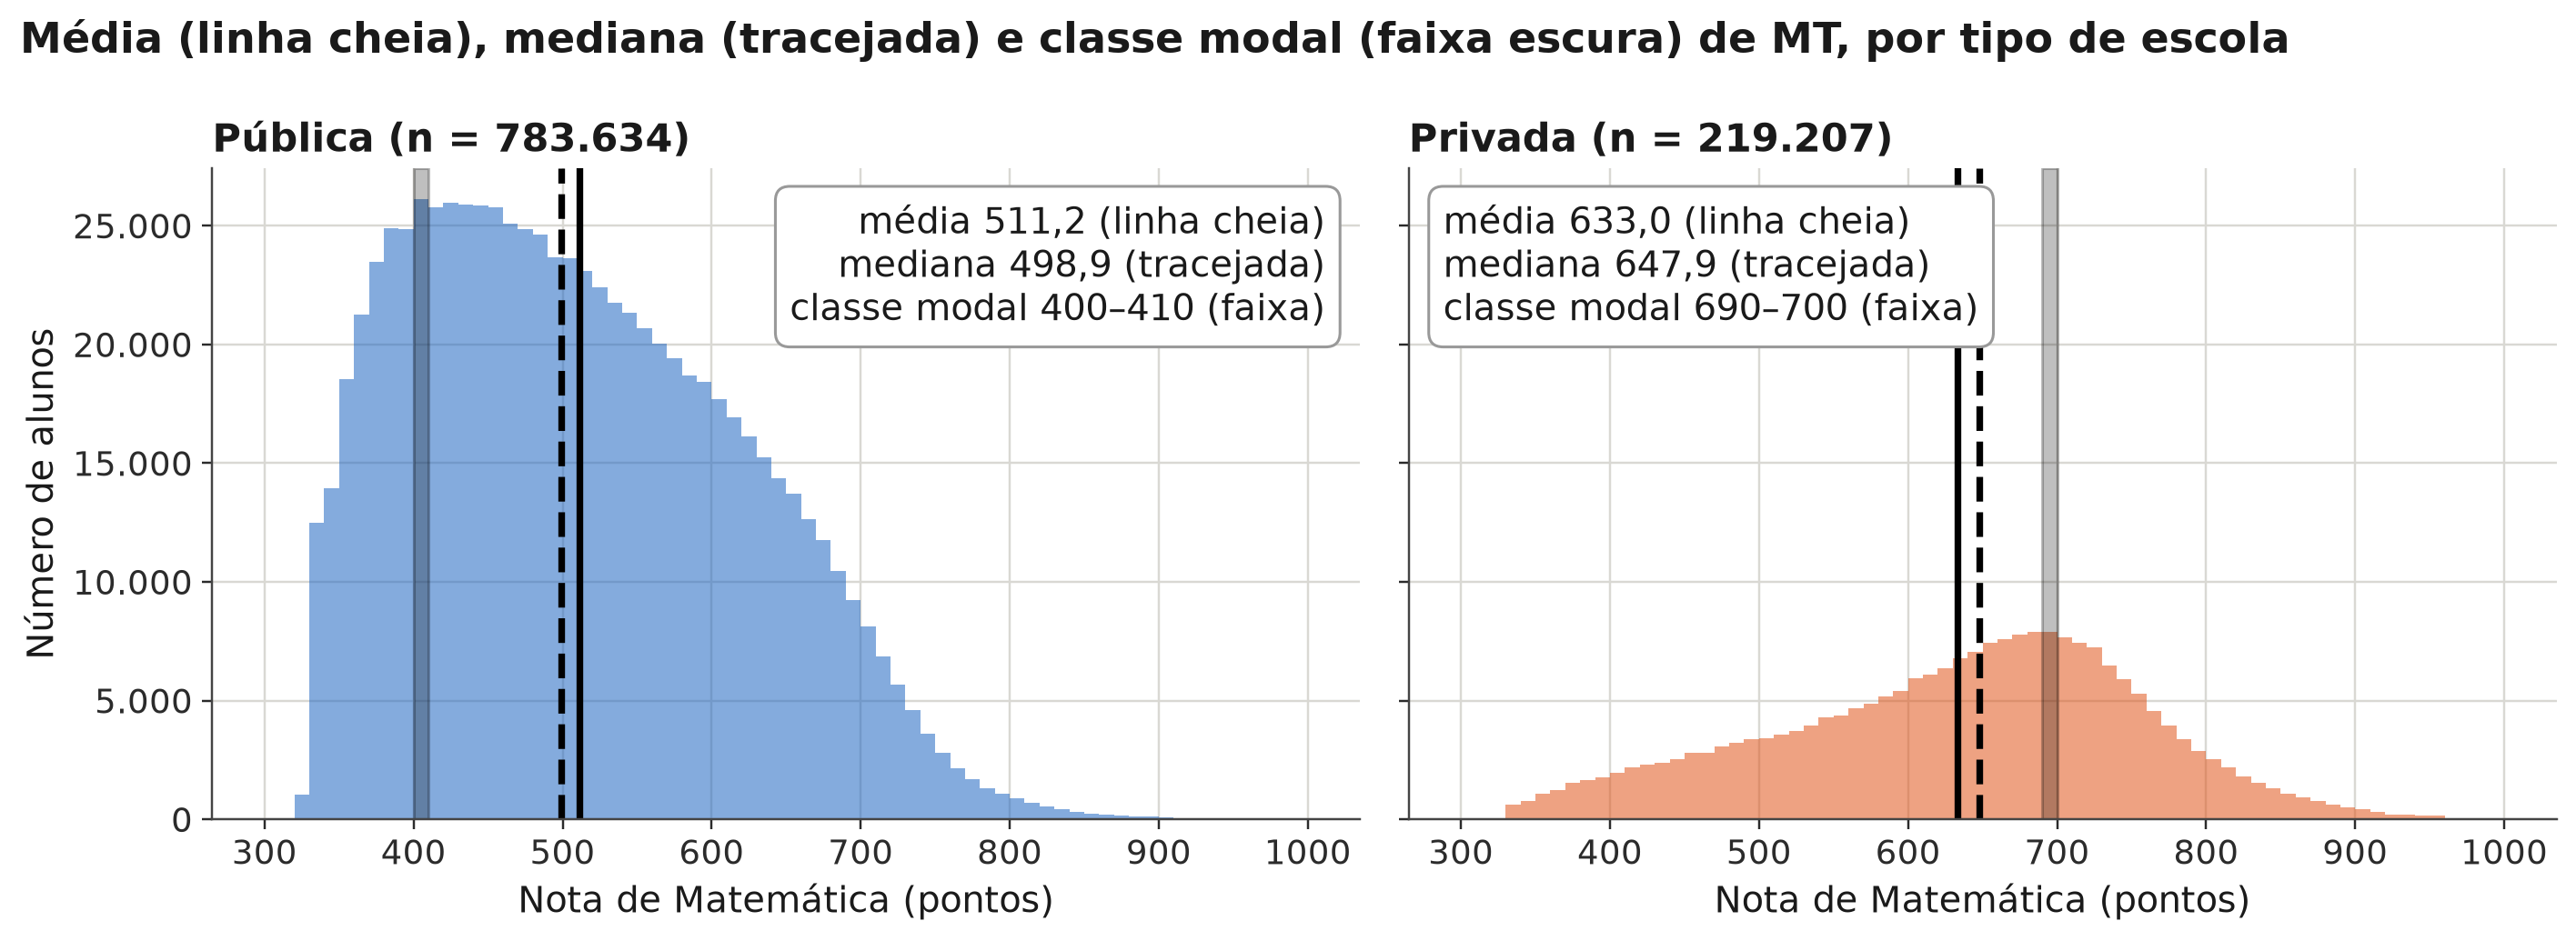

Pública: média 511,2 | mediana 498,9 | classe modal 400–410 pontos
Privada: média 633,0 | mediana 647,9 | classe modal 690–700 pontos


In [15]:
FAIXAS_10 = np.arange(300, 1001, 10)                          # faixas de 10 pontos: [300, 310), [310, 320), ...
centro = {}
fig, eixos = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)
for ax, x, nome, cor in ((eixos[0], pop_pub, 'Pública', AZUL), (eixos[1], pop_priv, 'Privada', LARANJA)):
    contagem, bordas = np.histogram(x, bins=FAIXAS_10)
    k = contagem.argmax()                                      # a faixa com mais alunos = classe modal
    moda_ini, moda_fim = bordas[k], bordas[k + 1]
    media, mediana = x.mean(), np.median(x)
    centro[nome] = {'n': len(x), 'média': media, 'mediana': mediana, 'classe modal': f'{moda_ini:.0f}–{moda_fim:.0f}'}
    ax.hist(x, bins=FAIXAS_10, color=cor, alpha=0.55)
    ax.axvspan(moda_ini, moda_fim, color='black', alpha=0.25)
    ax.axvline(mediana, color='black', lw=2.4, ls='--')
    ax.axvline(media, color='black', lw=2.4)
    canto = (0.97, 'right') if nome == 'Pública' else (0.03, 'left')   # o texto fica no lado vazio do histograma
    ax.text(canto[0], 0.95, f'média {br(media)} (linha cheia)\nmediana {br(mediana)} (tracejada)\n'
            f'classe modal {moda_ini:.0f}–{moda_fim:.0f} (faixa)', transform=ax.transAxes, ha=canto[1], va='top',
            fontsize=13, bbox=dict(facecolor='white', edgecolor='#999999', boxstyle='round,pad=0.4'))
    ax.set_title(f'{nome} (n = {br(len(x), 0)})')
    ax.set_xlabel('Nota de Matemática (pontos)')
eixos[0].set_ylabel('Número de alunos')
eixos[0].yaxis.set_major_formatter(mpl.ticker.FuncFormatter(lambda v, _: br(v, 0)))
fig.suptitle('Média (linha cheia), mediana (tracejada) e classe modal (faixa escura) de MT, por tipo de escola',
             x=0.01, ha='left', fontweight='bold')
plt.tight_layout()
plt.show()
for nome, c in centro.items():
    print(f"{nome}: média {br(c['média'])} | mediana {br(c['mediana'])} | classe modal {c['classe modal']} pontos")

## 3.3 Ler o desvio padrão nos dois grupos

O desvio padrão diz o quanto cada nota se afasta, tipicamente, da média do seu grupo. Uma leitura prática: **média ± 1 desvio padrão** marca a faixa onde está a maior parte do grupo. E a **amplitude interquartil** (Q3 − Q1) marca onde estão os 50% do meio.

In [16]:
for nome, x in (('Pública', pop_pub), ('Privada', pop_priv)):
    m, s = x.mean(), x.std(ddof=1)
    q1, q3 = np.percentile(x, [25, 75])
    dentro = 100 * (np.abs(x - m) < s).mean()                # % do grupo a menos de 1 dp da média
    print(f'{nome}: média ± dp = {br(m)} ± {br(s)} → de {br(m - s, 0)} a {br(m + s, 0)} ({br(dentro)}% do grupo) | '
          f'50% do meio: de {br(q1, 0)} a {br(q3, 0)} (amplitude interquartil = {br(q3 - q1, 0)})')

Pública: média ± dp = 511,2 ± 109,4 → de 402 a 621 (63,0% do grupo) | 50% do meio: de 421 a 591 (amplitude interquartil = 170)
Privada: média ± dp = 633,0 ± 121,3 → de 512 a 754 (67,2% do grupo) | 50% do meio: de 551 a 719 (amplitude interquartil = 168)


**Leitura:** as duas escolas têm espalhamento parecido (desvio padrão entre 109 e 121 pontos), e esse espalhamento é **da mesma ordem** da diferença entre as médias. Por isso as distribuições se sobrepõem, como mostra a seção 3.4.

## 3.4 As distribuições se sobrepõem

Um **histograma** divide a escala em intervalos e conta quantos alunos caem em cada um. Desenhados no mesmo eixo, os dois grupos mostram o que a diferença de médias esconde: muitos alunos de pública acima de muitos alunos de privada.

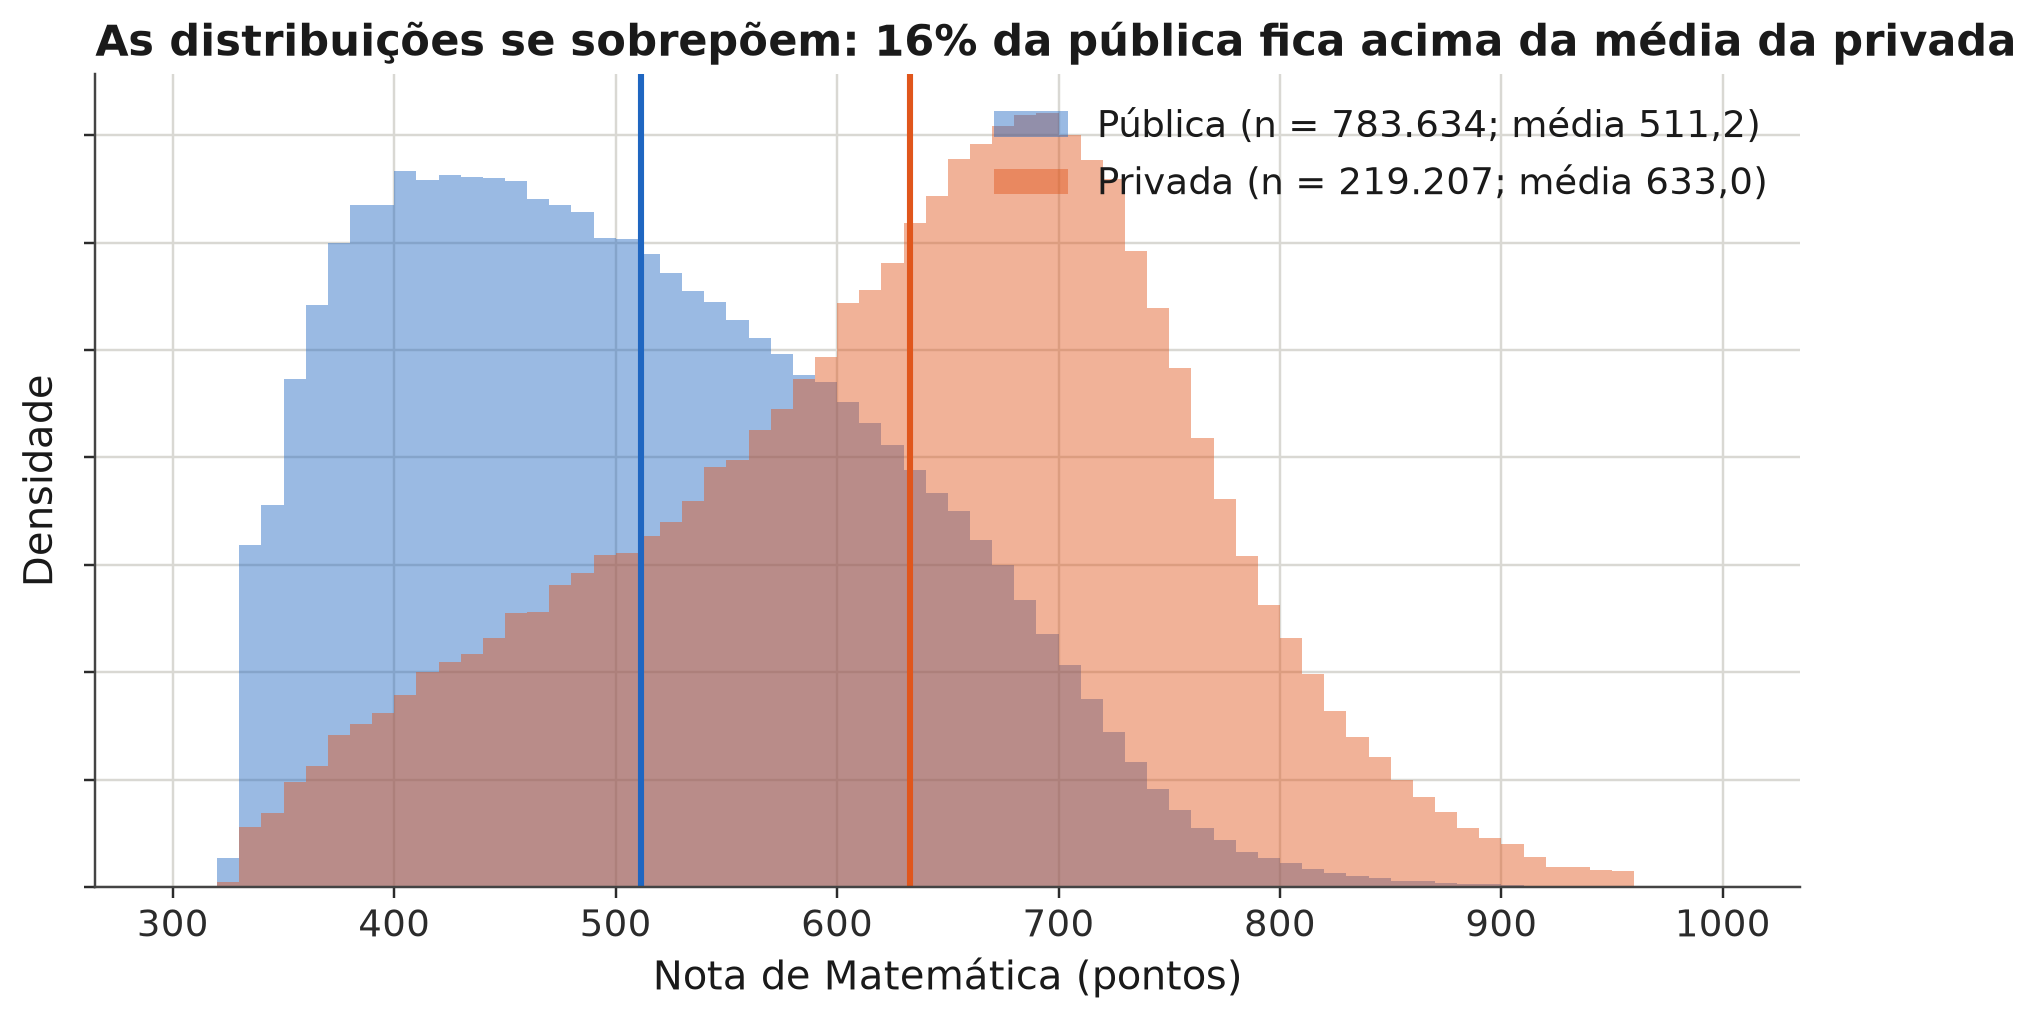

Pública acima da média da privada: 15,9% | privada abaixo da média da pública: 17,9%


In [17]:
fig, ax = plt.subplots(figsize=(10, 4.8))
faixas = np.arange(300, 1001, 10)
for x, nome, cor in ((pop_pub, 'Pública', AZUL), (pop_priv, 'Privada', LARANJA)):
    ax.hist(x, bins=faixas, density=True, color=cor, alpha=0.45, label=f'{nome} (n = {br(len(x), 0)}; média {br(x.mean())})')
    ax.axvline(x.mean(), color=cor, lw=2)
acima = 100 * (pop_pub > pop_priv.mean()).mean()              # % da pública acima da média da privada
abaixo = 100 * (pop_priv < pop_pub.mean()).mean()             # % da privada abaixo da média da pública
ax.set_xlabel('Nota de Matemática (pontos)'); ax.set_ylabel('Densidade'); ax.set_yticklabels([])
ax.set_title(f'As distribuições se sobrepõem: {br(acima, 0)}% da pública fica acima da média da privada')
ax.legend(loc='upper right')
plt.show()
print(f'Pública acima da média da privada: {br(acima)}% | privada abaixo da média da pública: {br(abaixo)}%')

## 3.5 O gráfico honesto: o eixo truncado engana

O erro gráfico mais comum é o **eixo truncado**: num gráfico de barras, o comprimento da barra é o valor, e cortar o eixo muda a razão entre as barras (slide 27).

### Prompt para a IA — o gráfico honesto

O prompt que levaria ao código desta seção. Ele segue o molde do curso: **Papel, Contexto, Pergunta, Tarefa, Restrições, Formato**; pede código (não números), dá o contexto e as restrições, e pede as premissas.

```text
Papel: Você é um analista que prepara gráficos para a diretoria.

Contexto: DataFrame conc com os concluintes de 2023 que informaram escola, na base de análise do ENEM 2023. Colunas: NU_NOTA_MT e escola ("Pública" ou "Privada").

Pergunta: Como mostrar a média de MT da pública e da privada sem exagerar nem esconder a diferença?

Tarefa: Escreva código Python (matplotlib) que: (1) calcule n e média de MT por tipo de escola; (2) faça dois gráficos de barras lado a lado: um com o eixo começando em 490 (o erro a evitar) e outro com o eixo de 0 a 1.000, com valor e n em cada barra; (3) calcule a razão real entre as duas médias e a razão aparente no gráfico truncado.

Restrições: Títulos que dizem a conclusão; eixos com unidade; sem 3D. Só o código: não execute nem mostre resultados.

Formato: Código comentado; depois, o checklist do gráfico honesto aplicado ao gráfico corrigido.
```

**Verificação independente** (o que o analista confere depois de rodar o código que a IA escreveu):
- A razão real é ≈ 1,24 (privada ÷ pública); a aparente no eixo truncado é muitas vezes maior.
- O gráfico corrigido começa em zero e mostra o n de cada barra.
- As médias conferem com a seção 3.2.

*Só no notebook.*

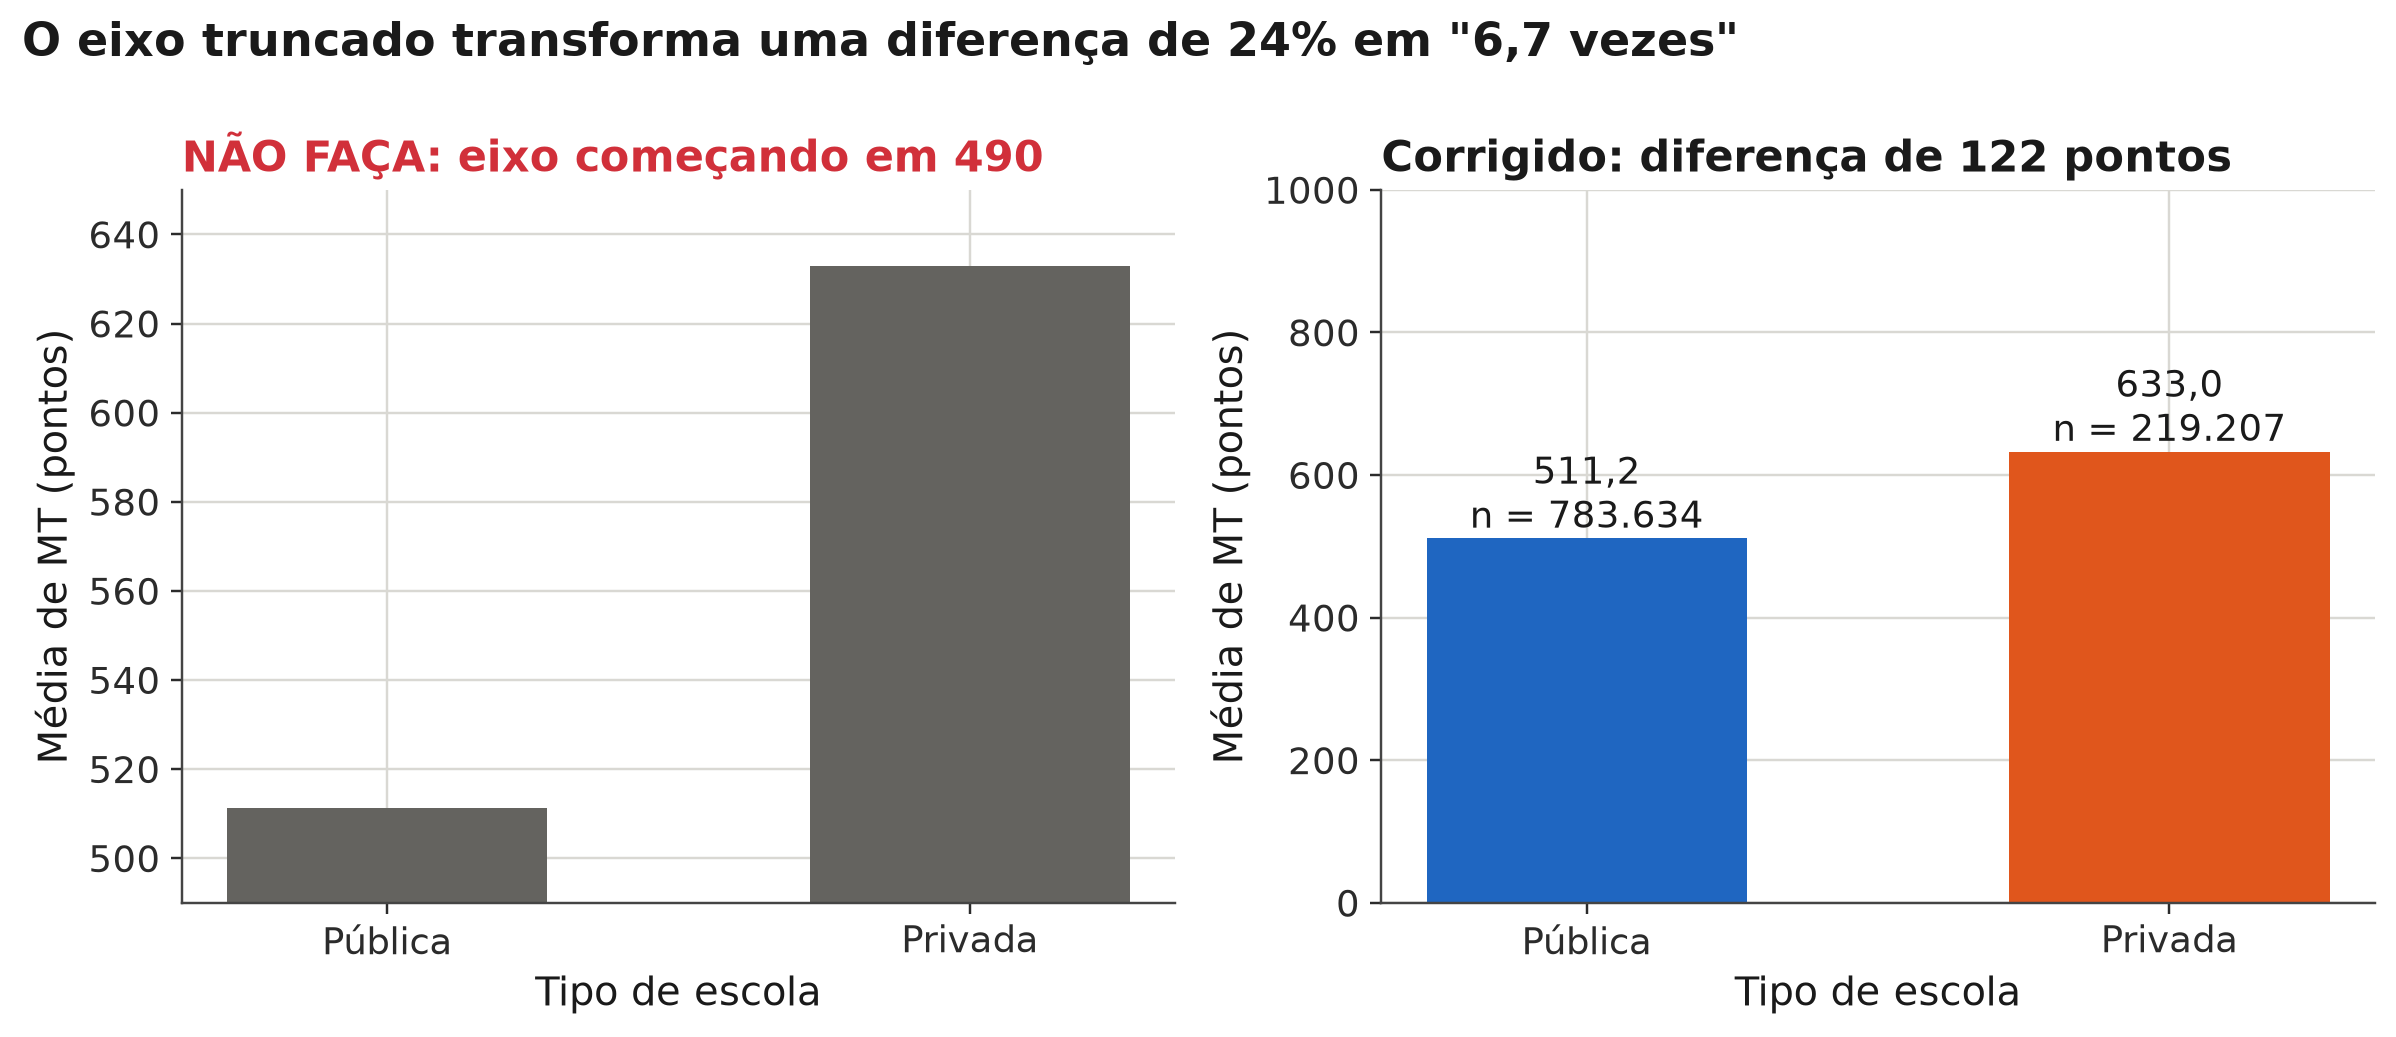

Razão real = 1,24 | razão aparente com o eixo em 490 = 6,7


In [18]:
medias_esc = conc.groupby('escola').NU_NOTA_MT.agg(n='count', média='mean').loc[['Pública', 'Privada']]
PISO = 490                                                     # onde o eixo "truncado" começa
razao_real = medias_esc.média['Privada'] / medias_esc.média['Pública']
razao_aparente = (medias_esc.média['Privada'] - PISO) / (medias_esc.média['Pública'] - PISO)   # razão entre as ALTURAS visíveis

fig, eixos = plt.subplots(1, 2, figsize=(11, 4.8))
eixos[0].bar(medias_esc.index, medias_esc.média, color=CINZA, width=0.55)
eixos[0].set_ylim(PISO, 650)
eixos[0].set_title(f'NÃO FAÇA: eixo começando em {PISO}', fontsize=14, color=VERMELHO)
eixos[1].bar(medias_esc.index, medias_esc.média, color=[AZUL, LARANJA], width=0.55)
eixos[1].set_ylim(0, 1000)
for i, (v, n) in enumerate(zip(medias_esc.média, medias_esc.n)):
    eixos[1].text(i, v + 15, f'{br(v)}\nn = {br(n, 0)}', ha='center', fontsize=12)
eixos[1].set_title(f'Corrigido: diferença de {br(DIF_POP, 0)} pontos', fontsize=14)
for ax in eixos:
    ax.set_xlabel('Tipo de escola'); ax.set_ylabel('Média de MT (pontos)')
fig.suptitle(f'O eixo truncado transforma uma diferença de {br(100 * (razao_real - 1), 0)}% em "{br(razao_aparente, 1)} vezes"',
             x=0.01, ha='left', fontweight='bold')
plt.tight_layout()
plt.show()
print(f'Razão real = {br(razao_real, 2)} | razão aparente com o eixo em {PISO} = {br(razao_aparente, 1)}')

**Checklist do gráfico honesto** (slide 28): título que diz a conclusão; barras a partir de zero; n e fonte visíveis; sem 3D nem decoração; categorias ordinais na ordem natural; tipo de gráfico certo para o dado.

## 3.6 De que tamanho é a diferença: o d de Cohen

"122 pontos" é muito ou pouco? Depende de quanto as notas variam. O **d de Cohen** divide a diferença pelo desvio padrão dos dois grupos juntos. Como o d será usado várias vezes, ele vira uma **função**: um bloco de código com nome, que recebe as notas dos dois grupos e devolve o d.

**Que diferença importa?** O plano (seção 1.5) fixou, antes de abrir os dados, que a menor diferença relevante é **d = 0,2** (efeito pequeno na convenção de Cohen). Agora que o desvio padrão foi medido, esse critério pode ser convertido em pontos. A conversão usa a média simples das duas variâncias, porque na amostra planejada (Parte 6) os dois grupos terão o mesmo tamanho.

In [19]:
def d_cohen(a, b):
    # a e b: notas dos dois grupos
    a, b = np.asarray(a, dtype=float), np.asarray(b, dtype=float)
    # desvio padrão "combinado": média das variâncias dos dois grupos, ponderada pelo tamanho de cada um
    dp_comb = np.sqrt(((len(a) - 1) * a.var(ddof=1) + (len(b) - 1) * b.var(ddof=1)) / (len(a) + len(b) - 2))
    return (a.mean() - b.mean()) / dp_comb

DP_DOIS = np.sqrt((pop_pub.var(ddof=1) + pop_priv.var(ddof=1)) / 2)    # dp dos dois grupos, com peso igual
MARGEM = D_MIN * DP_DOIS                                               # o d = 0,2 do plano, em pontos de MT
D_POP = d_cohen(pop_priv, pop_pub)
print(f'Critério do plano: d = {br(D_MIN)} ≈ {br(MARGEM)} pontos de MT')
print(f'Diferença observada: {br(DIF_POP)} pontos → d = {br(D_POP, 2)} (régua de Cohen: 0,2 pequeno; 0,5 médio; 0,8 grande)')

Critério do plano: d = 0,2 ≈ 23,1 pontos de MT
Diferença observada: 121,8 pontos → d = 1,09 (régua de Cohen: 0,2 pequeno; 0,5 médio; 0,8 grande)


**Leitura:** a diferença é de cerca de **1 desvio padrão**, mais de cinco vezes o mínimo que o plano considerou relevante. É grande pela régua de Cohen.

## 3.7 Mesma faixa de renda, diferença menor

Renda e escola andam juntas: a privada concentra as famílias de renda alta. Então a diferença "privada − pública" mistura as duas coisas. Um jeito simples de separar: comparar **dentro de cada faixa de renda**. Se a diferença sobrevive com a renda fixada, ela não é só renda. É o primeiro passo do que a regressão faz na Parte 7, com vários fatores de uma vez.

### Prompt para a IA — comparar dentro das faixas de renda

O prompt que levaria ao código desta seção. Ele segue o molde do curso: **Papel, Contexto, Pergunta, Tarefa, Restrições, Formato**; pede código (não números), dá o contexto e as restrições, e pede as premissas.

```text
Papel: Você é um analista de dados que escreve código Python claro e auditável.

Contexto: DataFrame conc com os concluintes de 2023 que informaram escola, na base de análise do ENEM 2023. Colunas: NU_NOTA_MT; renda_4 (renda familiar em 4 faixas ordenadas); escola ("Pública" ou "Privada"). Dados observacionais.

Pergunta: A diferença de média de MT entre privada e pública continua quando se compara gente da mesma faixa de renda?

Tarefa: Escreva código Python (pandas) que: (1) calcule, em cada faixa de renda_4, a média de MT e o n de cada tipo de escola e a diferença entre eles; (2) acrescente uma linha com a diferença no total, sem separar por renda.

Restrições: Use pivot_table ou groupby, sem laços. Mostre o n de cada casela. Não use "efeito" nem "causa". Só o código: não execute nem mostre resultados.

Formato: Código comentado em português; depois, como ler a tabela e uma limitação do método (controla um fator de cada vez).
```

**Verificação independente** (o que o analista confere depois de rodar o código que a IA escreveu):
- A linha do total bate com a diferença da seção 3.2 (121,8)?
- O n de cada casela soma o n do grupo?
- A leitura fala em "diminui" ou "permanece", e não em "efeito da escola".

*Só no notebook.*

In [20]:
TOTAL = 'TOTAL (sem separar por renda)'
esc = conc.pivot_table(index='renda_4', columns='escola', values='NU_NOTA_MT', aggfunc='mean')[['Pública', 'Privada']]
esc.loc[TOTAL] = conc.groupby('escola').NU_NOTA_MT.mean()       # linha extra: as médias sem separar por renda
esc['privada − pública'] = esc['Privada'] - esc['Pública']
display(esc.round(1))
display(pd.crosstab(conc.renda_4, conc.escola, margins=True, margins_name='Total'))   # o n de cada casela
dentro = esc['privada − pública'].drop(TOTAL)
print(f'Diferença no total: {br(esc.loc[TOTAL, "privada − pública"])} | dentro das faixas de renda: de {br(dentro.min())} a {br(dentro.max())}')

escola,Pública,Privada,privada − pública
renda_4,,,
1) até R$ 1.320,475.1,552.2,77.1
2) R$ 1.320–3.300,520.2,586.7,66.6
3) R$ 3.300–6.600,560.4,622.1,61.7
4) acima de R$ 6.600,597.2,669.0,71.8
TOTAL (sem separar por renda),511.2,633.0,121.8


escola,Privada,Pública,Total
renda_4,,,
1) até R$ 1.320,11956,328007,339963
2) R$ 1.320–3.300,44668,301689,346357
3) R$ 3.300–6.600,59944,111004,170948
4) acima de R$ 6.600,102639,42934,145573
Total,219207,783634,1002841


Diferença no total: 121,8 | dentro das faixas de renda: de 61,7 a 77,1


**Leitura:** a diferença **diminui** quando a renda é fixada, mas **não some**: parte acompanha a renda e parte permanece. É uma afirmação de **associação**, não de causa, e controla um fator só: sexo, cor/raça e tudo o que não foi medido continuam misturados.

---
# Parte 4 — Probabilidade

> *Como ler uma probabilidade, e quanto do que vemos pode ser acaso?* Probabilidade responde: "se o mundo fosse assim, o que eu veria?". Inferência responde o inverso: "vi isto; como é o mundo?".

## 4.1 Qual condicional estamos lendo?

A notação **P(A | B)** se lê "probabilidade de A **dado** B": a chance de A entre os que têm B. "Nota alta" = MT ≥ 700, fixado no plano: é perto dos 10% mais altos da comparação (o percentil 90 é conferido abaixo). O erro clássico é trocar P(nota alta | privada) por P(privada | nota alta).

### Prompt para a IA — a probabilidade condicional

O prompt que levaria ao código desta seção. Ele segue o molde do curso: **Papel, Contexto, Pergunta, Tarefa, Restrições, Formato**; pede código (não números), dá o contexto e as restrições, e pede as premissas.

```text
Papel: Você é um estatístico que explica probabilidades para gestores.

Contexto: DataFrame conc com os concluintes de 2023 que informaram escola, na base de análise do ENEM 2023 (cerca de 1 milhão). Colunas: NU_NOTA_MT; TP_ESCOLA (2 pública, 3 privada).

Pergunta: Estudar em escola privada e ter nota alta (MT ≥ 700): P(nota alta | privada) é o mesmo que P(privada | nota alta)?

Tarefa: Escreva código Python (pandas) que: (1) calcule o percentil 90 de MT, para conferir o corte de 700; (2) calcule a taxa de base P(privada) e P(MT ≥ 700); (3) calcule P(MT ≥ 700 | privada), P(MT ≥ 700 | pública) e P(privada | MT ≥ 700); (4) monte a tabela 2 × 2 (escola × nota alta) com os totais.

Restrições: Use máscaras booleanas, sem laços. Nomeie cada probabilidade com a notação P(A | B). Não use linguagem causal. Só o código: não execute nem mostre resultados.

Formato: Código comentado; depois, um modelo de frase correta e um de frase errada (inversão da condicional), com lacunas no lugar dos números.
```

**Verificação independente** (o que o analista confere depois de rodar o código que a IA escreveu):
- A tabela 2 × 2 soma o n da comparação (1.002.841).
- Regra de Bayes: P(privada | nota) = P(nota | privada) × P(privada) ÷ P(nota) dá o mesmo que a contagem direta.
- As duas condicionais diferem porque a taxa de base, P(privada), é baixa.

*Nos slides: Parte 4, slide 42.*

In [21]:
print(f'Percentil 90 de MT na comparação = {br(np.percentile(conc.NU_NOTA_MT, 90))} (o corte do plano é {CORTE})')
privada = conc.TP_ESCOLA == 3                     # máscara: estudou em escola privada
alta = conc.NU_NOTA_MT >= CORTE                   # máscara: nota alta em MT
# A média de uma máscara True/False é a proporção de True; dentro de [ ], filtra-se o grupo
print(f'P(privada) = {br(100 * privada.mean())}%   <- a "taxa de base": quão comum é a escola privada')
print(f'P(MT ≥ {CORTE}) = {br(100 * alta.mean())}%')
print(f'P(MT ≥ {CORTE} | privada) = {br(100 * alta[privada].mean())}%   <- entre os de privada, quantos têm nota alta')
print(f'P(MT ≥ {CORTE} | pública) = {br(100 * alta[~privada].mean())}%')
print(f'P(privada | MT ≥ {CORTE}) = {br(100 * privada[alta].mean())}%   <- entre as notas altas, quantas são de privada')
pd.crosstab(conc.escola, alta.map({True: f'MT ≥ {CORTE}', False: f'MT < {CORTE}'}), margins=True, margins_name='Total')

Percentil 90 de MT na comparação = 706,9 (o corte do plano é 700)
P(privada) = 21,9%   <- a "taxa de base": quão comum é a escola privada
P(MT ≥ 700) = 11,1%
P(MT ≥ 700 | privada) = 31,7%   <- entre os de privada, quantos têm nota alta
P(MT ≥ 700 | pública) = 5,3%
P(privada | MT ≥ 700) = 62,5%   <- entre as notas altas, quantas são de privada


NU_NOTA_MT,MT < 700,MT ≥ 700,Total
escola,,,
Privada,149648,69559,219207
Pública,741860,41774,783634
Total,891508,111333,1002841


In [22]:
# Verificação independente pela regra de Bayes: outro caminho, mesmo resultado
bayes = alta[privada].mean() * privada.mean() / alta.mean()
print(f'Bayes: P(privada | MT ≥ {CORTE}) = P(MT ≥ {CORTE} | privada) × P(privada) ÷ P(MT ≥ {CORTE}) = {br(100 * bayes)}%')

Bayes: P(privada | MT ≥ 700) = P(MT ≥ 700 | privada) × P(privada) ÷ P(MT ≥ 700) = 62,5%


**Leitura:** a privada é só cerca de 1 em cada 5 concluintes, mas fica com a maioria das notas altas (62,5%); ainda assim, só cerca de 1 em cada 3 alunos de privada chega a 700. São duas perguntas diferentes, com duas respostas diferentes. *Frase certa:* "62,5% das notas de 700 ou mais são de alunos de escola privada". *Frase errada:* "62,5% dos alunos de escola privada tiram 700 ou mais" (são 31,7%).

## 4.2 A distribuição normal nos dois grupos

A **normal** é o modelo em forma de sino. O **escore z** mede a distância até a média em desvios padrão: z = (nota − média) ÷ desvio padrão. Se a normal valesse, 68,3% das notas ficariam a menos de 1 desvio padrão da média, 95,4% a menos de 2 e 99,7% a menos de 3.

### Prompt para a IA — a normal e o Teorema Central do Limite

O prompt que levaria ao código desta seção. Ele segue o molde do curso: **Papel, Contexto, Pergunta, Tarefa, Restrições, Formato**; pede código (não números), dá o contexto e as restrições, e pede as premissas.

```text
Papel: Você é um estatístico que testa modelos contra os dados.

Contexto: Arrays pop_pub e pop_priv com as notas de MT dos concluintes de 2023 de escola pública e privada (base de análise do ENEM 2023); DataFrame insc com todos os inscritos e TP_PRESENCA_MT (1 = presente).

Pergunta: A normal descreve bem as notas de cada tipo de escola? E a média de amostras de uma variável 0/1 fica normal quando n cresce?

Tarefa: Escreva código Python (numpy, scipy e matplotlib) que: (1) calcule, em cada grupo, média, DP e o % a menos de 1, 2 e 3 DP da média; (2) calcule o z da média da pública na distribuição da privada e a fração da pública acima da média da privada, observada e pela normal; (3) desenhe o histograma de cada grupo com a normal de mesma média e DP; (4) com a presença em MT (0/1), sorteie 5.000 amostras de n = 5, 30, 400 e 1.000 (semente 2023), desenhe o histograma das proporções com faixas alinhadas aos valores possíveis (k/n) e a normal por cima, e compare o DP delas com √(p(1−p)/n).

Restrições: Use o DP populacional (ddof = 0), porque os grupos são tratados como população. Só o código: não execute nem mostre resultados.

Formato: Código comentado; depois, em 3 frases, onde a normal é um bom modelo e onde não é.
```

**Verificação independente** (o que o analista confere depois de rodar o código que a IA escreveu):
- Na normal: 68,3% | 95,4% | 99,7% (`stats.norm.cdf(1) − stats.norm.cdf(−1)` etc.).
- z refeito à mão: (511,2 − 633,0) ÷ 121,3 ≈ −1,00.
- O DP das proporções simuladas fica perto de √(p(1−p)/n) em cada n (seção 4.3).

*Só no notebook.*

In [23]:
MU_PUB, DP_PUB = pop_pub.mean(), pop_pub.std()                 # cada grupo tratado como população (ddof = 0)
MU_PRIV, DP_PRIV = pop_priv.mean(), pop_priv.std()

z_pub = (MU_PUB - MU_PRIV) / DP_PRIV                           # onde a média da pública cai na distribuição da privada
print(f'z da média da pública na distribuição da privada = ({br(MU_PUB)} − {br(MU_PRIV)}) ÷ {br(DP_PRIV)} = {br(z_pub, 2)}')

# Quantos alunos de pública ficam acima da média da privada: observado × o que a normal prevê
obs = 100 * (pop_pub > MU_PRIV).mean()
normal = 100 * stats.norm.sf(MU_PRIV, MU_PUB, DP_PUB)
print(f'Pública acima da média da privada: {br(obs)}% observados | {br(normal)}% pela normal')

regra = {}
for nome, x, m, s in (('Pública', pop_pub, MU_PUB, DP_PUB), ('Privada', pop_priv, MU_PRIV, DP_PRIV)):
    z = (x - m) / s                                            # escore z de cada aluno no próprio grupo
    regra[nome] = {'média': m, 'dp': s, 'assimetria': stats.skew(x),
                   '|z| < 1 (%)': 100 * (abs(z) < 1).mean(), '|z| < 2 (%)': 100 * (abs(z) < 2).mean(), '|z| < 3 (%)': 100 * (abs(z) < 3).mean()}
regra['Normal (esperado)'] = {f'|z| < {k} (%)': 100 * (stats.norm.cdf(k) - stats.norm.cdf(-k)) for k in (1, 2, 3)}
pd.DataFrame(regra).T.round(1)                                 # uma casa decimal, como nos slides

z da média da pública na distribuição da privada = (511,2 − 633,0) ÷ 121,3 = -1,00
Pública acima da média da privada: 15,9% observados | 13,3% pela normal


,média,dp,assimetria,|z| < 1 (%),|z| < 2 (%),|z| < 3 (%)
Pública,511.2,109.4,0.4,63.0,97.3,99.8
Privada,633.0,121.3,-0.3,67.2,95.5,100.0
Normal (esperado),NaN,NaN,NaN,68.3,95.4,99.7


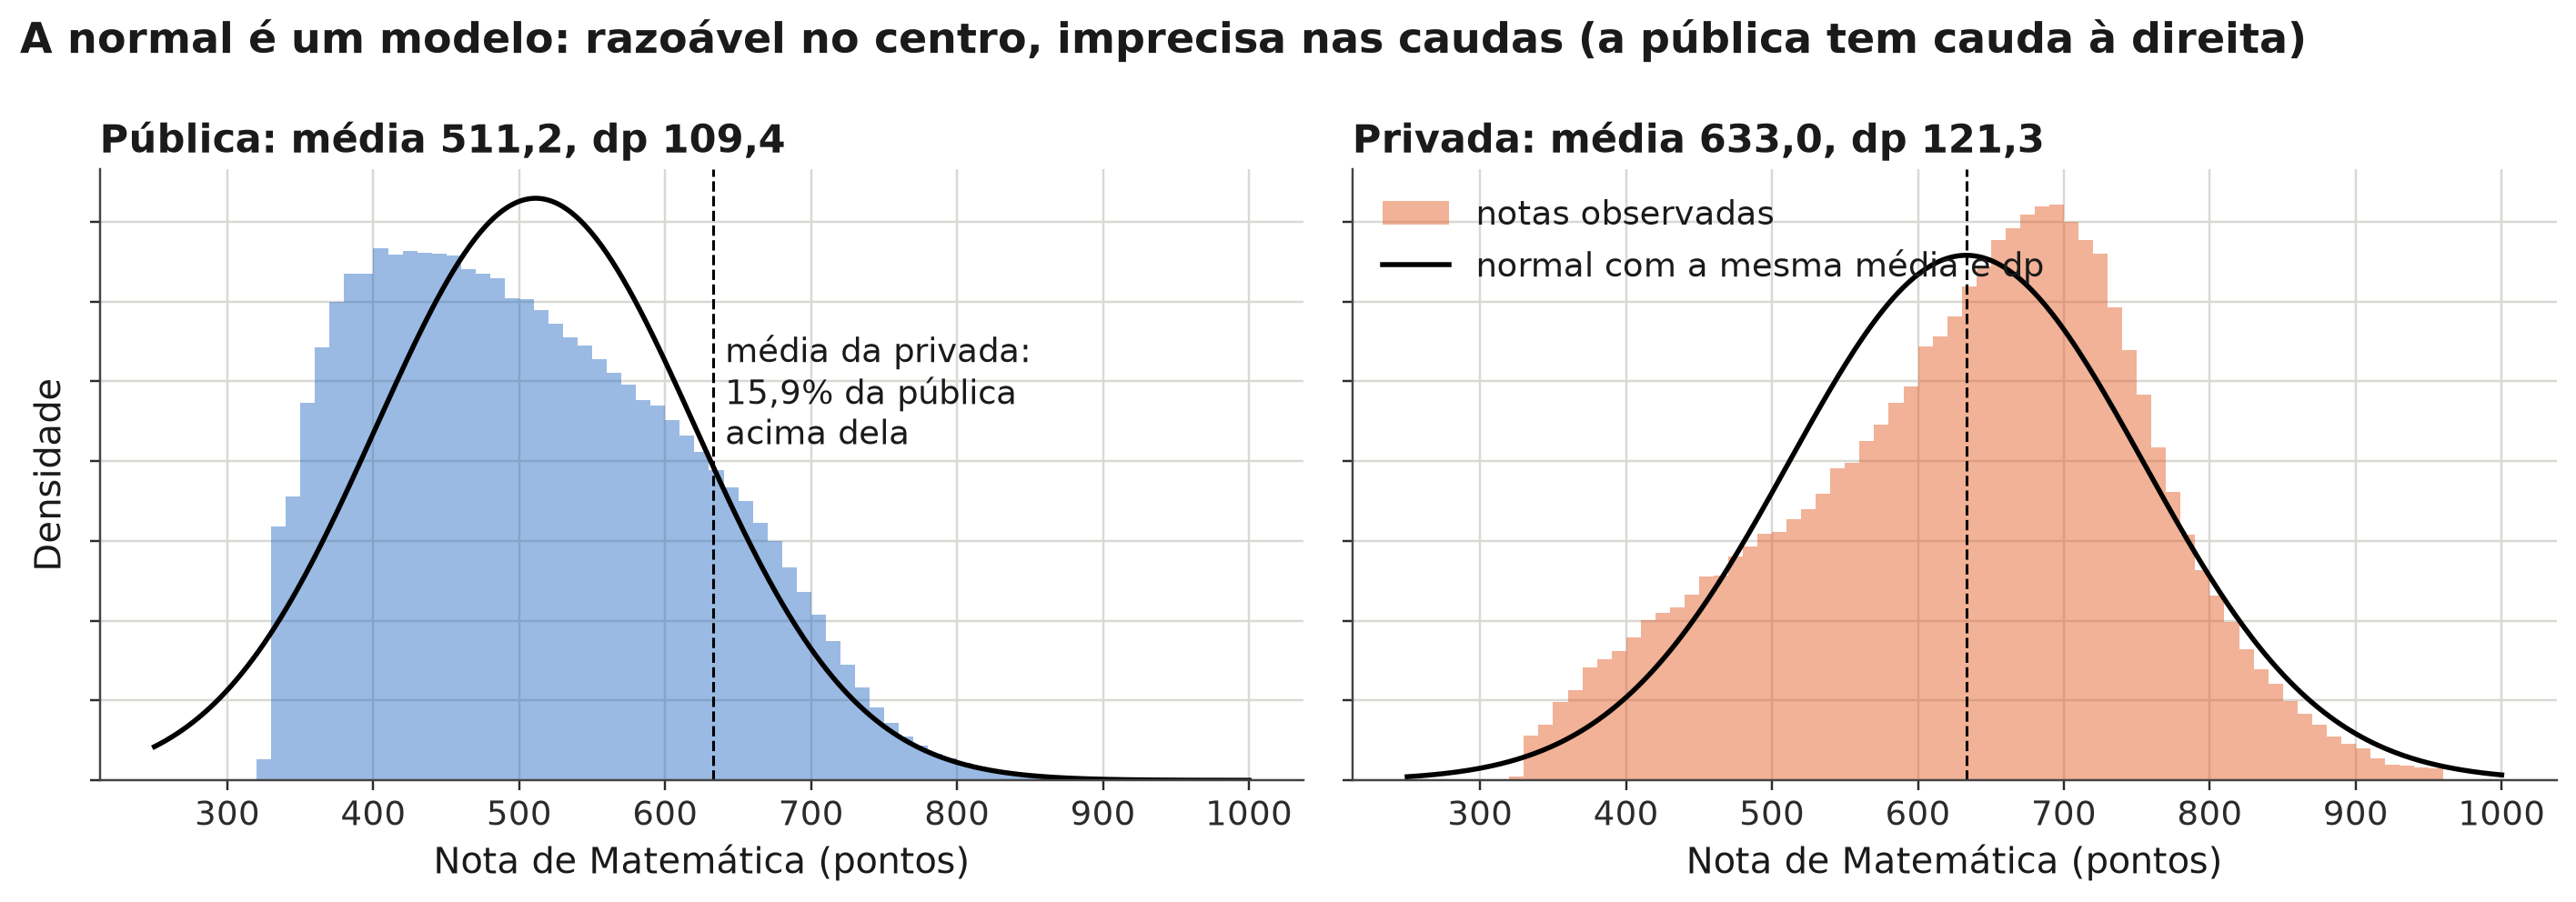

In [24]:
fig, eixos = plt.subplots(1, 2, figsize=(13, 4.6), sharey=True)
xs = np.linspace(250, 1000, 400)
for ax, x, nome, cor, m, s in ((eixos[0], pop_pub, 'Pública', AZUL, MU_PUB, DP_PUB), (eixos[1], pop_priv, 'Privada', LARANJA, MU_PRIV, DP_PRIV)):
    ax.hist(x, bins=np.arange(300, 1001, 10), density=True, color=cor, alpha=0.45, label='notas observadas')
    ax.plot(xs, stats.norm.pdf(xs, m, s), color='black', lw=1.8, label='normal com a mesma média e dp')
    ax.set_title(f'{nome}: média {br(m)}, dp {br(s)}', fontsize=14)
    ax.set_xlabel('Nota de Matemática (pontos)')
    ax.set_yticklabels([])                                    # a escala da densidade não interessa; a forma, sim
    ax.axvline(MU_PRIV, color='black', lw=1, ls='--')
eixos[1].legend(loc='upper left')
eixos[0].text(MU_PRIV + 8, eixos[0].get_ylim()[1] * 0.55, f'média da privada:\n{br(obs, 1)}% da pública\nacima dela', fontsize=12)
eixos[0].set_ylabel('Densidade')
fig.suptitle('A normal é um modelo: razoável no centro, imprecisa nas caudas (a pública tem cauda à direita)', x=0.01, ha='left', fontweight='bold')
plt.tight_layout()
plt.show()

**Leitura:** a média da pública fica a cerca de **1 desvio padrão** abaixo da média da privada. A normal acerta a ordem de grandeza, mas erra a cauda: ela prevê 13% da pública acima da média da privada, e os dados mostram 16%. Para decisões que dependem da cauda (bolsas, cortes), use a proporção observada.

## 4.3 O Teorema Central do Limite (TCL)

A presença na prova é uma variável **nada normal**: só vale 0 (faltou) ou 1 (presente). Mesmo assim, se sortearmos muitas amostras e calcularmos a proporção de presentes em cada uma, essas proporções formam um **sino**, cada vez mais estreito conforme n cresce. Esse é o TCL, e é por causa dele que intervalos de confiança e testes funcionam com médias de amostras (Partes 5 e 6). O espalhamento das proporções tem nome, **erro padrão**, e vale √(p(1−p)/n).

**Cuidado ao desenhar:** numa amostra de n, a proporção só pode valer 0, 1/n, 2/n, ... Se as faixas do histograma não respeitam esses valores, umas faixas pegam dois valores e outras um, e o sino parece "serrilhado" mesmo com n grande. Por isso as faixas abaixo têm uma faixa por valor possível, e a normal vem desenhada por cima, para comparar a forma.

n =    5: espalhamento simulado = 0,2074 | fórmula √(p(1−p)/n) = 0,2078 | assimetria = -0,35
n =   30: espalhamento simulado = 0,0825 | fórmula √(p(1−p)/n) = 0,0849 | assimetria = -0,09
n =  400: espalhamento simulado = 0,0232 | fórmula √(p(1−p)/n) = 0,0232 | assimetria = -0,01


n = 1000: espalhamento simulado = 0,0146 | fórmula √(p(1−p)/n) = 0,0147 | assimetria = 0,02


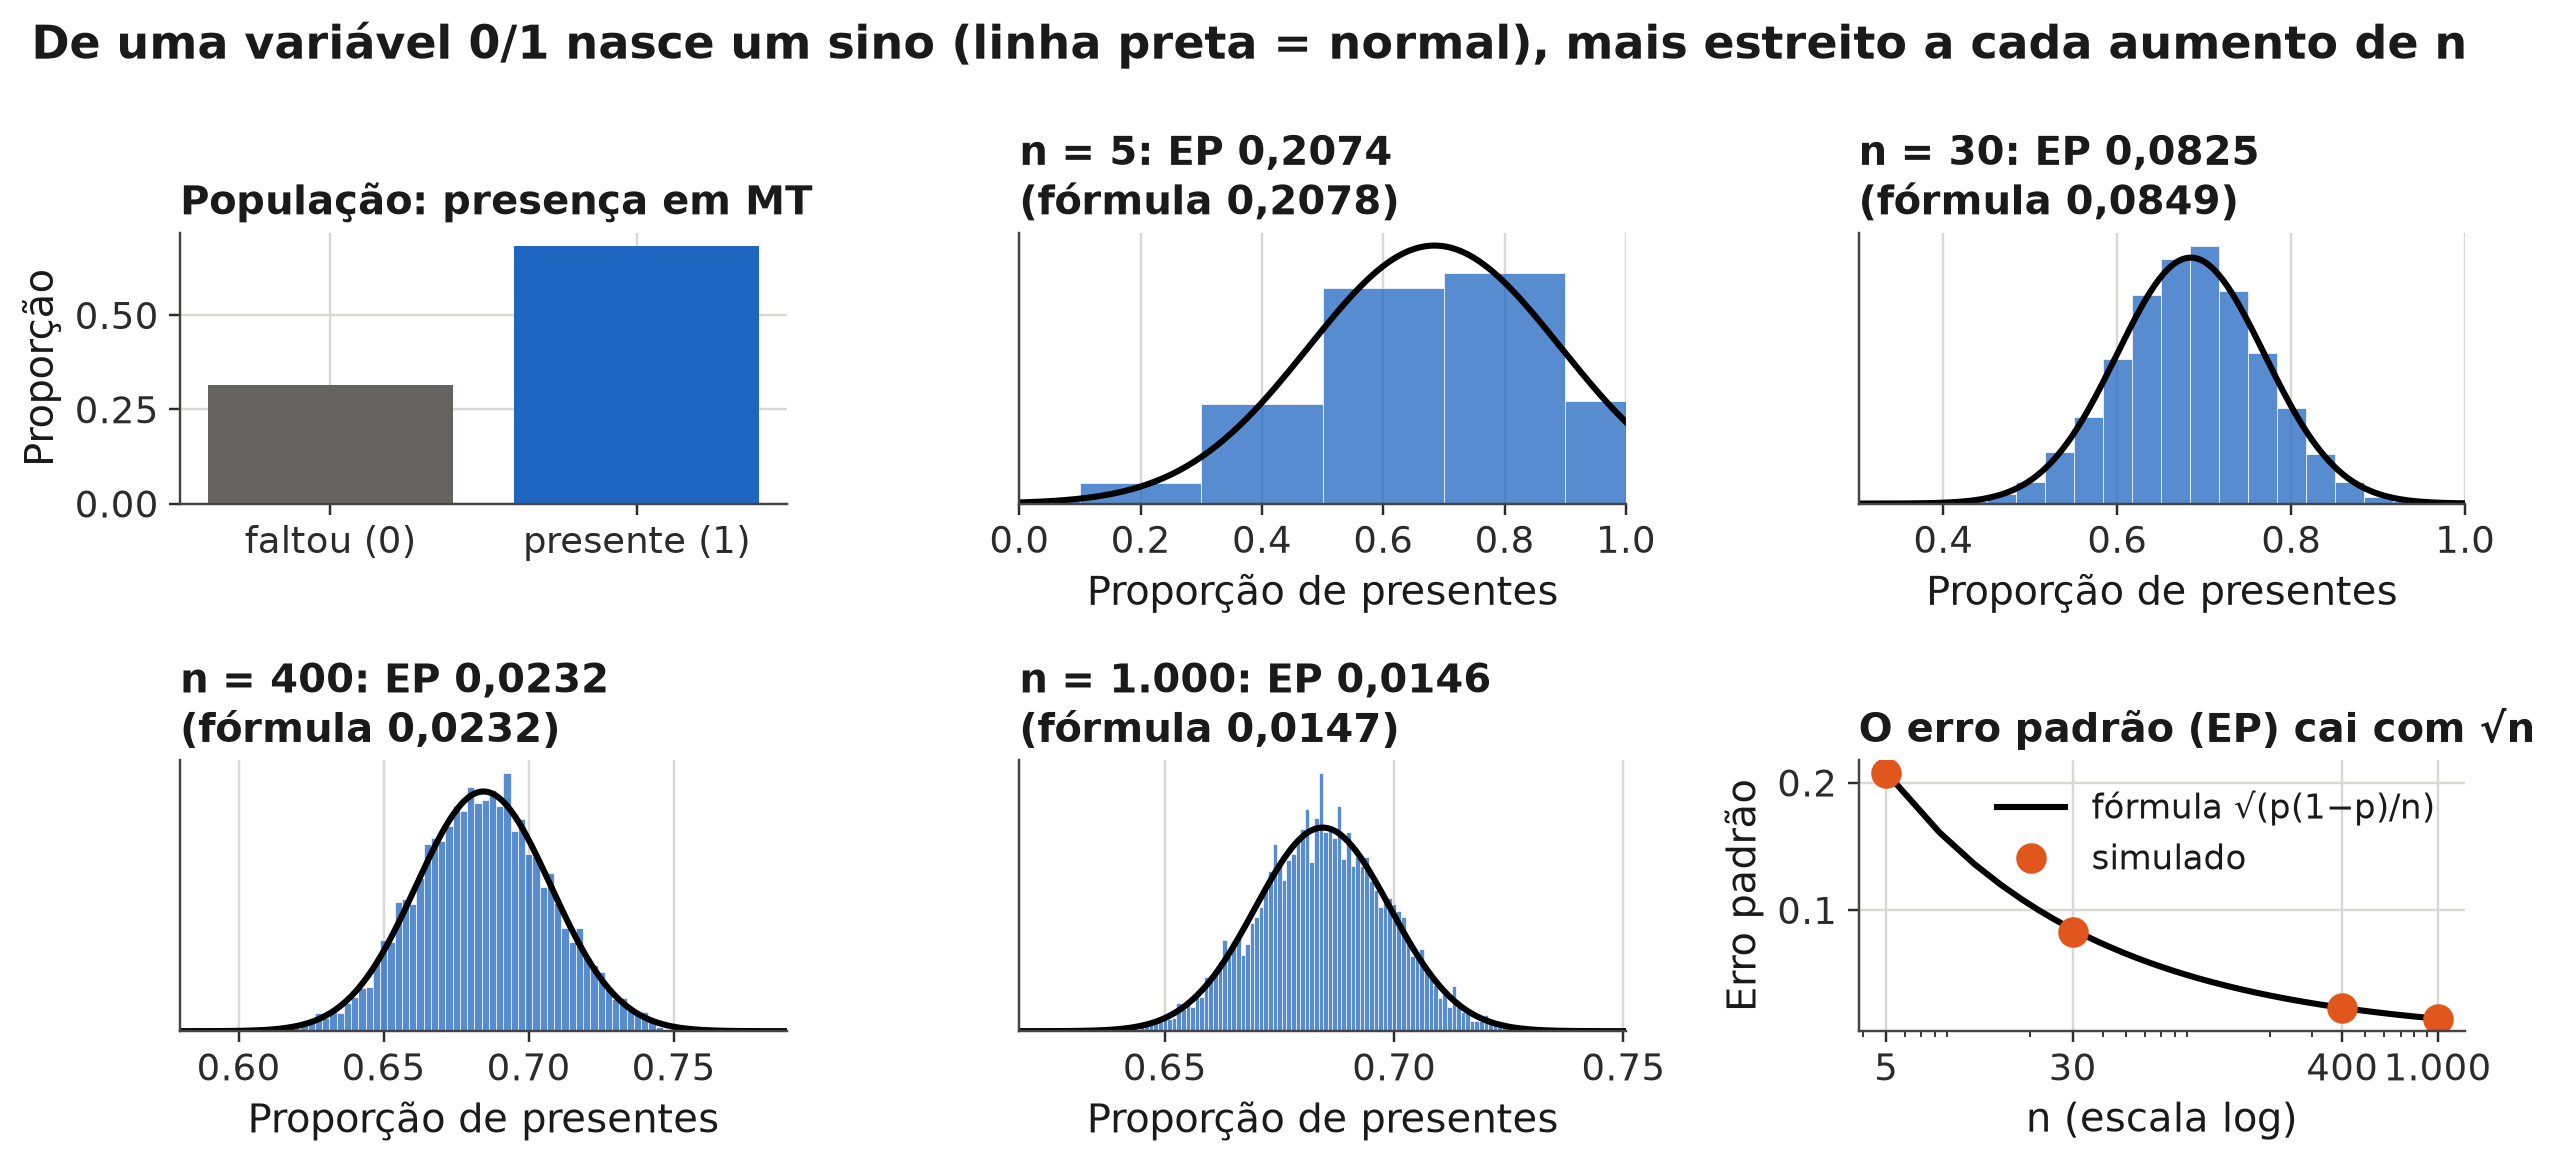

In [25]:
rng = np.random.default_rng(SEMENTE)                         # gerador desta seção
presenca = (insc.TP_PRESENCA_MT == 1).astype(int).to_numpy() # 1 = presente, 0 = não; todos os inscritos
p_pop = presenca.mean()

TAMANHOS_TCL = (5, 30, 400, 1000)
fig, eixos = plt.subplots(2, 3, figsize=(11.5, 5.4))
eixos = eixos.ravel()
eixos[0].bar(['faltou (0)', 'presente (1)'], [1 - p_pop, p_pop], color=[CINZA, AZUL])
eixos[0].set_title('População: presença em MT', fontsize=13); eixos[0].set_ylabel('Proporção')
dp_sim, assim = {}, {}
for ax, n in zip(eixos[1:5], TAMANHOS_TCL):
    proporcoes = rng.choice(presenca, size=(5000, n)).mean(axis=1)    # 5.000 amostras de tamanho n; a proporção de cada uma
    ep = np.sqrt(p_pop * (1 - p_pop) / n)                             # erro padrão pela fórmula
    # Uma faixa para cada valor possível da proporção (k/n): sem isso, o histograma fica "serrilhado"
    k_min, k_max = int(round(proporcoes.min() * n)), int(round(proporcoes.max() * n))
    faixas = (np.arange(k_min, k_max + 2) - 0.5) / n
    ax.hist(proporcoes, bins=faixas, density=True, color=AZUL, alpha=0.75, edgecolor='white', linewidth=0.3)
    xs = np.linspace(p_pop - 4.5 * ep, p_pop + 4.5 * ep, 300)
    ax.plot(xs, stats.norm.pdf(xs, p_pop, ep), color='black', lw=2)   # a normal prevista pelo TCL
    ax.set_xlim(max(0, p_pop - 4.5 * ep), min(1, p_pop + 4.5 * ep))
    ax.set_yticks([])
    ax.set_title(f'n = {br(n, 0)}: EP {br(proporcoes.std(ddof=1), 4)}\n(fórmula {br(ep, 4)})', fontsize=13)
    ax.set_xlabel('Proporção de presentes')
    dp_sim[n], assim[n] = proporcoes.std(ddof=1), stats.skew(proporcoes)
    print(f'n = {n:4d}: espalhamento simulado = {br(dp_sim[n], 4)} | fórmula √(p(1−p)/n) = {br(ep, 4)} | assimetria = {br(assim[n], 2)}')
# Último painel: o erro padrão cai com √n (a lei da Parte 5)
ns_curva = np.linspace(5, 1000, 300)
eixos[5].plot(ns_curva, np.sqrt(p_pop * (1 - p_pop) / ns_curva), color='black', lw=2, label='fórmula √(p(1−p)/n)')
eixos[5].plot(list(dp_sim), list(dp_sim.values()), 'o', color=LARANJA, ms=9, label='simulado')
eixos[5].set_xscale('log'); eixos[5].set_xticks(TAMANHOS_TCL, [br(n, 0) for n in TAMANHOS_TCL])
eixos[5].set_title('O erro padrão (EP) cai com √n', fontsize=13); eixos[5].set_xlabel('n (escala log)'); eixos[5].set_ylabel('Erro padrão')
eixos[5].legend(loc='upper right', fontsize=11)
fig.suptitle('De uma variável 0/1 nasce um sino (linha preta = normal), mais estreito a cada aumento de n',
             x=0.01, ha='left', fontweight='bold')
plt.tight_layout()
plt.show()

---
# Parte 5 — Amostragem

> *Se só tivéssemos uma amostra: sorteada como, com que margem de erro, e de que tamanho?*

**Por que amostras, se temos todos os participantes?** A base é um censo de quem fez a prova. No trabalho real, quase sempre só se tem uma amostra (pesquisa de clima, auditoria de prontuários, satisfação). Aqui a base faz o papel de **população**: sorteamos amostras, fazemos a inferência como na vida real e conferimos o resultado contra o valor verdadeiro, que aqui é conhecido. É um laboratório.

## 5.1 Tipos de amostragem

Só com **sorteio** o erro se mede (slide 47). Nas **não probabilísticas** (por julgamento, por conveniência, por cotas), não há como calcular a margem de erro. Nas **probabilísticas**, cada elemento tem chance conhecida de entrar: **aleatória simples** (todos com a mesma chance), sistemática, **estratificada** (sorteio separado dentro de grupos, como pública e privada) e por conglomerados. As seções seguintes usam a aleatória simples e a estratificada.

## 5.2 Erro padrão e intervalo de confiança

Primeiro, com a média geral de MT da base de análise.

### Prompt para a IA — o erro padrão e o intervalo de confiança

O prompt que levaria ao código desta seção. Ele segue o molde do curso: **Papel, Contexto, Pergunta, Tarefa, Restrições, Formato**; pede código (não números), dá o contexto e as restrições, e pede as premissas.

```text
Papel: Você é um estatístico que mostra o erro amostral por simulação.

Contexto: DataFrame base com a base de análise do ENEM 2023 (2.569.190 participantes), que vou tratar como população. Coluna: NU_NOTA_MT.

Pergunta: Quão perto uma amostra aleatória chega da média verdadeira de MT, e como ler o intervalo de confiança?

Tarefa: Escreva código Python (numpy, scipy e matplotlib) que: (1) calcule μ e σ da população e o erro padrão teórico σ/√n para n = 100, 400 e 1.600; (2) sorteie, com semente 2023, uma amostra aleatória simples de n = 400 e calcule a média e o IC95% pela t; (3) sorteie 1.000 amostras de n = 400 e compare o DP das 1.000 médias com σ/√n; (4) sorteie 100 amostras de n = 50, calcule o IC95% de cada uma, conte quantos contêm μ e desenhe os 100 intervalos.

Restrições: Use o DP amostral (ddof = 1) no IC. Não use a frase "95% de probabilidade de μ estar no intervalo". Só o código: não execute nem mostre resultados.

Formato: Código comentado; depois, a leitura correta e a leitura errada de um IC de 95%.
```

**Verificação independente** (o que o analista confere depois de rodar o código que a IA escreveu):
- σ/√n com σ = 124,91: 12,5 (n = 100), 6,25 (n = 400), 3,1 (n = 1.600).
- O DP das 1.000 médias fica perto de 6,25.
- Cerca de 95 dos 100 intervalos contêm μ (o número exato varia com a semente).
- Quadruplicar n divide o erro padrão por 2.

*Nos slides: Parte 5, slide 59.*

O **erro padrão** (EP) é o tamanho típico do erro de uma média amostral: EP = σ / √n. Como n está dentro de uma raiz, **quadruplicar a amostra só divide o erro por 2**.

In [26]:
mt = base.NU_NOTA_MT.to_numpy()
MU, SIGMA = mt.mean(), mt.std()                              # média e desvio padrão "verdadeiros" (a população do laboratório)
print(f'População: N = {br(len(mt), 0)} | μ = {br(MU, 2)} | σ = {br(SIGMA, 2)}')
pd.DataFrame({'n': [100, 400, 1600], 'erro padrão σ/√n (pontos)': [SIGMA / np.sqrt(n) for n in (100, 400, 1600)]}).set_index('n').round(2)

População: N = 2.569.190 | μ = 540,60 | σ = 124,91


,erro padrão σ/√n (pontos)
n,
100,12.49
400,6.25
1600,3.12


Na vida real, o analista tem **uma** amostra. A partir dela calcula a média e um **intervalo de confiança de 95%** (IC95%): média ± t × S/√n, onde S é o desvio padrão da amostra e t ≈ 2 (o valor exato vem da distribuição t de Student).

In [27]:
def ic_media(x, confianca=0.95):
    # Devolve a média da amostra e os limites do intervalo de confiança: média ± t · S/√n
    x = np.asarray(x, dtype=float)
    n, media = len(x), x.mean()
    ep = x.std(ddof=1) / np.sqrt(n)                          # erro padrão estimado com o S da amostra
    t = stats.t.ppf((1 + confianca) / 2, n - 1)              # ≈ 1,97 para n = 400
    return media, media - t * ep, media + t * ep

rng = np.random.default_rng(SEMENTE)                         # gerador desta seção (vale também para a próxima célula)
amostra = rng.choice(mt, size=400, replace=False)            # amostra aleatória simples de 400 participantes
m, inf, sup = ic_media(amostra)
print(f'Amostra de n = 400: média = {br(m)} | IC95% = [{br(inf)}; {br(sup)}]')
print(f'Erro desta amostra = {br(m - MU)} pontos | o IC contém a média verdadeira ({br(MU, 2)})? {inf <= MU <= sup}')

Amostra de n = 400: média = 539,7 | IC95% = [527,5; 551,9]
Erro desta amostra = -0,9 pontos | o IC contém a média verdadeira (540,60)? True


Repetindo o sorteio mil vezes, vemos a **distribuição das médias amostrais**: em torno da média verdadeira, com espalhamento igual ao erro padrão.

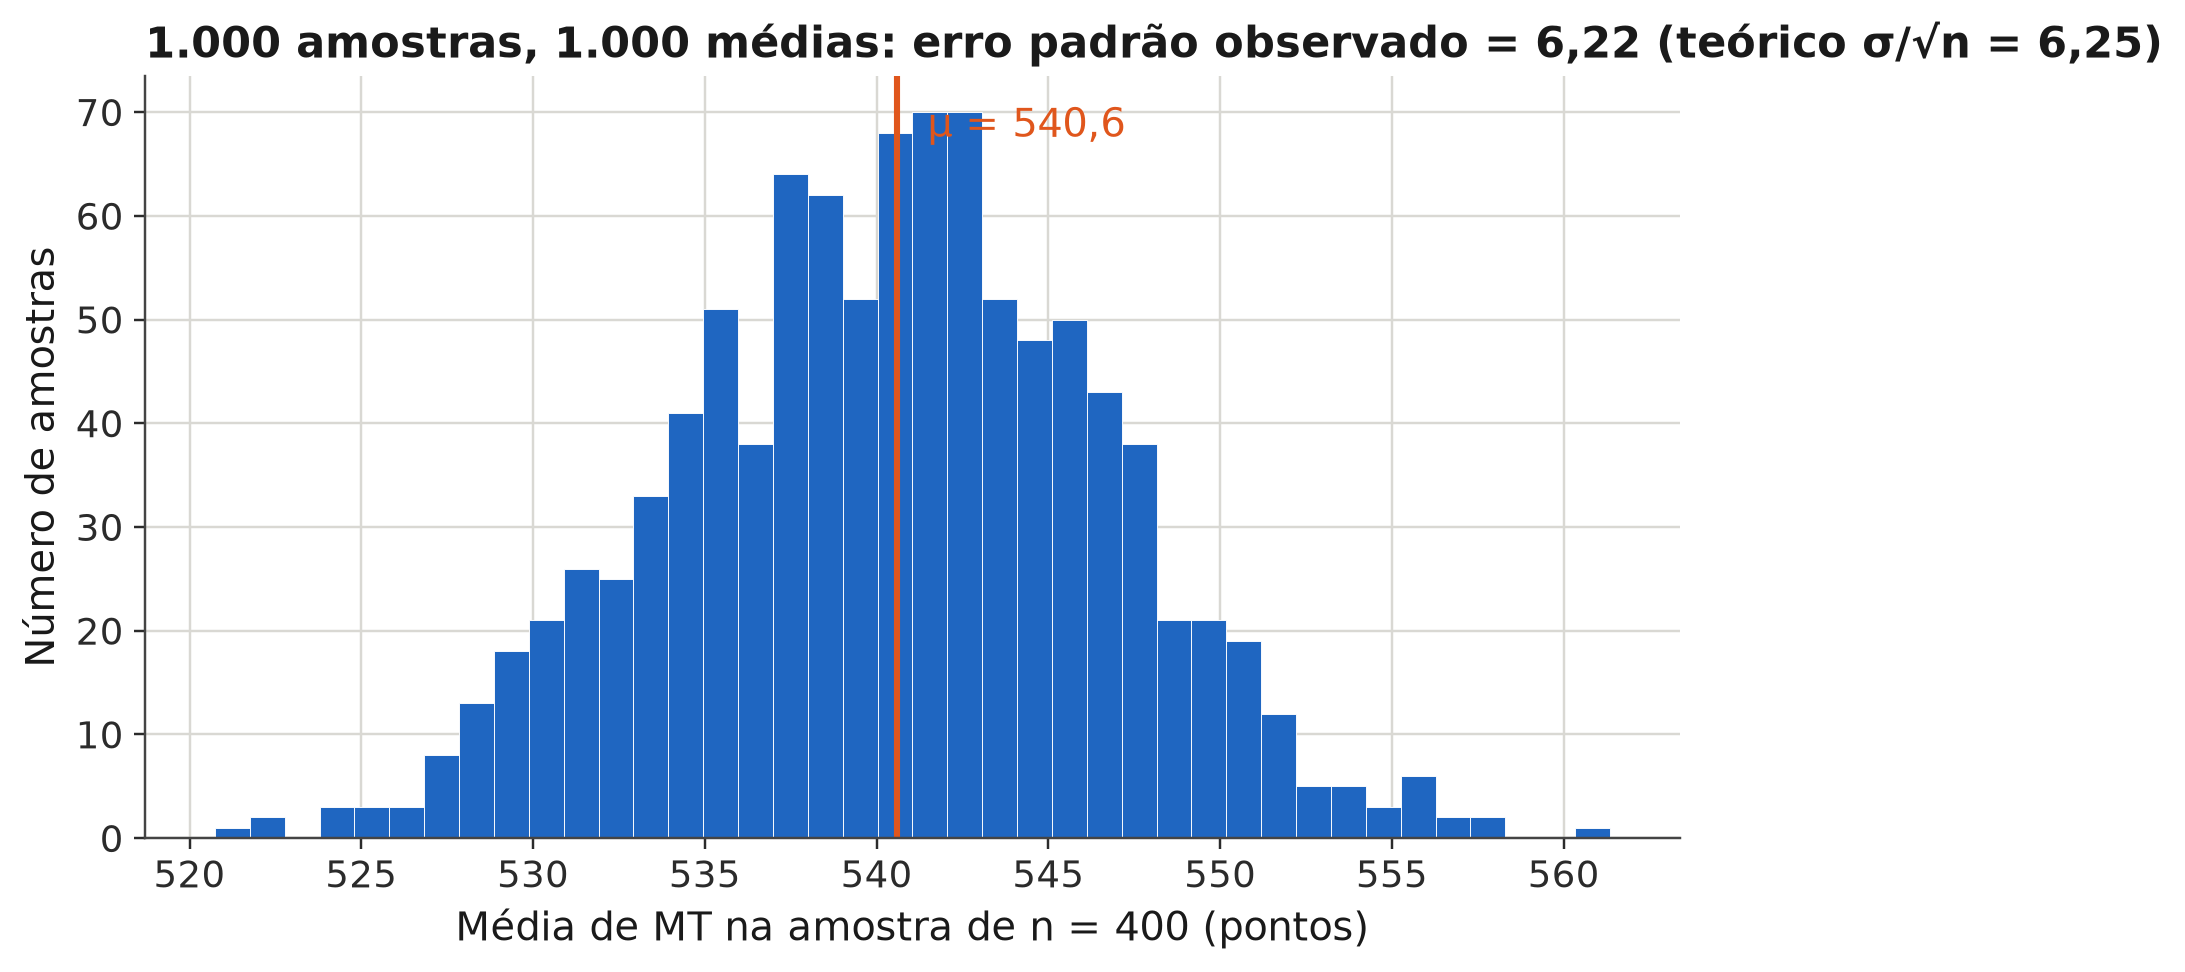

Erro padrão observado (DP das 1.000 médias) = 6,22 | teórico σ/√n = 6,25


In [28]:
medias_400 = rng.choice(mt, size=(1000, 400)).mean(axis=1)   # 1.000 amostras de 400 (uma por linha); a média de cada uma

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.hist(medias_400, bins=40, color=AZUL, edgecolor='white', linewidth=0.3)
ax.axvline(MU, color=LARANJA, lw=2)
ax.text(MU + 0.5, ax.get_ylim()[1] * 0.92, f' μ = {br(MU)}', color=LARANJA)
ax.set_xlabel('Média de MT na amostra de n = 400 (pontos)'); ax.set_ylabel('Número de amostras')
ax.set_title(f'1.000 amostras, 1.000 médias: erro padrão observado = {br(medias_400.std(ddof=1), 2)} (teórico σ/√n = {br(SIGMA / 20, 2)})')
plt.show()
print(f'Erro padrão observado (DP das 1.000 médias) = {br(medias_400.std(ddof=1), 2)} | teórico σ/√n = {br(SIGMA / 20, 2)}')

**Como ler um intervalo de confiança:** 100 amostras de n = 50, cada uma com o seu IC95%. Quantos "acertam" a média verdadeira?

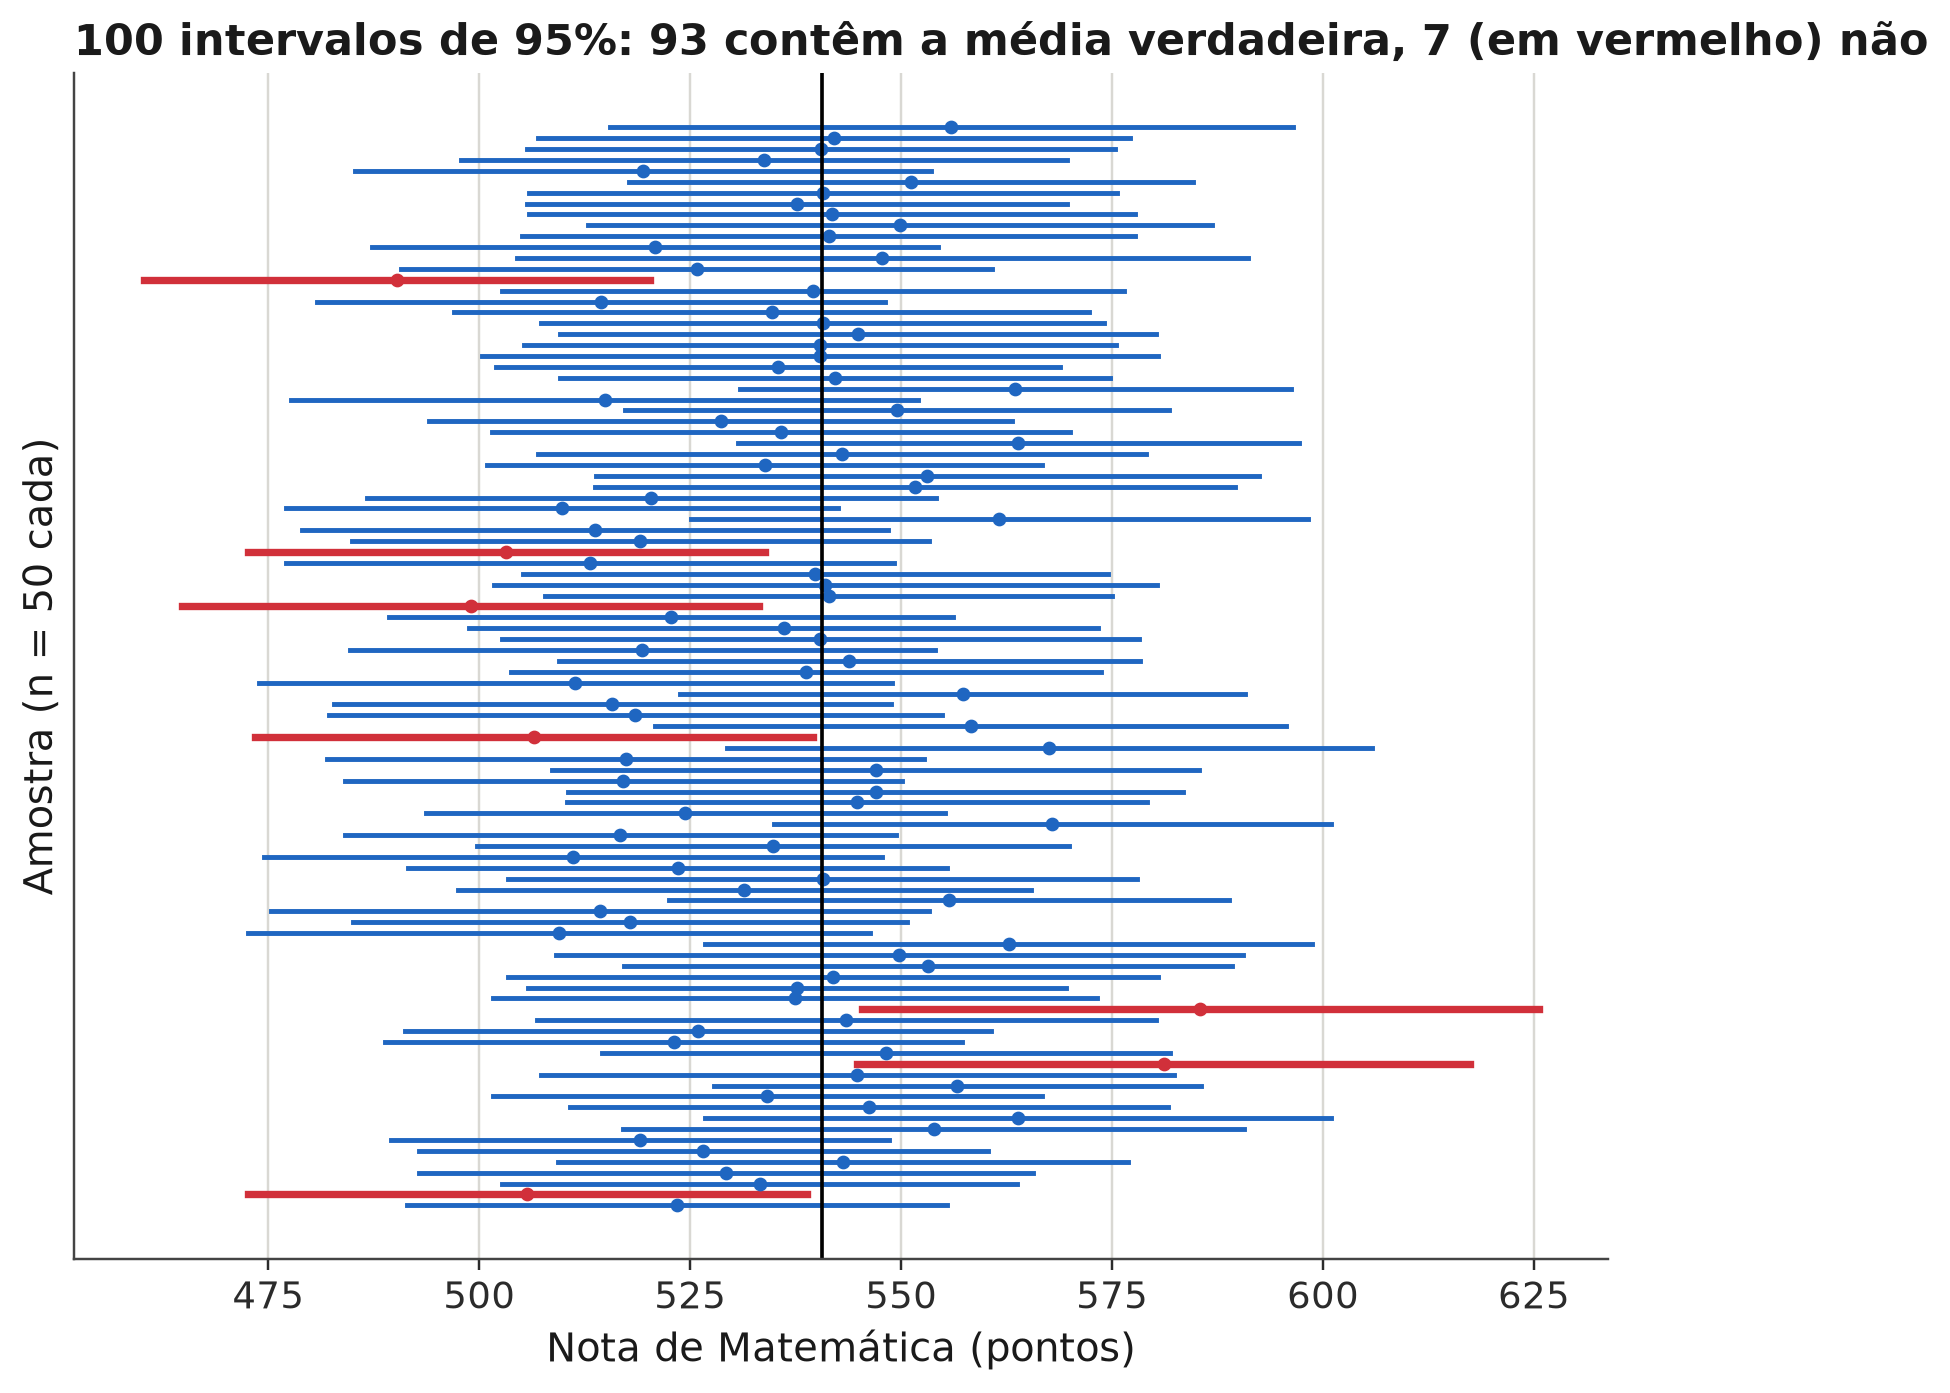

93 de 100 intervalos contêm μ = 540,60


In [29]:
rng = np.random.default_rng(SEMENTE)                          # gerador desta seção
amostras_50 = rng.choice(mt, size=(100, 50))                  # 100 amostras de 50 (uma por linha)
intervalos = [ic_media(a) for a in amostras_50]               # (média, inferior, superior) de cada amostra
acertou = [inf <= MU <= sup for m, inf, sup in intervalos]

fig, ax = plt.subplots(figsize=(9, 7))
for i, (m, inf, sup) in enumerate(intervalos):
    cor = AZUL if acertou[i] else VERMELHO
    ax.plot([inf, sup], [i, i], color=cor, lw=1.6 if acertou[i] else 2.4)
    ax.plot(m, i, 'o', color=cor, ms=3.5)
ax.axvline(MU, color='black', lw=1.2)
ax.set_xlabel('Nota de Matemática (pontos)'); ax.set_ylabel('Amostra (n = 50 cada)'); ax.set_yticks([])
ax.set_title(f'100 intervalos de 95%: {sum(acertou)} contêm a média verdadeira, {100 - sum(acertou)} (em vermelho) não')
plt.show()
print(f'{sum(acertou)} de 100 intervalos contêm μ = {br(MU, 2)}')

**Como ler:** a média verdadeira é fixa; **o intervalo é que varia** de amostra para amostra. *Certo:* "95% dos intervalos construídos assim contêm o parâmetro." *Errado:* "há 95% de probabilidade de μ estar neste intervalo".

## 5.3 Do erro de uma média ao erro de uma diferença

O problema não é a média geral: é a **diferença** entre privada e pública. Com uma amostra de cada grupo, cada média tem o seu erro, e os dois erros se somam (em quadrado): EP da diferença = √(S₁²/n₁ + S₂²/n₂). Uma amostra estratificada de **394 por grupo** (o porquê desse n aparece na seção 6.3):

In [30]:
N_GRUPO = 394                                                 # por grupo; justificado pelo poder na seção 6.3
rng = np.random.default_rng(SEMENTE)                          # gerador desta seção (o mesmo sorteio do Ex. 1, seção 6.4)
a_pub = rng.choice(pop_pub, N_GRUPO, replace=False)
a_priv = rng.choice(pop_priv, N_GRUPO, replace=False)

dif = a_priv.mean() - a_pub.mean()
ep_dif = np.sqrt(a_priv.var(ddof=1) / N_GRUPO + a_pub.var(ddof=1) / N_GRUPO)   # erro padrão da diferença
z95 = stats.norm.ppf(0.975)                                   # 1,96
print(f'Pública: {br(a_pub.mean())} ± {br(z95 * a_pub.std(ddof=1) / np.sqrt(N_GRUPO))} | Privada: {br(a_priv.mean())} ± {br(z95 * a_priv.std(ddof=1) / np.sqrt(N_GRUPO))}')
print(f'Diferença: {br(dif)} ± {br(z95 * ep_dif)} pontos (EP da diferença = {br(ep_dif, 2)})')
print(f'IC95% da diferença: [{br(dif - z95 * ep_dif)}; {br(dif + z95 * ep_dif)}] | verdadeira: {br(DIF_POP)} → dentro? {dif - z95 * ep_dif <= DIF_POP <= dif + z95 * ep_dif}')

Pública: 501,2 ± 10,9 | Privada: 636,0 ± 12,3
Diferença: 134,8 ± 16,4 pontos (EP da diferença = 8,36)
IC95% da diferença: [118,4; 151,2] | verdadeira: 121,8 → dentro? True


**Leitura:** com 394 alunos de cada tipo de escola, a diferença estimada é de cerca de 135 pontos, com margem de ±16. A diferença verdadeira (121,8) está dentro do intervalo. O erro padrão da diferença (≈ 8,4 pontos) volta no teste t da seção 6.4.

## 5.4 O plano decide a precisão: aleatória simples × estratificada

Com o **mesmo total** de 788 alunos, dois planos. Na **aleatória simples**, sorteia-se 788 entre todos os concluintes; como a privada é cerca de 22% deles, ela recebe só uns 172, e a média dela fica imprecisa. Na **estratificada**, sorteia-se 394 em cada tipo de escola. Qual plano estima melhor a diferença?

### Prompt para a IA — aleatória simples × estratificada por tipo de escola

O prompt que levaria ao código desta seção. Ele segue o molde do curso: **Papel, Contexto, Pergunta, Tarefa, Restrições, Formato**; pede código (não números), dá o contexto e as restrições, e pede as premissas.

```text
Papel: Você é um estatístico que planeja pesquisas por amostragem.

Contexto: Arrays pop_pub e pop_priv com as notas de MT dos concluintes de 2023 de escola pública e privada (base de análise do ENEM 2023), tratados como população. Total da amostra já definido: 788 alunos.

Pergunta: Com o mesmo n total, qual plano estima com mais precisão a diferença de médias entre privada e pública: aleatória simples ou estratificada com 394 em cada tipo de escola?

Tarefa: Escreva código Python (numpy) que: (1) calcule, pela fórmula, o erro padrão da diferença nos dois planos (na aleatória simples, com o n esperado de cada grupo); (2) calcule quantos alunos a aleatória simples precisaria para igualar a precisão da estratificada; (3) confira por simulação: 2.000 amostras de cada plano (semente 2023), com o desvio padrão das 2.000 diferenças.

Restrições: Na simulação da aleatória simples, o n de cada grupo varia de amostra para amostra: não o fixe. Só o código: não execute nem mostre resultados.

Formato: Código comentado que imprima, lado a lado, fórmula e simulação; depois, duas frases sobre quando escolher cada plano.
```

**Verificação independente** (o que o analista confere depois de rodar o código que a IA escreveu):
- Os erros padrão simulados ficam perto dos da fórmula?
- Na aleatória simples, a média do n da privada fica perto de 788 × P(privada)?
- O n equivalente da aleatória simples é maior que 788.

*Só no notebook.*

In [31]:
N_TOTAL = 2 * N_GRUPO                                         # 788
P_PRIV = len(pop_priv) / (len(pop_priv) + len(pop_pub))       # fração de privada entre os concluintes
VAR_PUB, VAR_PRIV = pop_pub.var(), pop_priv.var()

def ep_diferenca(n_pub, n_priv):
    # Erro padrão da diferença de médias: √(σ₁²/n₁ + σ₂²/n₂)
    return np.sqrt(VAR_PUB / n_pub + VAR_PRIV / n_priv)

n_priv_aas = N_TOTAL * P_PRIV                                 # n esperado de privada na aleatória simples
ep_aas = ep_diferenca(N_TOTAL - n_priv_aas, n_priv_aas)
ep_est = ep_diferenca(N_GRUPO, N_GRUPO)
n_equivalente = (VAR_PUB / (1 - P_PRIV) + VAR_PRIV / P_PRIV) / ep_est ** 2   # n da aleatória simples com o mesmo EP
print(f'Aleatória simples de {N_TOTAL}: cerca de {br(n_priv_aas, 0)} de privada → EP da diferença = {br(ep_aas)} pontos')
print(f'Estratificada, {N_GRUPO} + {N_GRUPO}: EP da diferença = {br(ep_est)} pontos')
print(f'Para igualar a estratificada, a aleatória simples precisaria de cerca de {br(n_equivalente, 0)} alunos')

# Verificação por simulação (com reposição: numa população de 1 milhão, a diferença é desprezível)
rng = np.random.default_rng(SEMENTE)                          # gerador desta seção
todas = np.concatenate([pop_pub, pop_priv])
eh_priv = np.r_[np.zeros(len(pop_pub), bool), np.ones(len(pop_priv), bool)]
dif_aas, n_priv_sorteados = [], []
for _ in range(2000):
    i = rng.integers(0, len(todas), N_TOTAL)                  # aleatória simples: o n de cada grupo varia
    dif_aas.append(todas[i][eh_priv[i]].mean() - todas[i][~eh_priv[i]].mean())
    n_priv_sorteados.append(eh_priv[i].sum())
dif_est = rng.choice(pop_priv, (2000, N_GRUPO)).mean(axis=1) - rng.choice(pop_pub, (2000, N_GRUPO)).mean(axis=1)
print(f'Simulação (2.000 amostras): EP aleatória simples = {br(np.std(dif_aas, ddof=1))} | estratificada = {br(dif_est.std(ddof=1))} '
      f'| n de privada na aleatória simples: média {br(np.mean(n_priv_sorteados))}, de {min(n_priv_sorteados)} a {max(n_priv_sorteados)}')

Aleatória simples de 788: cerca de 172 de privada → EP da diferença = 10,2 pontos
Estratificada, 394 + 394: EP da diferença = 8,2 pontos
Para igualar a estratificada, a aleatória simples precisaria de cerca de 1.220 alunos
Simulação (2.000 amostras): EP aleatória simples = 10,3 | estratificada = 8,1 | n de privada na aleatória simples: média 172,1, de 132 a 216


**Leitura:** com o mesmo custo (788 entrevistas), a estratificada mede a diferença com erro menor, porque não deixa o grupo pequeno com poucos alunos. O plano decide a precisão, e isso se decide **antes** de ir a campo.

## 5.5 Tamanho da amostra: quanto custa a precisão

Quantos participantes sortear para estimar a média de MT com erro de no máximo ±5 pontos, com 95% de confiança? Da fórmula da margem, E = z · σ / √n, isola-se o n: **n = (z · σ / E)²**, com z ≈ 1,96. Como σ é desconhecido na vida real, usa-se o desvio padrão de uma **amostra-piloto**: a de 400 da seção 5.2.

Para uma **proporção** (por exemplo, o % de presentes), a margem é E = z · √(π(1 − π) / n), e daí **n = z² · π(1 − π) / E²**. Sem um palpite para π, usa-se o pior caso, π = 0,5, que dá o maior n.

### Prompt para a IA — o tamanho da amostra

O prompt que levaria ao código desta seção. Ele segue o molde do curso: **Papel, Contexto, Pergunta, Tarefa, Restrições, Formato**; pede código (não números), dá o contexto e as restrições, e pede as premissas.

```text
Papel: Você é um estatístico que planeja amostras para estimar médias e proporções.

Contexto: Quero estimar a média de MT do ENEM 2023 com 95% de confiança. Tenho uma amostra piloto de 400 participantes (array amostra, nota de MT) e a base inteira (array mt) para conferir por simulação.

Pergunta: Quantos participantes preciso para errar no máximo ±10 pontos? E ±5? E para uma proporção com ±3, ±2 e ±1,5 pontos percentuais?

Tarefa: Escreva código Python (numpy e scipy) que: (1) defina as funções n_media(sigma, E) e n_proporcao(E, p = 0,5); (2) use o DP da amostra piloto como σ; (3) calcule n para ±10 e ±5 pontos e, para a proporção (pior caso π = 0,5), para ±3, ±2 e ±1,5 p.p.; (4) confira por simulação: com o n de ±5 pontos, sorteie 2.000 amostras e conte quantas erram até 5 pontos.

Restrições: Arredonde n sempre para cima. Mostre as fórmulas em comentário. Só o código: não execute nem mostre resultados.

Formato: Código comentado; depois, uma frase para o gestor sobre o custo de reduzir o erro pela metade.
```

**Verificação independente** (o que o analista confere depois de rodar o código que a IA escreveu):
- Metade do erro, quatro vezes a amostra (n de ±5 ≈ 4 × n de ±10; n de ±1,5 p.p. ≈ 4 × n de ±3 p.p.).
- Proporção, ±3 p.p., π = 0,5: n = 1,96² × 0,25 ÷ 0,03² = 1.068.
- Na simulação, cerca de 95% das amostras erram até 5 pontos.

*Só no notebook.*

In [32]:
def n_media(sigma, E, conf=0.95):
    # n = (z · σ / E)², arredondado para cima
    z = stats.norm.ppf((1 + conf) / 2)
    return int(np.ceil((z * sigma / E) ** 2))

def n_proporcao(E, p=0.5, conf=0.95):
    # n = z² · π(1 − π) / E², arredondado para cima
    z = stats.norm.ppf((1 + conf) / 2)
    return int(np.ceil(z ** 2 * p * (1 - p) / E ** 2))

S_PILOTO = amostra.std(ddof=1)                                # desvio padrão da amostra-piloto (seção 5.2)
print(f'Desvio padrão da piloto: {br(S_PILOTO, 2)} (o verdadeiro é {br(SIGMA, 2)})')
for E in (10, ERRO_MAX):
    print(f'Média de MT com erro de ±{E} pontos: n = {br(n_media(S_PILOTO, E), 0)}')
for E_pp in (3, 2, 1.5):
    print(f'Proporção com erro de ±{br(E_pp, 1 if E_pp % 1 else 0)} p.p. (pior caso, π = 0,5): n = {br(n_proporcao(E_pp / 100), 0)}')

# Verificação por simulação: 2.000 amostras com o n de ±5; em quantas o erro ficou dentro de ±5?
rng = np.random.default_rng(SEMENTE)                          # gerador desta seção
N_PLANO = n_media(S_PILOTO, ERRO_MAX)
erros = np.abs(rng.choice(mt, size=(2000, N_PLANO)).mean(axis=1) - MU)
print(f'Com n = {br(N_PLANO, 0)}: {br(100 * (erros <= ERRO_MAX).mean())}% das 2.000 amostras erraram até 5 pontos (esperado ≈ 95%)')

Desvio padrão da piloto: 124,06 (o verdadeiro é 124,91)
Média de MT com erro de ±10 pontos: n = 592
Média de MT com erro de ±5 pontos: n = 2.366
Proporção com erro de ±3 p.p. (pior caso, π = 0,5): n = 1.068
Proporção com erro de ±2 p.p. (pior caso, π = 0,5): n = 2.401
Proporção com erro de ±1,5 p.p. (pior caso, π = 0,5): n = 4.269


Com n = 2.366: 95,2% das 2.000 amostras erraram até 5 pontos (esperado ≈ 95%)


O erro tolerável e a confiança são **decisões do gestor**: metade do erro custa quatro vezes a amostra, tanto na média (±10 → ±5 pontos) quanto na proporção (±3 → ±1,5 p.p.).

## 5.6 O n depende da pergunta: estimar × comparar

São duas perguntas diferentes, com dois tamanhos de amostra:
- **estimar** a diferença com uma margem de ±E pontos: n por grupo = z² (σ₁² + σ₂²) / E²;
- **comparar**, com 80% de chance de detectar a menor diferença relevante (o **poder**, seção 6.3): o n cresce, porque além de errar pouco é preciso não deixar passar o efeito.

Com a margem do plano (d = 0,2 ≈ 23 pontos):

In [33]:
n_estimar = int(np.ceil(z95 ** 2 * (pop_pub.var(ddof=1) + pop_priv.var(ddof=1)) / MARGEM ** 2))
n_comparar = int(np.ceil(TTestIndPower().solve_power(effect_size=D_MIN, alpha=ALFA, power=PODER)))
print(f'Estimar a diferença com margem de ±{br(MARGEM)} pontos (95%): {n_estimar} por grupo')
print(f'Comparar, com poder de {br(100 * PODER, 0)}% para d = {br(D_MIN)}: {n_comparar} por grupo')

Estimar a diferença com margem de ±23,1 pontos (95%): 193 por grupo
Comparar, com poder de 80% para d = 0,2: 394 por grupo


## 5.7 Tamanho não cura viés: a amostra só do DF

Uma amostra "de conveniência", só com participantes do DF, comparada com a aleatória do Brasil, para vários tamanhos de amostra. A faixa colorida mostra onde caem 95% das estimativas. *(Caso conceitual, fora do problema da escola.)*

### Prompt para a IA — os vieses

O prompt que levaria ao código desta seção. Ele segue o molde do curso: **Papel, Contexto, Pergunta, Tarefa, Restrições, Formato**; pede código (não números), dá o contexto e as restrições, e pede as premissas.

```text
Papel: Você é um revisor de metodologia que procura vieses antes de qualquer conclusão.

Contexto: DataFrame base (base de análise do ENEM 2023, com NU_NOTA_MT e SG_UF_PROVA) e DataFrame insc (todos os inscritos, com TP_PRESENCA_MT, Q006 e TP_ESCOLA: 2 pública, 3 privada).

Pergunta: Quando uma amostra grande ainda engana? Dois casos: ouvir só o DF; analisar só quem compareceu.

Tarefa: Escreva código Python (numpy, pandas e matplotlib) que: (1) conveniência: sorteie amostras de n = 25 a 3.200 só entre os participantes do DF e do Brasil todo, 500 por n (semente 2023), e mostre a média das estimativas e a faixa de 95% por n; (2) seleção: calcule o % de presentes em MT por faixa de renda (Q006) e por tipo de escola, entre todos os inscritos.

Restrições: Não conclua causa. Mostre sempre o n. Só o código: não execute nem mostre resultados.

Formato: Código comentado; depois, uma frase por caso dizendo o que um relatório ingênuo concluiria e por que estaria errado.
```

**Verificação independente** (o que o analista confere depois de rodar o código que a IA escreveu):
- O viés do DF = média do DF − média do Brasil, e ele não diminui com n.
- Presença: menor na faixa A (sem renda) que nas altas.
- Presença: menor entre os inscritos de escola pública que entre os de privada.

*Só no notebook.*

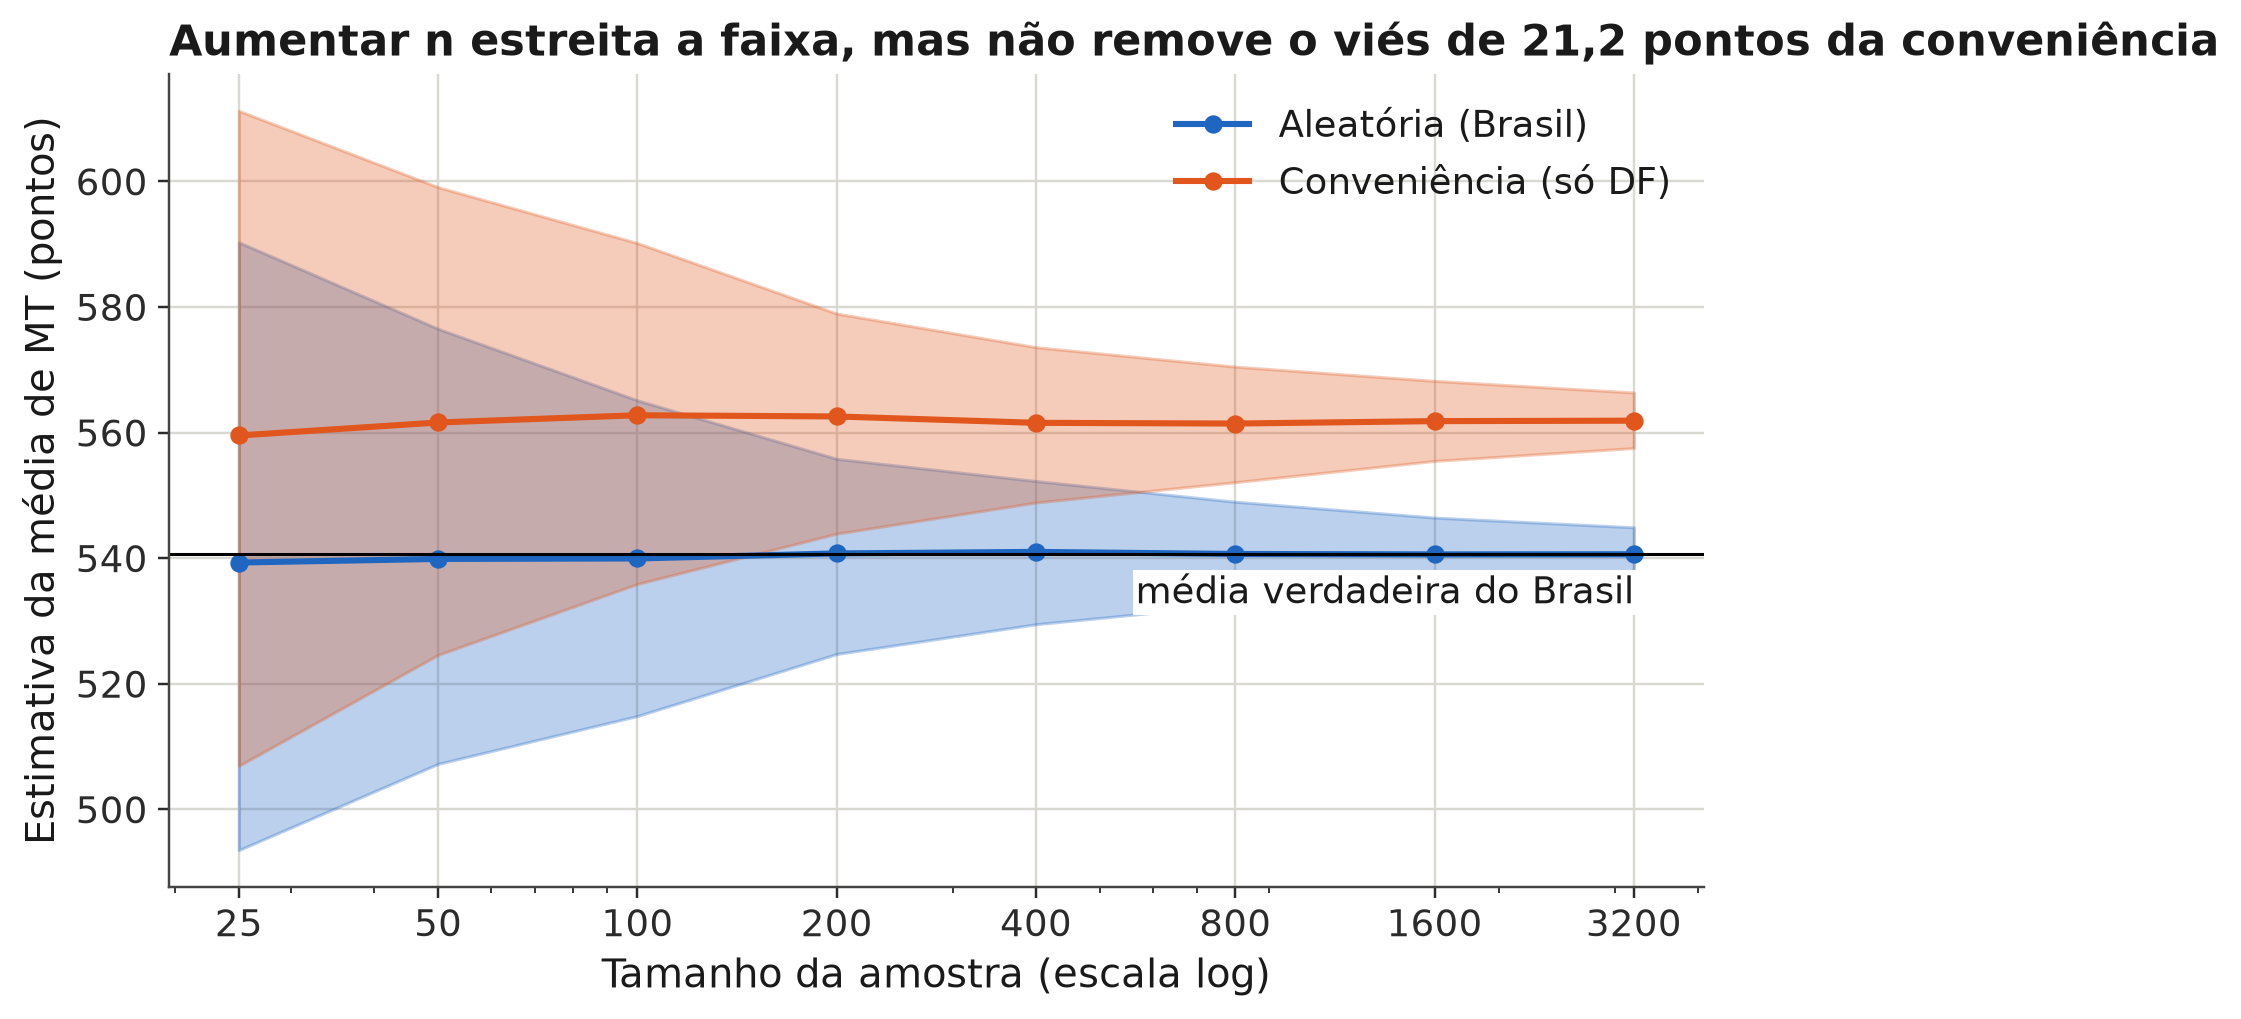

Média do DF = 561,8 | Brasil = 540,6 | viés = 21,2 pontos


In [34]:
rng = np.random.default_rng(SEMENTE)                          # gerador desta seção
mt_df = base.loc[base.SG_UF_PROVA == 'DF', 'NU_NOTA_MT'].to_numpy()
tamanhos = np.array([25, 50, 100, 200, 400, 800, 1600, 3200])
estimativas = {'Aleatória (Brasil)': [], 'Conveniência (só DF)': []}
for n in tamanhos:
    estimativas['Aleatória (Brasil)'].append(rng.choice(mt, size=(500, n)).mean(axis=1))        # 500 amostras de cada tamanho
    estimativas['Conveniência (só DF)'].append(rng.choice(mt_df, size=(500, n)).mean(axis=1))

fig, ax = plt.subplots(figsize=(9, 4.8))
for (nome, est), cor in zip(estimativas.items(), (AZUL, LARANJA)):
    est = np.array(est)
    ax.fill_between(tamanhos, np.percentile(est, 2.5, axis=1), np.percentile(est, 97.5, axis=1), color=cor, alpha=0.3)
    ax.plot(tamanhos, est.mean(axis=1), 'o-', color=cor, lw=2, ms=5, label=nome)
ax.axhline(MU, color='black', lw=1)
ax.text(tamanhos[-1], MU - 3, 'média verdadeira do Brasil', ha='right', va='top', fontsize=12, bbox=dict(facecolor='white', edgecolor='none', pad=1))
ax.set_xscale('log'); ax.set_xticks(tamanhos, [str(v) for v in tamanhos])
ax.set_xlabel('Tamanho da amostra (escala log)'); ax.set_ylabel('Estimativa da média de MT (pontos)')
ax.set_title(f'Aumentar n estreita a faixa, mas não remove o viés de {br(mt_df.mean() - MU)} pontos da conveniência')
ax.legend(loc='upper right')
plt.show()
print(f'Média do DF = {br(mt_df.mean())} | Brasil = {br(MU)} | viés = {br(mt_df.mean() - MU)} pontos')

## 5.8 Viés de seleção: quem comparece

A base de notas só tem quem fez a prova. Se a chance de comparecer varia entre os grupos, as médias descrevem quem compareceu, e não quem se inscreveu. Esta análise usa **todos os inscritos**.

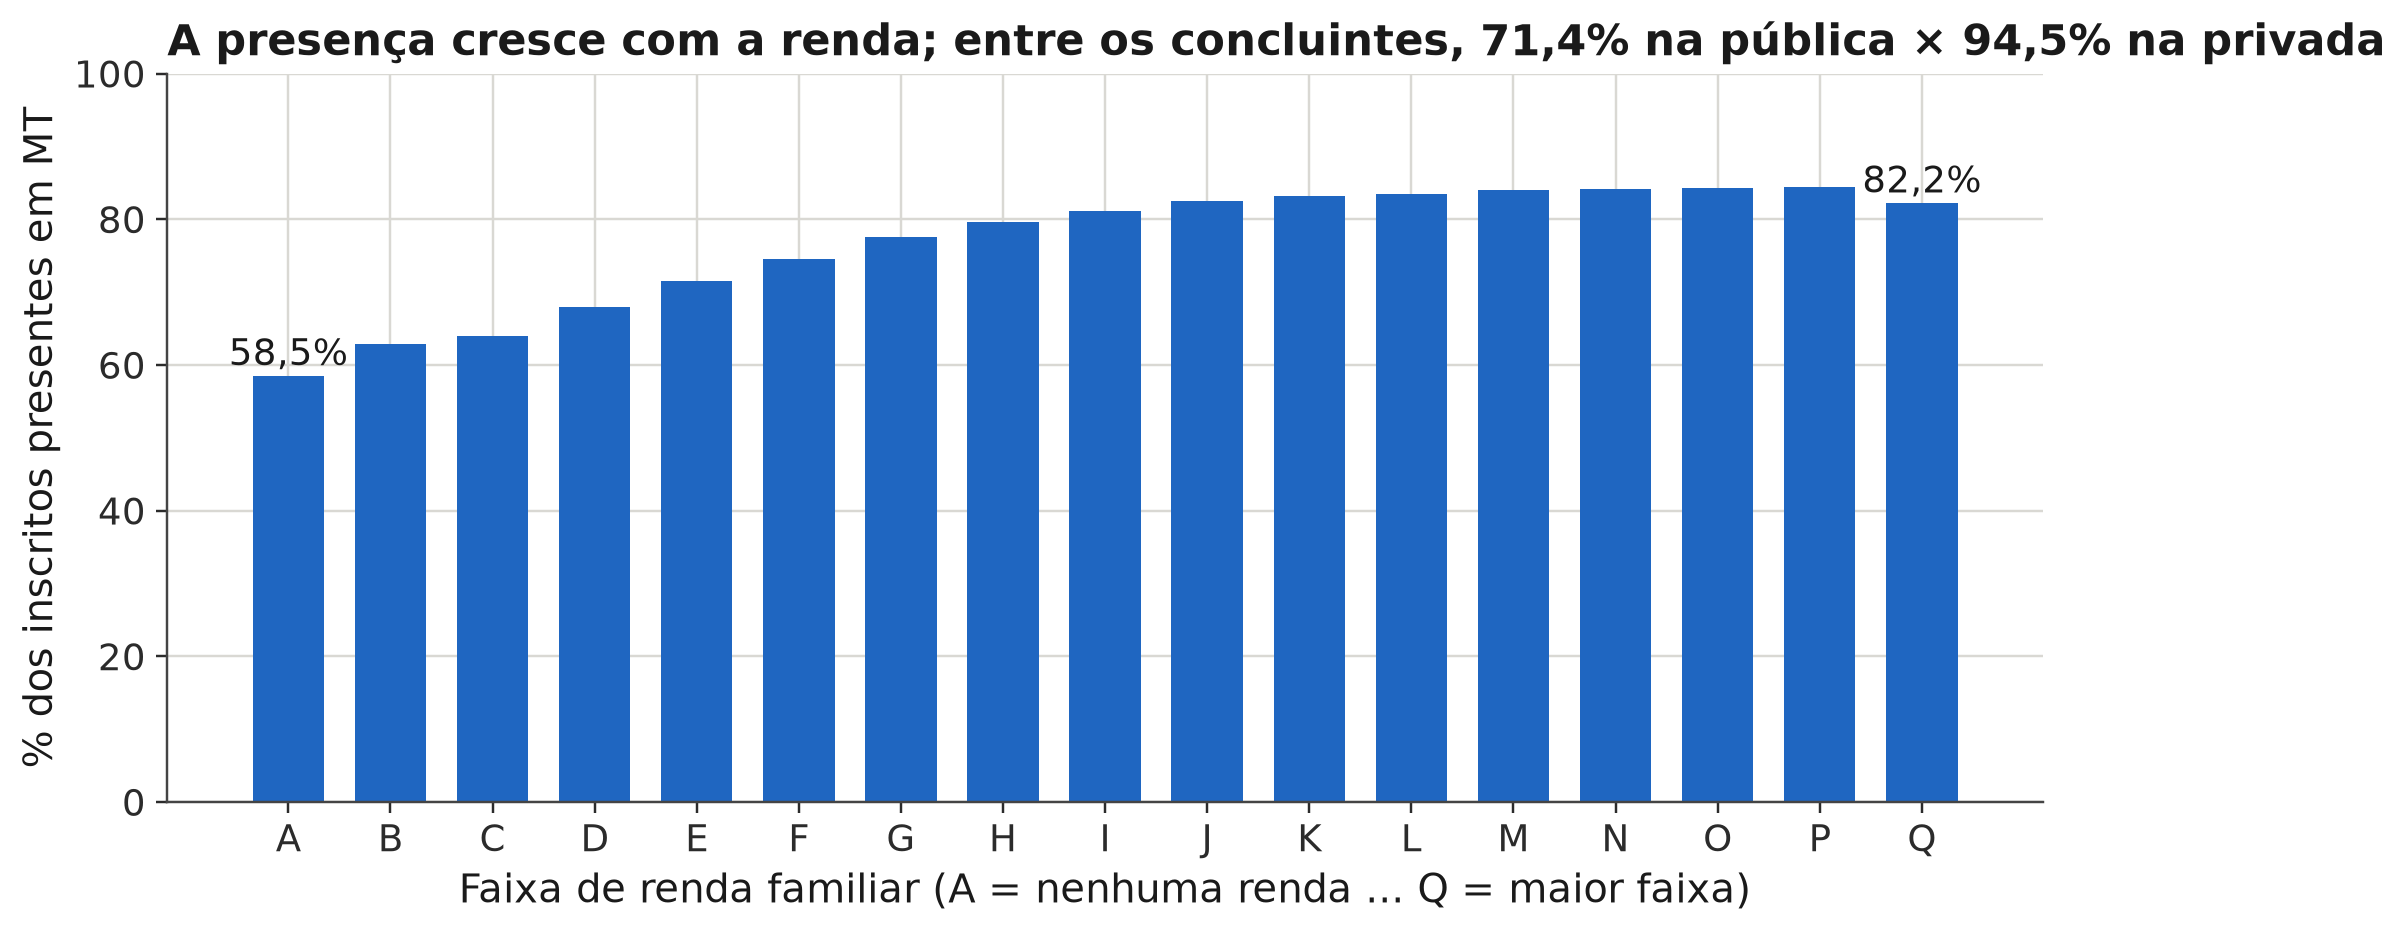

Presença em MT: faixa A = 58,5% | faixa Q = 82,2% | pública = 71,4% | privada = 94,5% (concluintes de 2023 que informaram escola)


In [35]:
presente_mt = insc.TP_PRESENCA_MT == 1
pres_renda = 100 * presente_mt.groupby(insc.Q006).mean().loc[FAIXAS_RENDA]    # % de presentes em cada faixa de renda
pres_escola = 100 * presente_mt[informou_escola].groupby(insc.TP_ESCOLA[informou_escola]).mean()

fig, ax = plt.subplots(figsize=(11, 4.3))
ax.bar(pres_renda.index, pres_renda.values, color=AZUL, width=0.7)
for i in (0, 16):
    ax.text(i, pres_renda.iloc[i] + 1.5, f'{br(pres_renda.iloc[i])}%', ha='center', fontsize=12)
ax.set_ylim(0, 100)
ax.set_xlabel('Faixa de renda familiar (A = nenhuma renda ... Q = maior faixa)')
ax.set_ylabel('% dos inscritos presentes em MT')
ax.set_title(f'A presença cresce com a renda; entre os concluintes, {br(pres_escola[2])}% na pública × {br(pres_escola[3])}% na privada')
plt.show()
print(f'Presença em MT: faixa A = {br(pres_renda.iloc[0])}% | faixa Q = {br(pres_renda.iloc[-1])}% | '
      f'pública = {br(pres_escola[2])}% | privada = {br(pres_escola[3])}% (concluintes de 2023 que informaram escola)')

**Leitura:** a presença cresce com a renda e é bem menor entre os inscritos de escola pública. As notas sub-representam justamente quem mais falta. É provável, mas não verificável (não temos a nota de quem faltou), que a diferença entre **inscritos** de pública e privada seja maior que a medida na base.

---
# Parte 6 — Testes de hipóteses

> *A diferença é real, e importa? E entre as quatro dependências administrativas?* Um teste de hipóteses responde a uma única pergunta: **se não houvesse diferença nenhuma, quão estranho seria o que eu observei?** Não responde se a diferença é grande, importante ou causal.

**As hipóteses do nosso problema.** H₀ (hipótese nula): a média de MT da privada é igual à da pública. H₁: são diferentes. Bilateral, α = 0,05.

## 6.1 O valor-p: o conceito e os limites

**Valor-p:** a probabilidade de, se H₀ fosse verdadeira, obter um resultado tão ou mais distante de H₀ quanto o observado. Exemplo conceitual (Barbetta, seção 10.2): uma moeda lançada 10 vezes dá 8 caras. Se ela for honesta (H₀), quão raro é um resultado tão ou mais extremo?

In [36]:
moeda = stats.binom(10, 0.5)                                   # nº de caras em 10 lançamentos de uma moeda honesta
k = np.arange(11)
print('P(k caras), %:', ' | '.join(f'{i}: {br(100 * moeda.pmf(i))}' for i in k))
p_moeda = moeda.cdf(2) + moeda.sf(7)                           # P(X ≤ 2) + P(X ≥ 8): tão ou mais extremo, nos dois lados
print(f'Observado: 8 caras. Valor-p = P(X ≤ 2) + P(X ≥ 8) = {br(p_moeda, 3)} > {br(ALFA, 2)}: não se rejeita H₀')
print(f'Conferência pelo teste binomial do scipy: {br(stats.binomtest(8, 10, 0.5).pvalue, 3)}')

P(k caras), %: 0: 0,1 | 1: 1,0 | 2: 4,4 | 3: 11,7 | 4: 20,5 | 5: 24,6 | 6: 20,5 | 7: 11,7 | 8: 4,4 | 9: 1,0 | 10: 0,1
Observado: 8 caras. Valor-p = P(X ≤ 2) + P(X ≥ 8) = 0,109 > 0,05: não se rejeita H₀
Conferência pelo teste binomial do scipy: 0,109


**Regra:** p ≤ α, rejeita-se H₀; p > α, não se rejeita. Não rejeitar **não prova** que a moeda é honesta. E o valor-p não diz a probabilidade de H₀ ser verdadeira, nem o tamanho ou a importância da diferença; com n grande, quase tudo dá p pequeno (seção 6.5).

## 6.2 Os dois erros

O teste pode errar de dois jeitos: **erro tipo I** (rejeitar H₀ verdadeira: um falso positivo, com chance α) e **erro tipo II** (não rejeitar H₀ falsa: um falso negativo, com chance β). No problema: o tipo I seria anunciar uma diferença entre as escolas que não existe; o tipo II, deixar de ver uma que existe. O α é fixado no plano; o β depende do **tamanho da amostra**.

## 6.3 Poder, efeito e tamanho da amostra

**Poder** = 1 − β: a chance de o teste detectar uma diferença do tamanho mínimo relevante, se ela existir. Depende do tamanho do efeito, de n, da variabilidade e de α. `TTestIndPower().solve_power` resolve a equação do poder: quantos por grupo para ter 80% de chance de detectar d = 0,2?

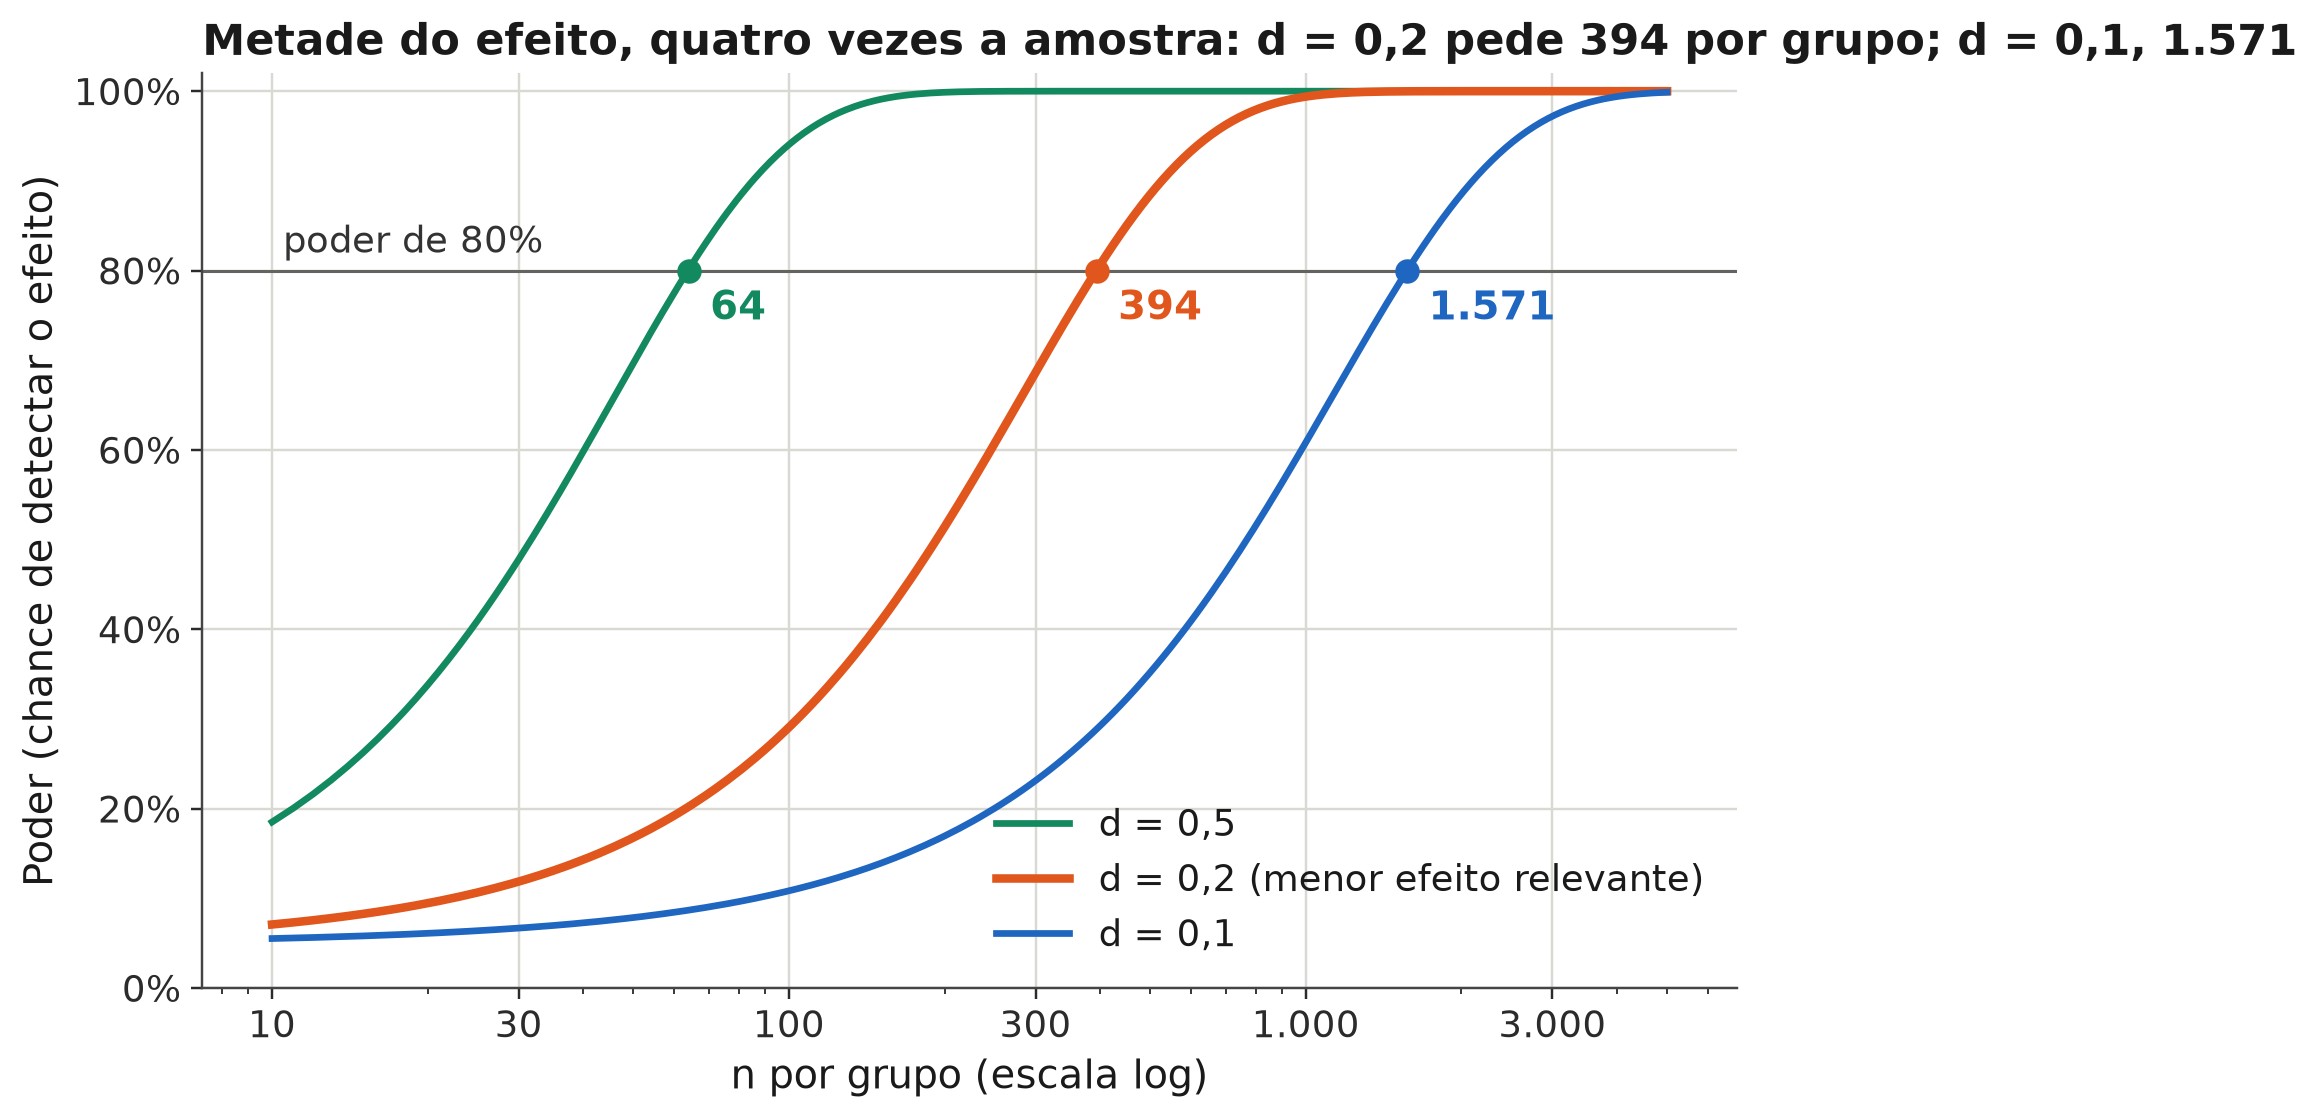

n por grupo para poder de 80% (α = 0,05, bilateral): d = 0,5 → 64 | d = 0,2 → 394 | d = 0,1 → 1.571
É o n da amostra da seção 5.3? True


In [37]:
analise_poder = TTestIndPower()
ns_poder = np.unique(np.round(np.logspace(1, np.log10(5000), 200)).astype(int))
fig, ax = plt.subplots(figsize=(9, 5.4))
n_alvos = {}
for d_alvo, cor, lw, rotulo in ((0.5, VERDE, 2.2, 'd = 0,5'), (0.2, LARANJA, 2.8, 'd = 0,2 (menor efeito relevante)'),
                                (0.1, AZUL, 2.2, 'd = 0,1')):
    poder_n = analise_poder.power(effect_size=d_alvo, nobs1=ns_poder, alpha=ALFA)
    poder_n = np.where(np.isnan(poder_n), 1.0, poder_n)      # o statsmodels devolve NaN onde o poder já é ≈ 100%
    ax.plot(ns_poder, poder_n, color=cor, lw=lw, label=rotulo)
    n_alvos[d_alvo] = int(np.ceil(analise_poder.solve_power(effect_size=d_alvo, alpha=ALFA, power=PODER)))
    ax.plot([n_alvos[d_alvo]], [PODER], 'o', color=cor, ms=7, zorder=4)
    ax.annotate(br(n_alvos[d_alvo], 0), (n_alvos[d_alvo], PODER), xytext=(7, -16), textcoords='offset points',
                fontsize=13, color=cor, fontweight='bold')
ax.axhline(PODER, color=CINZA, lw=1)
ax.text(10.5, 0.82, 'poder de 80%', fontsize=12, color='#333333')
ax.set_xscale('log')
ax.set_xticks([10, 30, 100, 300, 1000, 3000], ['10', '30', '100', '300', '1.000', '3.000'])
ax.set_ylim(0, 1.02)
ax.set_yticks([0, 0.2, 0.4, 0.6, 0.8, 1.0], ['0%', '20%', '40%', '60%', '80%', '100%'])
ax.set_xlabel('n por grupo (escala log)'); ax.set_ylabel('Poder (chance de detectar o efeito)')
ax.set_title(f'Metade do efeito, quatro vezes a amostra: d = 0,2 pede {br(n_alvos[0.2], 0)} por grupo; d = 0,1, {br(n_alvos[0.1], 0)}')
ax.legend(loc='lower right', fontsize=12)
plt.show()
print(f'n por grupo para poder de 80% (α = 0,05, bilateral): d = 0,5 → {n_alvos[0.5]} | d = 0,2 → {n_alvos[0.2]} | d = 0,1 → {br(n_alvos[0.1], 0)}')
print('É o n da amostra da seção 5.3?', n_alvos[0.2] == N_GRUPO)

Planeje o n **antes**. Nunca use o "poder observado" (calculado depois, com o efeito da própria amostra): ele não acrescenta nada ao valor-p.

## 6.4 Como ler o resultado: o intervalo contra a margem de relevância

O valor-p diz se a diferença é distinguível de zero; o **IC95% da diferença**, lido contra a **margem de relevância** (o d = 0,2 do plano, em pontos), diz se ela **importa**. São cinco leituras possíveis; a função `classificar` escreve a regra uma vez só:
- IC **inteiro além** da margem → **diferença relevante**;
- IC **inteiro dentro** da margem → **equivalente na prática** (ou **diferente, mas irrelevante**, se não incluir o zero);
- IC que não inclui o zero, mas cruza a margem → **diferente; relevância incerta**;
- IC que inclui o zero e cruza a margem → **inconclusivo** (p > 0,05 **não** prova igualdade).

In [38]:
def classificar(inf, sup, margem):
    # inf e sup: limites do IC95% da diferença; margem: menor diferença relevante (em pontos)
    if inf > margem or sup < -margem:
        return 'diferença relevante'
    if -margem < inf and sup < margem:
        return 'diferente, mas irrelevante' if (inf > 0 or sup < 0) else 'equivalente na prática'
    if inf > 0 or sup < 0:
        return 'diferente; relevância incerta'
    return 'inconclusivo'

# Conferência da regra com cinco intervalos de exemplo (margem de 10)
for ic_ex in ((15, 30), (-4, 6), (2, 8), (3, 25), (-5, 25)):
    print(ic_ex, '→', classificar(*ic_ex, 10))

(15, 30) → diferença relevante
(-4, 6) → equivalente na prática
(2, 8) → diferente, mas irrelevante
(3, 25) → diferente; relevância incerta
(-5, 25) → inconclusivo


**O caminho de um teste, em seis passos** (slide 68), percorrido nos três exemplos:
1. **pergunta e hipóteses**;
2. **menor efeito relevante** (a margem);
3. **amostra**: n pelo poder e sorteio;
4. **pressupostos**: conferidos na amostra;
5. **teste**: estatística e valor-p;
6. **leitura e relato**: efeito, IC contra a margem, limitações.

| | Ex. 1 | Ex. 2 | Ex. 3 |
|---|---|---|---|
| Pergunta | MT difere entre pública e privada? | MT difere entre federal, estadual, municipal e privada? | Tipo de escola e renda familiar estão associados? |
| Teste | t de Welch | ANOVA + Tukey | qui-quadrado |
| Menor efeito relevante | d = 0,2 | d = 0,2 | V de Cramér = 0,1 |

## 6.5 Ex. 1 — Pública × privada em Matemática (teste t de Welch)

### Prompt para a IA — o Ex. 1 (teste t)

O prompt que levaria ao código desta seção. Ele segue o molde do curso: **Papel, Contexto, Pergunta, Tarefa, Restrições, Formato**; pede código (não números), dá o contexto e as restrições, e pede as premissas.

```text
Papel: Você é um estatístico revisando uma análise para gestores públicos.

Contexto: DataFrame base com a base de análise do ENEM 2023, tratada como população. Colunas: NU_NOTA_MT e TP_ESCOLA (2 pública, 3 privada; 1 = não respondeu, fora da análise). Dados observacionais, sem sorteio de quem estuda onde.

Pergunta: A nota média de MT difere entre públicas e privadas? H0: médias iguais; bilateral; α = 0,05; menor efeito relevante: d = 0,2.

Tarefa: Escreva código Python (numpy, scipy e statsmodels) que: (1) converta d = 0,2 em pontos de MT e calcule o n por grupo para poder de 80% (TTestIndPower); (2) sorteie esse n em cada grupo, sem reposição (semente 2023), e cheque os pressupostos; (3) rode o t de Welch (ttest_ind com equal_var=False) e calcule a diferença, o IC95% e o d de Cohen, classificando o IC contra a margem; (4) faça um controle negativo: embaralhe o grupo 1.000 vezes e conte quantos p < 0,05.

Restrições: Não use "poder observado". Não escreva "prova", "causa" nem "efeito da escola". Só o código: não execute nem mostre resultados.

Formato: Suposições e como checá-las; código comentado; como ler cada saída, inclusive se p > 0,05.
```

**Verificação independente** (o que o analista confere depois de rodar o código que a IA escreveu):
- n por grupo = 394 (o mesmo para qualquer par com d = 0,2, poder de 80%, α = 0,05).
- Sorteados só entre TP_ESCOLA 2 ou 3, sem repetição.
- t refeito à mão: diferença ÷ √(s₁²/n₁ + s₂²/n₂).
- Controle negativo: cerca de 5% de p < 0,05 com os rótulos embaralhados.
- O IC da amostra contém a diferença verdadeira da população?

*Nos slides: Parte 6, slide 73.*

> **Demonstração na palestra.** O Ex. 1 inteiro, do sorteio dos 394 por grupo ao controle negativo.

**Passo 1 — Pergunta e hipóteses.** H₀: média(privada) = média(pública); H₁: são diferentes; α = 0,05, bilateral. População: concluintes de 2023 da base de análise que informaram o tipo de escola.

**Passo 2 — Menor efeito relevante.** d = 0,2, convertido em pontos de MT na seção 3.6.

**Passo 3 — Amostra.** O n pelo poder (seção 6.3) e o sorteio **separado em cada grupo** (estratificado): os dois grupos ficam com o n planejado, mesmo a privada sendo bem menor. É o mesmo sorteio da seção 5.3.

In [39]:
n_ex1 = int(np.ceil(TTestIndPower().solve_power(effect_size=D_MIN, alpha=ALFA, power=PODER)))
rng = np.random.default_rng(SEMENTE)                                   # gerador desta seção (mesmo sorteio da seção 5.3)
a_pub = rng.choice(pop_pub, n_ex1, replace=False)
a_priv = rng.choice(pop_priv, n_ex1, replace=False)
print(f'Margem de relevância: d = 0,2 ≈ ±{br(MARGEM)} pontos | n por grupo: {n_ex1}')

Margem de relevância: d = 0,2 ≈ ±23,1 pontos | n por grupo: 394


**Passo 4 — Pressupostos.** O **t de Welch** compara a diferença das médias com o erro padrão dela (seção 5.3): t = diferença ÷ EP. Ele supõe (a) **independência**: sorteio, cada aluno uma vez; (b) **médias aproximadamente normais**: com n = 394, o TCL garante (seção 4.3), mesmo com alguma assimetria; e (c) **nada sobre as variâncias**: ao contrário do t "clássico", o de Welch não exige que sejam iguais. O que a amostra mostra:

In [40]:
for nome, a in (('Pública', a_pub), ('Privada', a_priv)):
    print(f'{nome}: média {br(a.mean())}, dp {br(a.std(ddof=1))}, assimetria {br(stats.skew(a), 2)}')
razao_var = max(a_pub.var(ddof=1), a_priv.var(ddof=1)) / min(a_pub.var(ddof=1), a_priv.var(ddof=1))
print(f'Maior variância ÷ menor = {br(razao_var, 2)} (o t de Welch não exige variâncias iguais)')

Pública: média 501,2, dp 110,1, assimetria 0,56
Privada: média 636,0, dp 124,1, assimetria -0,34
Maior variância ÷ menor = 1,27 (o t de Welch não exige variâncias iguais)


**Passos 5 e 6 — O teste, o efeito e a leitura.**

In [41]:
teste = stats.ttest_ind(a_priv, a_pub, equal_var=False)                # t de Welch
ic = teste.confidence_interval(0.95)                                   # IC95% da diferença de médias
dif = a_priv.mean() - a_pub.mean()
print(f'Privada − pública: {br(dif)} pontos; IC95% [{br(ic.low)}; {br(ic.high)}]; t = {br(teste.statistic, 2)}; '
      f'p {fmt_p(teste.pvalue)}; d = {br(d_cohen(a_priv, a_pub), 2)}')
print(f'Leitura contra a margem de ±{br(MARGEM)} pontos: {classificar(ic.low, ic.high, MARGEM)}')

Privada − pública: 134,8 pontos; IC95% [118,4; 151,2]; t = 16,13; p < 0,001; d = 1,15
Leitura contra a margem de ±23,1 pontos: diferença relevante


In [42]:
# Verificação independente 1: o t refeito à mão
ep_dif = np.sqrt(a_priv.var(ddof=1) / n_ex1 + a_pub.var(ddof=1) / n_ex1)   # erro padrão da diferença
print(f't à mão = {br(dif, 2)} ÷ {br(ep_dif, 2)} = {br(dif / ep_dif, 2)} (scipy: {br(teste.statistic, 2)})')

# Verificação independente 2: o valor verdadeiro (que, na vida real, não teríamos)
print(f'Diferença verdadeira na população = {br(DIF_POP)} pontos (d = {br(D_POP, 2)}); está no IC da amostra? {ic.low <= DIF_POP <= ic.high}')

# Verificação independente 3: controle negativo. Embaralhando os rótulos "pública/privada", não há diferença real;
# o teste deve dar p < 0,05 em cerca de 5% das vezes (a taxa de falso positivo prometida por α)
rng = np.random.default_rng(SEMENTE)                                   # gerador desta seção
todas_ex1 = np.concatenate([a_priv, a_pub])
falsos = 0
for _ in range(1000):
    rotulo = rng.permutation(len(todas_ex1)) < n_ex1                   # metade sorteada como "privada"
    falsos += stats.ttest_ind(todas_ex1[rotulo], todas_ex1[~rotulo], equal_var=False).pvalue < 0.05
print(f'Controle negativo: {br(100 * falsos / 1000)}% de p < 0,05 com rótulos embaralhados (esperado ≈ 5%)')

t à mão = 134,77 ÷ 8,36 = 16,13 (scipy: 16,13)
Diferença verdadeira na população = 121,8 pontos (d = 1,09); está no IC da amostra? True


Controle negativo: 4,4% de p < 0,05 com rótulos embaralhados (esperado ≈ 5%)


**Relato.** Na amostra planejada, a média de MT da privada fica cerca de 135 pontos acima da da pública, com o IC95% **inteiro acima** da margem de relevância: **diferença relevante**, grande pela régua de Cohen. *Limitações:* compara só concluintes de 2023 que informaram a escola e fizeram a prova inteira (seções 2.6 e 5.8); é observacional: a diferença mistura renda, capital cultural e seleção de alunos (seção 3.7). Não é "o efeito da escola privada".

## 6.6 Ex. 2 — As quatro dependências administrativas (ANOVA + Tukey)

"Escola pública" junta federais, estaduais e municipais. A média de MT difere entre as **quatro dependências** (federal, estadual, municipal, privada)?

**Por que não seis testes t: quem procura, acha.** Quatro grupos formam 6 pares. Sem diferença nenhuma, cada teste a 5% tem 1 chance em 20 de dar "significativo"; com muitas comparações, algum falso positivo aparece quase sempre. Demonstração: 100 testes entre duas metades **sorteadas** da mesma população.

In [43]:
rng = np.random.default_rng(SEMENTE)                                   # gerador desta seção
ps = []
for _ in range(100):
    idx = rng.choice(len(mt), 1000, replace=False)                     # 1.000 participantes sorteados...
    ps.append(stats.ttest_ind(mt[idx[:500]], mt[idx[500:]], equal_var=False).pvalue)   # ...divididos em duas metades
ps = np.array(ps)
print(f'p < 0,05 em {(ps < 0.05).sum()} de 100 testes, sem diferença real nenhuma | com Bonferroni (α ÷ 100): {(ps < 0.05 / 100).sum()}')

p < 0,05 em 5 de 100 testes, sem diferença real nenhuma | com Bonferroni (α ÷ 100): 0


Por isso, primeiro um teste único para os quatro grupos, a **ANOVA** (análise de variância): se as médias fossem iguais, a variação **entre** os grupos seria parecida com a variação **dentro** deles. A razão entre as duas é a estatística **F**; F muito maior que 1 indica que pelo menos uma média difere. Depois, o pós-teste de **Tukey** diz **quais pares** diferem, já ajustado para as 6 comparações.

### Prompt para a IA — o Ex. 2 (ANOVA e Tukey)

O prompt que levaria ao código desta seção. Ele segue o molde do curso: **Papel, Contexto, Pergunta, Tarefa, Restrições, Formato**; pede código (não números), dá o contexto e as restrições, e pede as premissas.

```text
Papel: Você é um estatístico revisando uma análise para gestores públicos.

Contexto: DataFrame base com a base de análise do ENEM 2023, tratada como população. Colunas: NU_NOTA_MT e TP_DEPENDENCIA_ADM_ESC (1 federal, 2 estadual, 3 municipal, 4 privada; vazia para quem não informou). Vou sortear o mesmo número de participantes em cada dependência, com semente 2023.

Pergunta: A média de MT difere entre as quatro dependências? H0: as quatro médias são iguais; α = 0,05; menor efeito relevante: d = 0,2 entre duas dependências.

Tarefa: Escreva código Python (scipy e statsmodels) que: (1) converta d = 0,2 em pontos (DP dentro dos grupos) e calcule o n por grupo com α = 0,05/6 (6 pares; TTestIndPower); (2) sorteie esse n em cada grupo e cheque as suposições; (3) rode a ANOVA (f_oneway) e monte a tabela completa: somas de quadrados, g.l., variâncias estimadas, razão F, valor-p e η²; (4) rode o Tukey (pairwise_tukeyhsd) e classifique o IC95% de cada par contra a margem.

Restrições: Não chame de "equivalentes" os pares com p ≥ 0,05. Comente em português. Só o código: não execute nem mostre resultados.

Formato: Código comentado que imprima a tabela ANOVA e a de pares; depois, como ler cada saída e um modelo de três frases para a diretoria, com lacunas no lugar dos números.
```

**Verificação independente** (o que o analista confere depois de rodar o código que a IA escreveu):
- Os 4 grupos têm o mesmo n e só códigos 1 a 4.
- F refeito à mão: (SQ entre ÷ g.l. entre) ÷ (SQ dentro ÷ g.l. dentro).
- Razão entre a maior e a menor variância abaixo de 4 (regra prática).
- Pares com p ajustado ≥ 0,05 lidos como inconclusivos, salvo se o IC couber inteiro na margem.
- Comparar o η² da amostra com o da população.

*Nos slides: Parte 6, slide 79.*

**Passo 1 — Hipóteses.** H₀: as quatro médias são iguais; H₁: pelo menos uma difere; α = 0,05. População: quem tem a dependência informada, um subconjunto **não aleatório** dos concluintes (falta mais para a escola pública).

**Passos 2 e 3 — Menor efeito relevante e amostra.** d = 0,2, convertido em pontos com o desvio padrão **dentro** dos grupos. Como serão 6 pares, o planejamento usa α ÷ 6 em cada par (correção de **Bonferroni**), o que pede amostras maiores.

In [44]:
DEPS = ['Federal', 'Estadual', 'Municipal', 'Privada']
pop_dep = base.loc[base.TP_DEPENDENCIA_ADM_ESC.notna(), ['TP_DEPENDENCIA_ADM_ESC', 'NU_NOTA_MT']].copy()
pop_dep['dependência'] = pop_dep.TP_DEPENDENCIA_ADM_ESC.astype(int).map(ROT_DEPENDENCIA)

# Desvio padrão DENTRO dos grupos: junta as variâncias dos 4 grupos, ponderadas pelo tamanho de cada um
g = pop_dep.groupby('dependência').NU_NOTA_MT.agg(['count', 'var'])
dp_dentro = np.sqrt(((g['count'] - 1) * g['var']).sum() / (g['count'].sum() - 4))
MARGEM_EX2 = D_MIN * dp_dentro
n_ex2 = int(np.ceil(TTestIndPower().solve_power(effect_size=D_MIN, alpha=ALFA / 6, power=PODER)))
print(f'd = 0,2 ≈ ±{br(MARGEM_EX2)} pontos | α por par = 0,05 ÷ 6 = {br(ALFA / 6, 4)} | n por grupo = {n_ex2} (sem a correção: {n_ex1})')

amostra_dep = pop_dep.groupby('dependência', group_keys=False).sample(n_ex2, random_state=SEMENTE)   # n_ex2 de cada grupo

d = 0,2 ≈ ±22,5 pontos | α por par = 0,05 ÷ 6 = 0,0083 | n por grupo = 608 (sem a correção: 394)


**Passo 4 — Pressupostos.** Independência (sorteio), médias aproximadamente normais (TCL) e **variâncias parecidas** (regra prática: a maior até 4 vezes a menor; o teste de Levene é uma conferência formal).

In [45]:
display(amostra_dep.groupby('dependência').NU_NOTA_MT.agg(n='count', média='mean', dp='std').loc[DEPS].round(1))
variancias = amostra_dep.groupby('dependência').NU_NOTA_MT.var()
grupos_notas = [g.to_numpy() for _, g in amostra_dep.groupby('dependência').NU_NOTA_MT]      # lista com as notas de cada grupo
print(f'Maior variância ÷ menor = {br(variancias.max() / variancias.min(), 2)} (regra prática: até 4) | Levene: p {fmt_p(stats.levene(*grupos_notas).pvalue)}')

,n,média,dp
dependência,,,
Federal,608,604.1,120.9
Estadual,608,514.5,110.9
Municipal,608,524.9,115.5
Privada,608,628.5,121.1


Maior variância ÷ menor = 1,19 (regra prática: até 4) | Levene: p 0,150


**Passo 5 — A ANOVA, com a tabela completa.** SQ = soma de quadrados (variação); g.l. = graus de liberdade; a "variância estimada" é SQ ÷ g.l.; F = variância entre ÷ variância dentro. O **η²** (eta ao quadrado) = SQ entre ÷ SQ total: a fração da variação das notas que acompanha os grupos.

In [46]:
def eta2(notas, grupos):
    # Fração da variação total das notas que está ENTRE as médias dos grupos
    d = pd.DataFrame({'nota': np.asarray(notas, dtype=float), 'grupo': np.asarray(grupos)})
    media_geral = d.nota.mean()
    g = d.groupby('grupo').nota.agg(['count', 'mean'])                       # n e média de cada grupo
    variacao_entre = (g['count'] * (g['mean'] - media_geral) ** 2).sum()     # o quanto as médias dos grupos se afastam da geral
    variacao_total = ((d.nota - media_geral) ** 2).sum()                     # o quanto cada nota se afasta da geral
    return variacao_entre / variacao_total

y, grupos = amostra_dep.NU_NOTA_MT, amostra_dep['dependência']
k, N = 4, len(y)                                                       # 4 grupos, N participantes
medias = y.groupby(grupos).agg(['count', 'mean'])
sq_entre = (medias['count'] * (medias['mean'] - y.mean()) ** 2).sum() # variação das médias dos grupos em torno da geral
sq_total = ((y - y.mean()) ** 2).sum()                                 # variação de cada nota em torno da geral
sq_dentro = sq_total - sq_entre                                        # o que sobra: variação dentro dos grupos
F = (sq_entre / (k - 1)) / (sq_dentro / (N - k))
display(pd.DataFrame({'soma de quadrados': [sq_entre, sq_dentro, sq_total], 'g.l.': [k - 1, N - k, N - 1],
                      'variância estimada': [sq_entre / (k - 1), sq_dentro / (N - k), np.nan], 'F': [F, np.nan, np.nan]},
                     index=['entre grupos', 'dentro dos grupos', 'total']).round(2))
anova = stats.f_oneway(*grupos_notas)                                  # a mesma ANOVA pela biblioteca, para conferir
print(f'F = {br(F, 2)} (scipy: {br(anova.statistic, 2)}); p {fmt_p(anova.pvalue)}; F crítico (5%) = {br(stats.f.ppf(0.95, k - 1, N - k), 2)}')
print(f'η² = {br(sq_entre / sq_total, 3)} na amostra; {br(eta2(pop_dep.NU_NOTA_MT, pop_dep["dependência"]), 3)} na população')

,soma de quadrados,g.l.,variância estimada,F
entre grupos,5884732.55,3,1961577.52,142.82
dentro dos grupos,33348371.45,2428,13734.91,NaN
total,39233104.00,2431,NaN,NaN


F = 142,82 (scipy: 142,82); p < 0,001; F crítico (5%) = 2,61


η² = 0,150 na amostra; 0,210 na população


**Passo 6 — Quais pares diferem, e se importam: Tukey com a margem.** Para cada par, o Tukey dá a diferença, o IC95% (já ajustado para as 6 comparações) e o p ajustado. Cada IC é lido contra a margem com a função `classificar` (seção 6.4).

,meandiff,lower,upper,p-adj,leitura (IC × margem)
par,,,,,
Estadual × Federal,89.55,72.27,106.83,0.00,diferença relevante
Estadual × Municipal,10.37,-6.91,27.65,0.41,inconclusivo
Estadual × Privada,113.97,96.69,131.25,0.00,diferença relevante
Federal × Municipal,-79.18,-96.46,-61.90,0.00,diferença relevante
Federal × Privada,24.42,7.14,41.70,0.00,diferente; relevância incerta
Municipal × Privada,103.60,86.32,120.88,0.00,diferença relevante


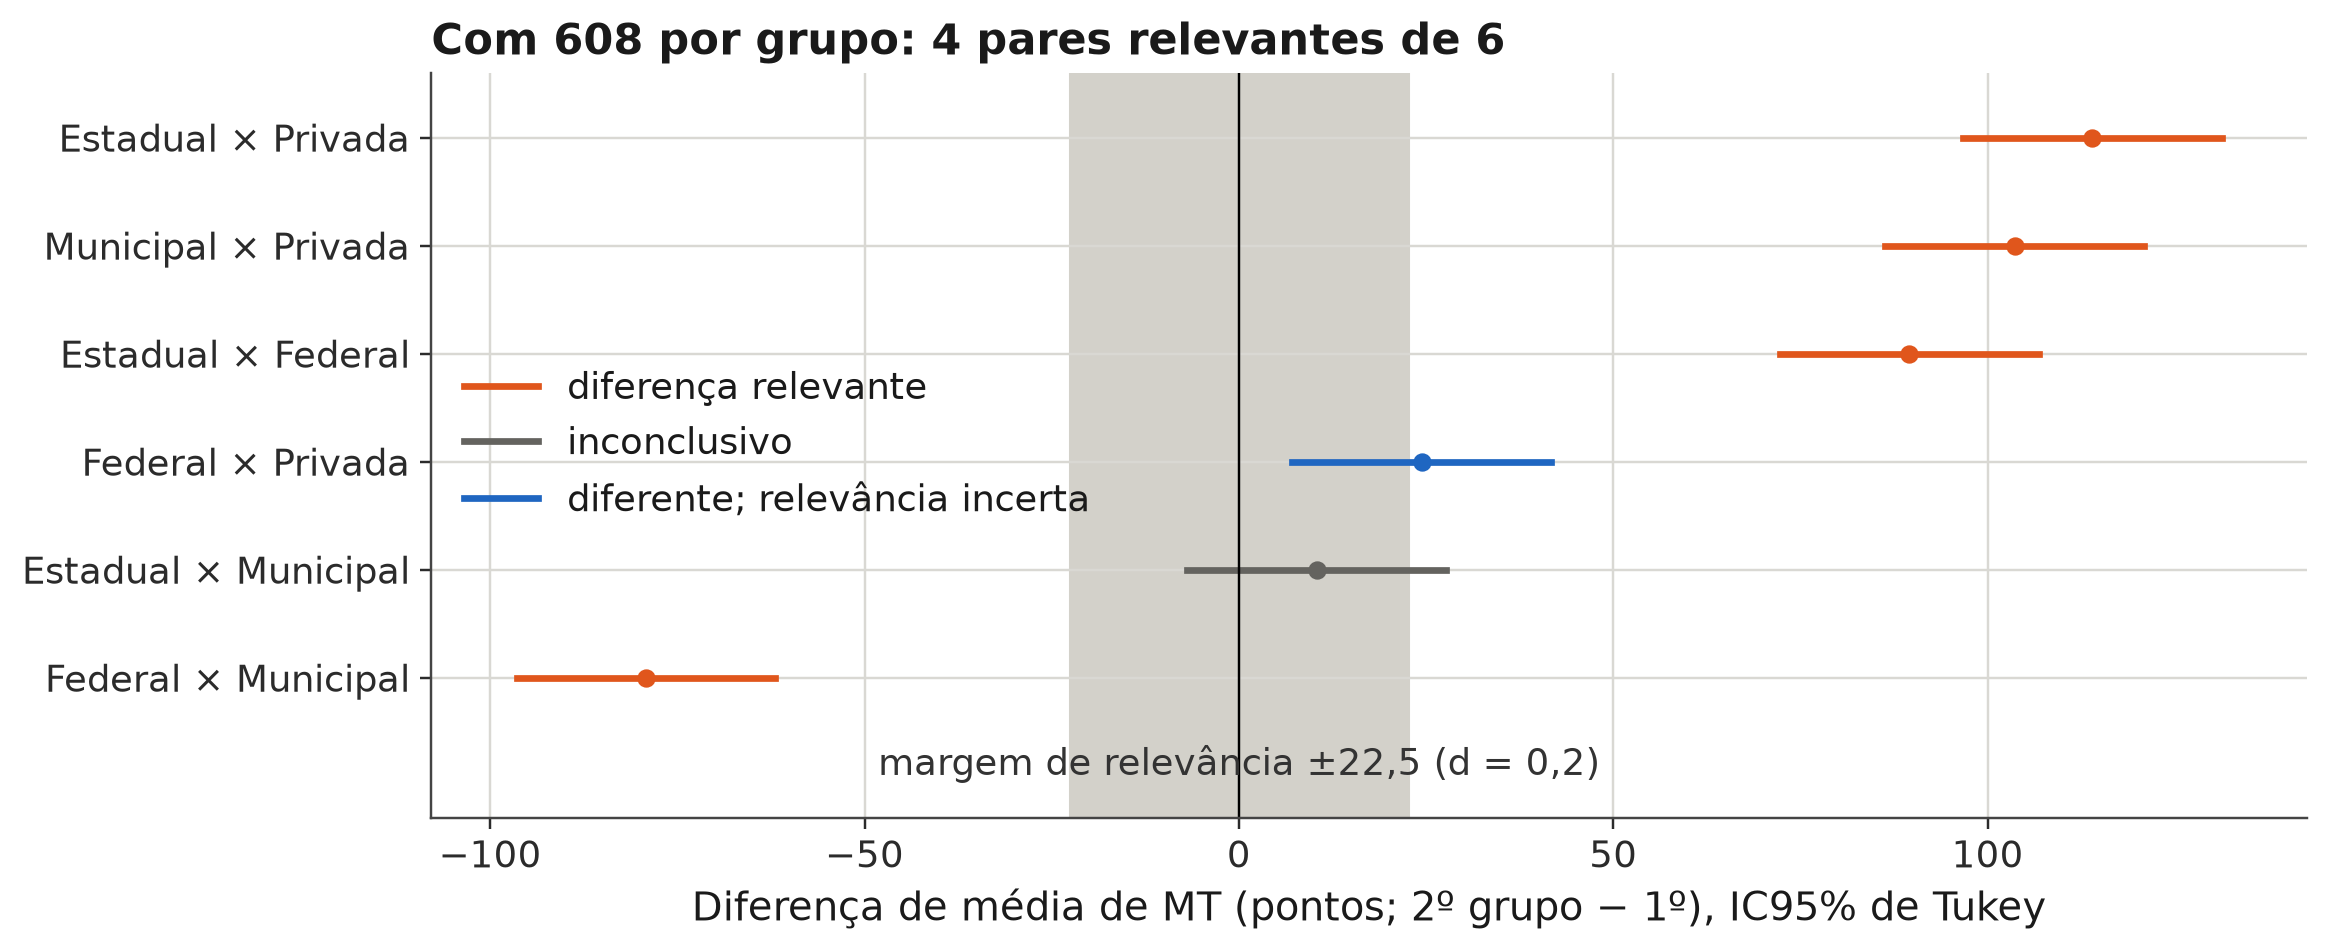

Estadual × Federal: diferença verdadeira = 95,3 pontos → acima da margem
Estadual × Municipal: diferença verdadeira = 16,3 pontos → abaixo da margem
Estadual × Privada: diferença verdadeira = 124,6 pontos → acima da margem
Federal × Municipal: diferença verdadeira = -79,0 pontos → acima da margem
Federal × Privada: diferença verdadeira = 29,2 pontos → acima da margem
Municipal × Privada: diferença verdadeira = 108,3 pontos → acima da margem


In [47]:
tk = pairwise_tukeyhsd(amostra_dep.NU_NOTA_MT, amostra_dep['dependência'], alpha=ALFA)
tukey = pd.DataFrame(tk.summary().data[1:], columns=tk.summary().data[0])       # a tabela do Tukey como DataFrame
tukey['par'] = tukey.group1 + ' × ' + tukey.group2
tukey['leitura (IC × margem)'] = [classificar(i, s, MARGEM_EX2) for i, s in zip(tukey.lower, tukey.upper)]
display(tukey.set_index('par')[['meandiff', 'lower', 'upper', 'p-adj', 'leitura (IC × margem)']].round(2))

fig, ax = plt.subplots(figsize=(11, 4.4))
t = tukey.sort_values('meandiff').reset_index(drop=True)
ax.axvspan(-MARGEM_EX2, MARGEM_EX2, color='#d3d1ca', zorder=0)           # faixa cinza: dentro da margem = irrelevante
ax.text(0, -0.9, f'margem de relevância ±{br(MARGEM_EX2)} (d = 0,2)', ha='center', fontsize=12, color='#333333')
cores = {'diferença relevante': LARANJA, 'inconclusivo': CINZA, 'equivalente na prática': VERDE,
         'diferente, mas irrelevante': VERDE, 'diferente; relevância incerta': AZUL}
for i, r in t.iterrows():
    ax.plot([r.lower, r.upper], [i, i], color=cores[r['leitura (IC × margem)']], lw=2.2)
    ax.plot(r.meandiff, i, 'o', color=cores[r['leitura (IC × margem)']], ms=5)
ax.axvline(0, color='black', lw=0.8)
ax.set_ylim(-1.3, len(t) - 0.4)
ax.set_yticks(range(len(t)), t.par)
ax.set_xlabel('Diferença de média de MT (pontos; 2º grupo − 1º), IC95% de Tukey')
ax.legend(handles=[plt.Line2D([], [], color=cores[l], lw=2.2, label=l) for l in cores if l in set(t['leitura (IC × margem)'])], loc='center left')
ax.set_title(f"Com {n_ex2} por grupo: {(t['leitura (IC × margem)'] == 'diferença relevante').sum()} pares relevantes de 6")
plt.show()

# Na população inteira (o que, na vida real, não teríamos): a leitura de cada par com a diferença verdadeira
media_pop = pop_dep.groupby('dependência').NU_NOTA_MT.mean()
for _, r in tukey.iterrows():
    dv = media_pop[r.group2] - media_pop[r.group1]
    print(f'{r.par}: diferença verdadeira = {br(dv)} pontos → {"acima" if abs(dv) > MARGEM_EX2 else "abaixo"} da margem')

**Relato.** A ANOVA rejeita H₀ com folga, e a dependência acompanha uma parte considerável da variação de MT; ainda assim, a maior parte da variação está **dentro** de cada tipo de escola. Federais e privadas ficam bem acima de estaduais e municipais. Federal × privada: diferente, com relevância incerta. Estadual × municipal: **inconclusivo**, e não "iguais". *Limitações:* subconjunto não aleatório dos concluintes; observacional.

## 6.7 O valor-p cai com n; o efeito não

O par estadual × municipal deu "inconclusivo" com 608 por grupo. Na população, a diferença entre eles é **abaixo** do relevante (d ≈ 0,15). O que acontece quando o mesmo par é testado com amostras cada vez maiores?

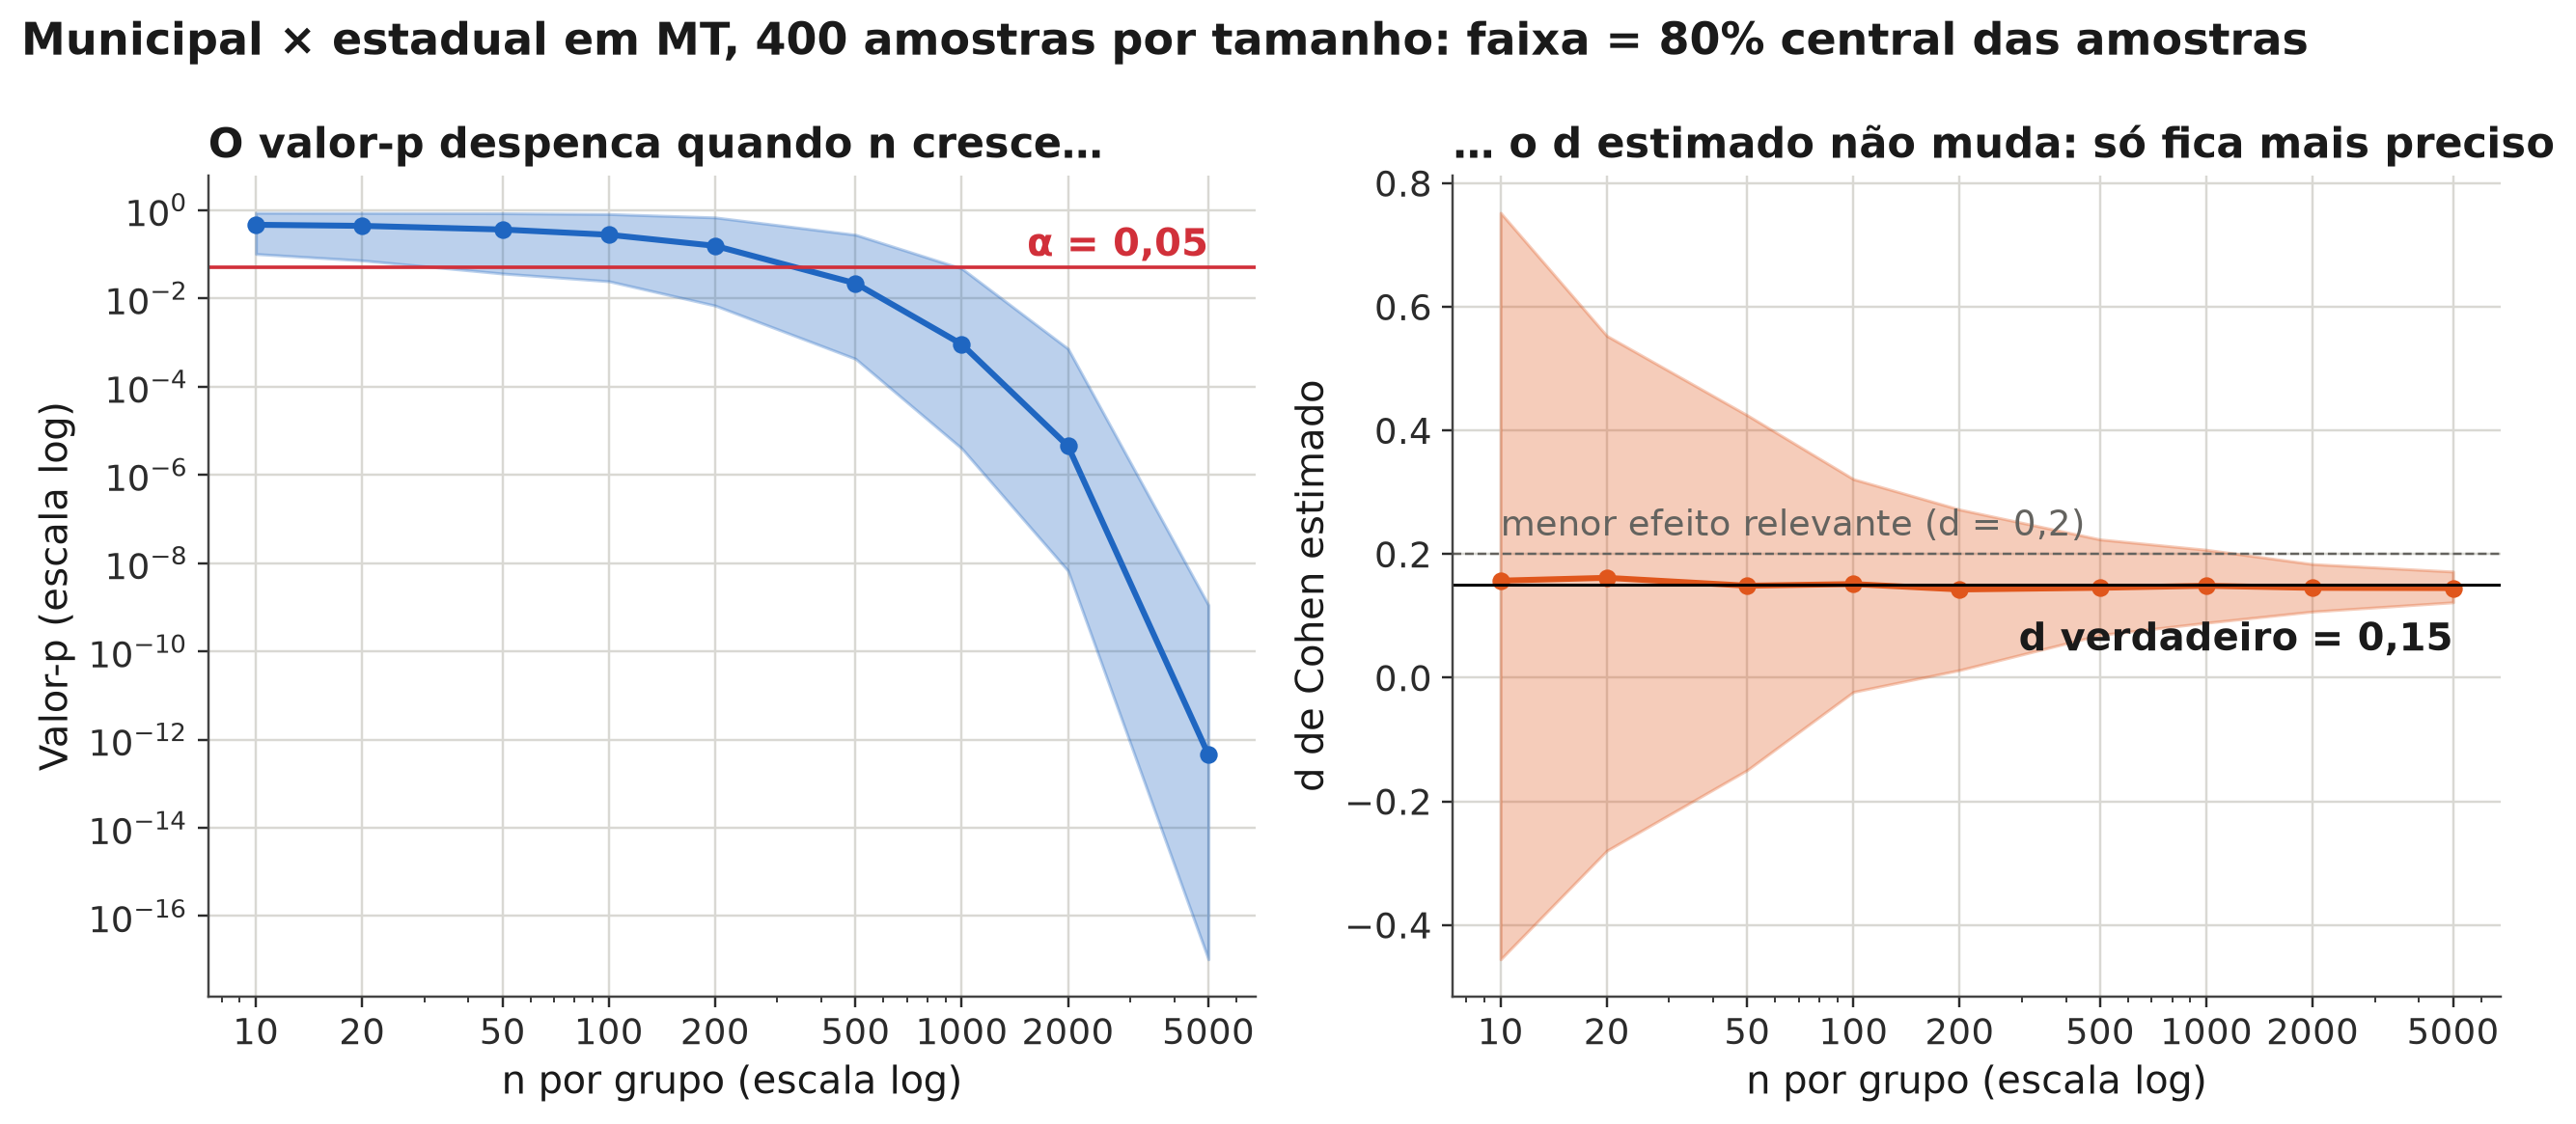

,"% com p < 0,05",p mediano
n por grupo,,
10,3.75,0.460
20,7.50,0.435
50,13.00,0.360
100,17.00,0.274
200,29.50,0.154
500,64.50,0.022
1000,90.25,0.001
2000,99.75,0.000
5000,100.00,0.000


In [48]:
rng = np.random.default_rng(SEMENTE)                                   # gerador desta seção
mt_dep = {c: base.loc[base.TP_DEPENDENCIA_ADM_ESC == c, 'NU_NOTA_MT'].to_numpy() for c in (2, 3)}
mun, est = mt_dep[3], mt_dep[2]
D_MUN_EST = d_cohen(mun, est)
ns = np.array([10, 20, 50, 100, 200, 500, 1000, 2000, 5000])
p_res, d_res, pct_sig = [], [], []
for n in ns:
    A, B = rng.choice(mun, size=(400, n)), rng.choice(est, size=(400, n))       # 400 pares de amostras de tamanho n
    p = stats.ttest_ind(A, B, axis=1, equal_var=False).pvalue                    # um teste t por par
    d = (A.mean(axis=1) - B.mean(axis=1)) / np.sqrt((A.var(axis=1, ddof=1) + B.var(axis=1, ddof=1)) / 2)
    p_res.append(p); d_res.append(d); pct_sig.append(100 * (p < 0.05).mean())
p_res, d_res = np.array(p_res), np.array(d_res)

fig, eixos = plt.subplots(1, 2, figsize=(12, 5.4))
ax = eixos[0]
ax.fill_between(ns, np.percentile(p_res, 10, axis=1), np.percentile(p_res, 90, axis=1), color=AZUL, alpha=0.3)
ax.plot(ns, np.median(p_res, axis=1), 'o-', color=AZUL, lw=2, ms=5)
ax.axhline(0.05, color=VERMELHO, lw=1.2)
ax.text(ns[-1], 0.09, 'α = 0,05', color=VERMELHO, fontsize=13, ha='right', fontweight='bold')
ax.set_xscale('log'); ax.set_yscale('log')
ax.set_xticks(ns, [str(v) for v in ns])
ax.set_xlabel('n por grupo (escala log)'); ax.set_ylabel('Valor-p (escala log)')
ax.set_title('O valor-p despenca quando n cresce…', fontsize=14)
ax = eixos[1]
ax.fill_between(ns, np.percentile(d_res, 10, axis=1), np.percentile(d_res, 90, axis=1), color=LARANJA, alpha=0.3)
ax.plot(ns, np.median(d_res, axis=1), 'o-', color=LARANJA, lw=2, ms=5)
ax.axhline(D_MUN_EST, color='black', lw=1)
ax.text(ns[-1], D_MUN_EST - 0.06, f'd verdadeiro = {br(D_MUN_EST, 2)}', va='top', ha='right', fontsize=13, fontweight='bold')   # abaixo da linha, longe do rótulo de 0,2
ax.axhline(D_MIN, color=CINZA, lw=0.8, ls='--')
ax.text(ns[0], 0.23, 'menor efeito relevante (d = 0,2)', fontsize=12, color=CINZA)
ax.set_xscale('log')
ax.set_xticks(ns, [str(v) for v in ns])
ax.set_xlabel('n por grupo (escala log)'); ax.set_ylabel('d de Cohen estimado')
ax.set_title('… o d estimado não muda: só fica mais preciso', fontsize=14)
fig.suptitle('Municipal × estadual em MT, 400 amostras por tamanho: faixa = 80% central das amostras', x=0.01, ha='left', fontweight='bold')
plt.tight_layout()
plt.show()
pd.DataFrame({'n por grupo': ns, '% com p < 0,05': pct_sig, 'p mediano': np.median(p_res, axis=1)}).set_index('n por grupo').round(3)

**Três lições:** (1) com n pequeno, uma diferença real dá "não significativo" na maioria das amostras: **p > 0,05 não prova igualdade**; (2) com n grande, tudo fica significativo, inclusive uma diferença abaixo do relevante; (3) o d estimado fica no mesmo lugar em qualquer n. Quem decide é o **tamanho do efeito**, lido contra a margem.

## 6.8 Ex. 3 — Tipo de escola × renda familiar (qui-quadrado)

A Parte 3 mostrou que renda e escola andam juntas. **Quão forte** é essa associação? Duas variáveis **categóricas** pedem outro teste: o **qui-quadrado** compara a tabela observada com a tabela **esperada** se não houvesse associação nenhuma (cada casela esperada = total da linha × total da coluna ÷ total geral). Quanto mais as duas tabelas diferem, maior o χ². A **força** da associação é medida pelo **V de Cramér**, de 0 (nenhuma) a 1 (total).

### Prompt para a IA — o Ex. 3 (qui-quadrado)

O prompt que levaria ao código desta seção. Ele segue o molde do curso: **Papel, Contexto, Pergunta, Tarefa, Restrições, Formato**; pede código (não números), dá o contexto e as restrições, e pede as premissas.

```text
Papel: Você é um estatístico revisando uma análise para gestores públicos.

Contexto: DataFrame conc com os concluintes de 2023 que informaram escola (base de análise do ENEM 2023, cerca de 1 milhão). TP_ESCOLA (2 pública, 3 privada); Q006 = renda familiar em 17 faixas (A a Q).

Pergunta: O tipo de escola e a renda familiar estão associados? H0: independência; α = 0,05; menor efeito relevante: V de Cramér = 0,1.

Tarefa: Escreva código Python (pandas, scipy e statsmodels) que: (1) agrupe Q006 em 4 faixas (A–B; C–E; F–H; I–Q); (2) rode o qui-quadrado (scipy.stats.chi2_contingency) e calcule χ², g.l., valor-p, menor esperada, V de Cramér e o % de cada faixa de renda dentro de cada tipo de escola; (3) planeje a amostra: n para V = 0,1 com poder de 80% (GofChisquarePower, w = V × √(menor dimensão da tabela − 1), 3 g.l.) e n para esperadas ≥ 5, usando o maior; (4) repita o teste nessa amostra (semente 2023).

Restrições: Confira que todas as frequências esperadas são ≥ 5. Nada de linguagem causal. Só o código: não execute nem mostre resultados.

Formato: Código comentado que imprima as tabelas; depois, como ler χ², valor-p e V na população e na amostra.
```

**Verificação independente** (o que o analista confere depois de rodar o código que a IA escreveu):
- g.l. = (2 − 1) × (4 − 1) = 3.
- Uma esperada refeita à mão: total da linha × total da coluna ÷ total geral.
- O V quase não muda entre população e amostra; o χ² cai muito.
- Na tabela 2 × 4, w = V × √1 = V: o n pelo poder sai direto do V.

*Nos slides: Parte 6, slide 83.*

**Passo 1 — Hipóteses.** H₀: tipo de escola e renda familiar são independentes; H₁: estão associados; α = 0,05. Primeiro, a "verdade" na população (os concluintes que informaram escola):

In [49]:
tab = pd.crosstab(conc.escola, conc.renda_4).loc[['Pública', 'Privada']]
qui2, p, gl, esperado = stats.chi2_contingency(tab)                  # esperado: a tabela se não houvesse associação
V_POP = stats.contingency.association(tab.to_numpy(), method='cramer')
display(tab)
display((100 * pd.crosstab(conc.escola, conc.renda_4, normalize='index')).loc[['Pública', 'Privada']].round(1))   # % de cada linha
print(f'População (n = {br(tab.to_numpy().sum(), 0)}): χ² = {br(qui2, 0)}; g.l. = {gl}; p {fmt_p(p)}; '
      f'menor esperada = {br(esperado.min(), 0)}; V de Cramér = {br(V_POP, 3)}')

# Verificação independente: uma casela esperada à mão
lin, col = 'Privada', '1) até R$ 1.320'
print(f'Esperada ({lin}; {col}) à mão = {br(tab.loc[lin].sum() * tab[col].sum() / tab.to_numpy().sum(), 1)} | '
      f'scipy = {br(esperado[tab.index.get_loc(lin), tab.columns.get_loc(col)], 1)}')

renda_4,1) até R$ 1.320,2) R$ 1.320–3.300,3) R$ 3.300–6.600,4) acima de R$ 6.600
escola,,,,
Pública,328007,301689,111004,42934
Privada,11956,44668,59944,102639


renda_4,1) até R$ 1.320,2) R$ 1.320–3.300,3) R$ 3.300–6.600,4) acima de R$ 6.600
escola,,,,
Pública,41.9,38.5,14.2,5.5
Privada,5.5,20.4,27.3,46.8


População (n = 1.002.841): χ² = 302.406; g.l. = 3; p < 0,001; menor esperada = 31.820; V de Cramér = 0,549
Esperada (Privada; 1) até R$ 1.320) à mão = 74.311,2 | scipy = 74.311,2


**Passos 2 e 3 — Menor efeito relevante e amostra.** Mínimo relevante: V = 0,1. A função de poder (`GofChisquarePower`) não recebe o V, e sim o **w de Cohen**, ligado a ele por w = V × √(menor dimensão da tabela − 1). Na tabela 2 × 4, a menor dimensão é 2, então w = V. O qui-quadrado também pede **esperadas ≥ 5** em todas as caselas; usa-se o maior dos dois n.

In [50]:
W_MIN = V_MIN * np.sqrt(min(tab.shape) - 1)                          # converte o V mínimo em w de Cohen
n_poder = int(np.ceil(GofChisquarePower().solve_power(effect_size=W_MIN, n_bins=gl + 1, alpha=ALFA, power=PODER)))
p_casela_rara = np.outer(tab.sum(axis=1), tab.sum(axis=0)).min() / tab.to_numpy().sum() ** 2   # proporção esperada da casela mais rara
n_esperadas = int(np.ceil(5 / p_casela_rara))                        # n para essa casela ter esperada ≥ 5
n_ex3 = max(n_poder, n_esperadas)
print(f'w = {br(W_MIN, 3)} | n pelo poder = {br(n_poder, 0)} | n para esperadas ≥ 5 = {n_esperadas} | n planejado = {br(n_ex3, 0)}')

w = 0,100 | n pelo poder = 1.091 | n para esperadas ≥ 5 = 158 | n planejado = 1.091


**Passos 4 a 6 — Sorteio, pressuposto, teste e leitura.** Uma amostra aleatória simples de `n_ex3` concluintes:

In [51]:
sub = conc.sample(n_ex3, random_state=SEMENTE)                       # amostra aleatória simples
tab_s = pd.crosstab(sub.escola, sub.renda_4).loc[['Pública', 'Privada']]
qui2_s, p_s, gl_s, esp_s = stats.chi2_contingency(tab_s)
V_EX3 = stats.contingency.association(tab_s.to_numpy(), method='cramer')
display(tab_s)
print(f'Amostra (n = {br(n_ex3, 0)}): χ² = {br(qui2_s, 1)}; g.l. = {gl_s}; p {fmt_p(p_s)}; V = {br(V_EX3, 3)}; '
      f'menor esperada = {br(esp_s.min(), 1)} (todas ≥ 5? {bool((esp_s >= 5).all())})')
print(f'População: χ² = {br(qui2, 0)}; V = {br(V_POP, 3)}')

renda_4,1) até R$ 1.320,2) R$ 1.320–3.300,3) R$ 3.300–6.600,4) acima de R$ 6.600
escola,,,,
Pública,371,329,118,38
Privada,12,48,63,112


Amostra (n = 1.091): χ² = 363,4; g.l. = 3; p < 0,001; V = 0,577; menor esperada = 32,3 (todas ≥ 5? True)
População: χ² = 302.406; V = 0,549


**Relato.** Tipo de escola e renda familiar estão **fortemente** associados (V bem acima do mínimo de 0,1), na população e na amostra planejada: a privada concentra as famílias de renda alta, e a pública, as de renda baixa. O χ² cai muito da população para a amostra porque **cresce com n**; o V quase não muda: é ele que mede a **força**. É por isso que a renda precisa entrar no modelo da Parte 7. *Limitações:* renda autodeclarada, em faixas; associação, não causa.

---
# Parte 7 — Regressão e o relatório

> *Quanto dos 122 pontos permanece quando levamos em conta renda, sexo e cor/raça?* Regressão transforma uma relação numa equação. Ela não prova causa.

## 7.1 Correlação e reta: duas variáveis quantitativas

A regressão se entende melhor com duas variáveis **quantitativas**, num diagrama de dispersão. O caso didático: a nota de Matemática (y) e a de Ciências da Natureza (x) dos mesmos alunos. *(Caso conceitual: não responde ao problema da escola; serve para ver a reta, o resíduo e o erro típico.)*
- O **r de Pearson** mede a força da relação **linear**, de −1 a 1.
- A **reta de mínimos quadrados**, ŷ = a + b · x, é a que deixa a menor soma dos quadrados dos resíduos. Ela sai de cinco números: **b = r × (DP de y ÷ DP de x)** e **a = ȳ − b · x̄** (a reta passa pelo ponto das duas médias).
- O **resíduo** de cada aluno é y − ŷ: o quanto a reta errou para ele. O **erro típico** de previsão é o desvio padrão dos resíduos.

### Prompt para a IA — a regressão simples

O prompt que levaria ao código desta seção. Ele segue o molde do curso: **Papel, Contexto, Pergunta, Tarefa, Restrições, Formato**; pede código (não números), dá o contexto e as restrições, e pede as premissas.

```text
Papel: Você é um estatístico revisando uma análise para gestores públicos.

Contexto: DataFrame conc com os concluintes de 2023 que informaram escola (base de análise do ENEM 2023, cerca de 1 milhão). Colunas: NU_NOTA_MT; NU_NOTA_CN; TP_ESCOLA (2 pública, 3 privada); Q006 (renda, 17 faixas ordinais A–Q). Dados observacionais.

Pergunta: Como a regressão simples resume a relação de MT com uma variável quantitativa (CN), com uma categórica (escola) e com uma ordinal (renda)?

Tarefa: Escreva código Python (numpy, scipy, statsmodels e matplotlib) que: (1) calcule o r entre MT e CN e a reta pelas fórmulas b = r × DP(y) ÷ DP(x) e a = ȳ − b · x̄, conferindo com o OLS do statsmodels; (2) calcule os resíduos, o erro típico de previsão e o R²; (3) desenhe a dispersão de 3.000 alunos sorteados (semente 2023) com a reta e um resíduo marcado; (4) crie a indicadora privada (1 = privada, 0 = pública), ajuste MT ~ privada com o IC95% do coeficiente e compare o t do coeficiente com o do teste t de variâncias iguais; (5) ajuste MT ~ renda, com a renda como código 1–17 (diga o que isso supõe).

Restrições: Não use linguagem causal. Não confie no R² sem olhar os resíduos. Só o código: não execute nem mostre resultados.

Formato: Código comentado; depois, como ler a inclinação, o intercepto, o erro típico e o R² em linguagem de gestor.
```

**Verificação independente** (o que o analista confere depois de rodar o código que a IA escreveu):
- A reta pelas fórmulas bate com a do statsmodels.
- Na regressão simples, R² = r².
- Com a indicadora, o intercepto é a média da pública e o coeficiente é a diferença privada − pública (seção 3.2).
- O t do coeficiente da privada é igual ao do teste t com variâncias iguais.

*Só no notebook.*

In [52]:
x_cn, y_mt = conc.NU_NOTA_CN.to_numpy(), conc.NU_NOTA_MT.to_numpy()
r_cn = np.corrcoef(x_cn, y_mt)[0, 1]                                  # correlação de Pearson
b_cn = r_cn * y_mt.std() / x_cn.std()                                 # inclinação: r × (DP de y ÷ DP de x)
a_cn = y_mt.mean() - b_cn * x_cn.mean()                               # intercepto: a reta passa por (x̄, ȳ)
print(f'CN: média {br(x_cn.mean())}, DP {br(x_cn.std())} | MT: média {br(y_mt.mean())}, DP {br(y_mt.std())} | r = {br(r_cn, 3)}')
print(f'b = {br(r_cn, 3)} × {br(y_mt.std())} ÷ {br(x_cn.std())} = {br(b_cn, 3)} | a = {br(y_mt.mean())} − {br(b_cn, 3)} × {br(x_cn.mean())} = {br(a_cn)}')
modelo_cn = sm.OLS(y_mt, sm.add_constant(x_cn)).fit()                 # a mesma reta pelo statsmodels
print(f'Conferência pelo statsmodels: a = {br(modelo_cn.params[0])}; b = {br(modelo_cn.params[1], 3)}')
residuo_cn = y_mt - (a_cn + b_cn * x_cn)                              # resíduo = nota real − nota prevista
erro_tipico_cn = np.sqrt((residuo_cn ** 2).sum() / (len(y_mt) - 2))   # desvio padrão dos resíduos
print(f'MT = {br(a_cn)} + {br(b_cn, 2)} × CN | erro típico de previsão = ±{br(erro_tipico_cn)} pontos')

CN: média 494,4, DP 76,8 | MT: média 537,9, DP 122,9 | r = 0,674
b = 0,674 × 122,9 ÷ 76,8 = 1,080 | a = 537,9 − 1,080 × 494,4 = 4,1
Conferência pelo statsmodels: a = 4,1; b = 1,080
MT = 4,1 + 1,08 × CN | erro típico de previsão = ±90,7 pontos


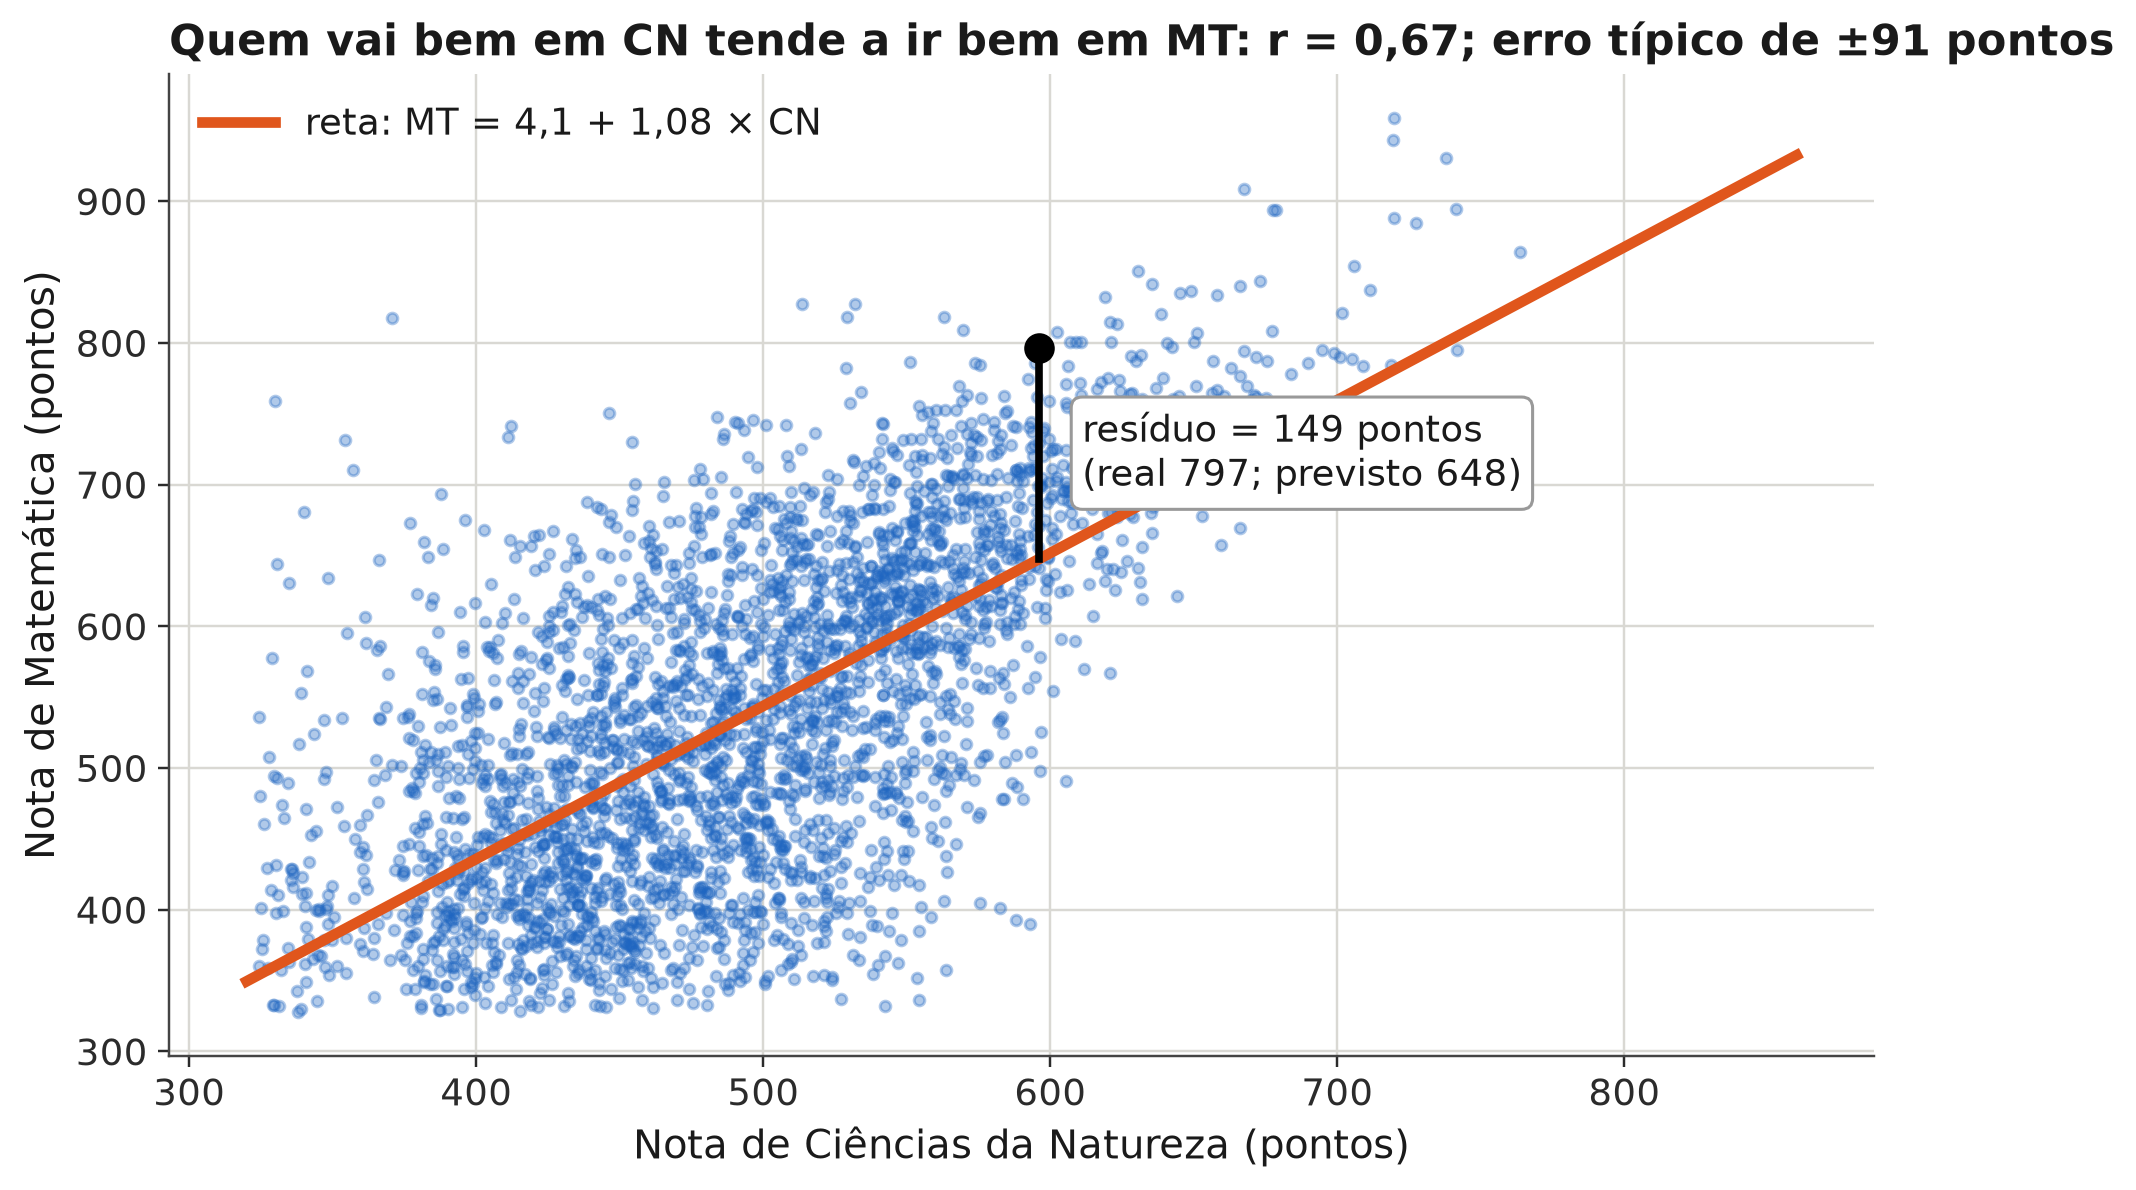

Aluno marcado: CN = 596,2 | MT real = 797 | previsto = 648 | resíduo = 149 pontos


In [53]:
rng = np.random.default_rng(SEMENTE)                                  # gerador desta seção: 3.000 pontos para o gráfico
i_cn = rng.choice(len(conc), 3000, replace=False)                     # com 1 milhão de pontos, o gráfico vira uma mancha
fig, ax = plt.subplots(figsize=(10, 5.8))
ax.scatter(x_cn[i_cn], y_mt[i_cn], s=12, alpha=0.35, color=AZUL)
xs = np.array([320, 860])
ax.plot(xs, a_cn + b_cn * xs, color=LARANJA, lw=3.5, label=f'reta: MT = {br(a_cn)} + {br(b_cn, 2)} × CN')
# Um aluno como exemplo de resíduo: perto de 600 em CN, com resíduo perto de +150
perto = i_cn[np.abs(x_cn[i_cn] - 600) < 10]
j = perto[np.argmin(np.abs(residuo_cn[perto] - 150))]
ax.plot([x_cn[j], x_cn[j]], [a_cn + b_cn * x_cn[j], y_mt[j]], color='black', lw=2.5)
ax.plot(x_cn[j], y_mt[j], 'o', color='black', ms=9)
ax.annotate(f'resíduo = {br(residuo_cn[j], 0)} pontos\n(real {br(y_mt[j], 0)}; previsto {br(a_cn + b_cn * x_cn[j], 0)})',
            (x_cn[j], (y_mt[j] + a_cn + b_cn * x_cn[j]) / 2), xytext=(14, 0), textcoords='offset points', fontsize=12, va='center',
            bbox=dict(facecolor='white', edgecolor='#999999', boxstyle='round,pad=0.3'))
ax.set_xlabel('Nota de Ciências da Natureza (pontos)'); ax.set_ylabel('Nota de Matemática (pontos)')
ax.set_title(f'Quem vai bem em CN tende a ir bem em MT: r = {br(r_cn, 2)}; erro típico de ±{br(erro_tipico_cn, 0)} pontos')
ax.legend(loc='upper left')
plt.show()
print(f'Aluno marcado: CN = {br(x_cn[j])} | MT real = {br(y_mt[j], 0)} | previsto = {br(a_cn + b_cn * x_cn[j], 0)} | resíduo = {br(residuo_cn[j], 0)} pontos')

## 7.2 O coeficiente de determinação (R²)

Sem modelo, o melhor palpite para a nota de MT de qualquer aluno é a **média geral**; com a reta, é o valor previsto pela nota de CN. O **R²** é a fração da variação em torno da média geral que deixa de existir quando se usa a reta: R² = 1 − (soma dos resíduos ao quadrado) ÷ (soma dos desvios em torno da média, ao quadrado). Vai de 0 (a reta não ajuda) a 1 (prevê todo mundo sem erro). Na regressão simples, **R² = r²**.

In [54]:
sqt_cn = ((y_mt - y_mt.mean()) ** 2).sum()                            # variação em torno da média geral
sqr_cn = (residuo_cn ** 2).sum()                                      # variação em torno da reta
print(f'R² = 1 − {br(sqr_cn / 1e6, 0)} mi ÷ {br(sqt_cn / 1e6, 0)} mi = {br(1 - sqr_cn / sqt_cn, 3)} | '
      f'r² = {br(r_cn ** 2, 3)} | statsmodels: {br(modelo_cn.rsquared, 3)}')

R² = 1 − 8.258 mi ÷ 15.147 mi = 0,455 | r² = 0,455 | statsmodels: 0,455


**Leitura:** a nota de CN acompanha cerca de 45% da variação de MT; o resto fica nos resíduos. Para dados sociais é um R² alto, e mesmo assim o erro típico de uma previsão individual é de cerca de ±91 pontos.

## 7.3 Quando X é categórica: a indicadora (MT ~ escola)

E o problema da palestra? O tipo de escola não é número. Na regressão, uma variável categórica entra como **indicadora** (0 ou 1): `privada` = 1 para escola privada e 0 para pública. A "reta" passa a ligar só dois pontos, as médias dos dois grupos:
- **a** (intercepto) é a média prevista com privada = 0: a média da pública;
- **b** (inclinação) é o quanto a média muda de privada = 0 para privada = 1: a diferença da manchete;
- o teste do coeficiente é o próprio **teste t** de duas médias (na versão de variâncias iguais).

É assim que sexo e cor/raça entram no modelo múltiplo (seção 7.5).

In [55]:
conc['privada'] = (conc.TP_ESCOLA == 3).astype(int)                   # 1 = privada, 0 = pública
modelo_esc = sm.OLS(conc.NU_NOTA_MT, sm.add_constant(conc[['privada']])).fit()   # add_constant inclui o intercepto a
a, b = modelo_esc.params
erro_tipico = np.sqrt(modelo_esc.scale)                               # desvio padrão dos resíduos
print(f'MT = {br(a)} + {br(b)} × privada | R² = {br(modelo_esc.rsquared, 3)} | erro típico de previsão = ±{br(erro_tipico)} pontos')
print(f'IC95% do coeficiente da privada: [{br(modelo_esc.conf_int().loc["privada", 0])}; {br(modelo_esc.conf_int().loc["privada", 1])}]')
# Verificação independente
t_classico = stats.ttest_ind(pop_priv, pop_pub, equal_var=True).statistic
print(f'Conferência: média da pública = {br(pop_pub.mean())}; diferença = {br(DIF_POP)}; '
      f't do coeficiente = {br(modelo_esc.tvalues["privada"], 1)}; t do teste t (variâncias iguais) = {br(t_classico, 1)}')

y = conc.NU_NOTA_MT
var_total = ((y - y.mean()) ** 2).sum()                               # variação em torno da média geral
var_residual = (modelo_esc.resid ** 2).sum()                          # variação em torno da média de cada tipo de escola
print(f'R² = 1 − {br(var_residual / 1e6, 0)} mi ÷ {br(var_total / 1e6, 0)} mi = {br(1 - var_residual / var_total, 3)} '
      f'(η² da escola = {br(eta2(conc.NU_NOTA_MT, conc.escola), 3)})')
print(f'A escola acompanha {br(100 * modelo_esc.rsquared)}% da variação de MT; {br(100 * (1 - modelo_esc.rsquared))}% fica dentro de cada tipo de escola')

MT = 511,2 + 121,8 × privada | R² = 0,168 | erro típico de previsão = ±112,1 pontos
IC95% do coeficiente da privada: [121,3; 122,3]
Conferência: média da pública = 511,2; diferença = 121,8; t do coeficiente = 449,6; t do teste t (variâncias iguais) = 449,6


R² = 1 − 12.605 mi ÷ 15.147 mi = 0,168 (η² da escola = 0,168)
A escola acompanha 16,8% da variação de MT; 83,2% fica dentro de cada tipo de escola


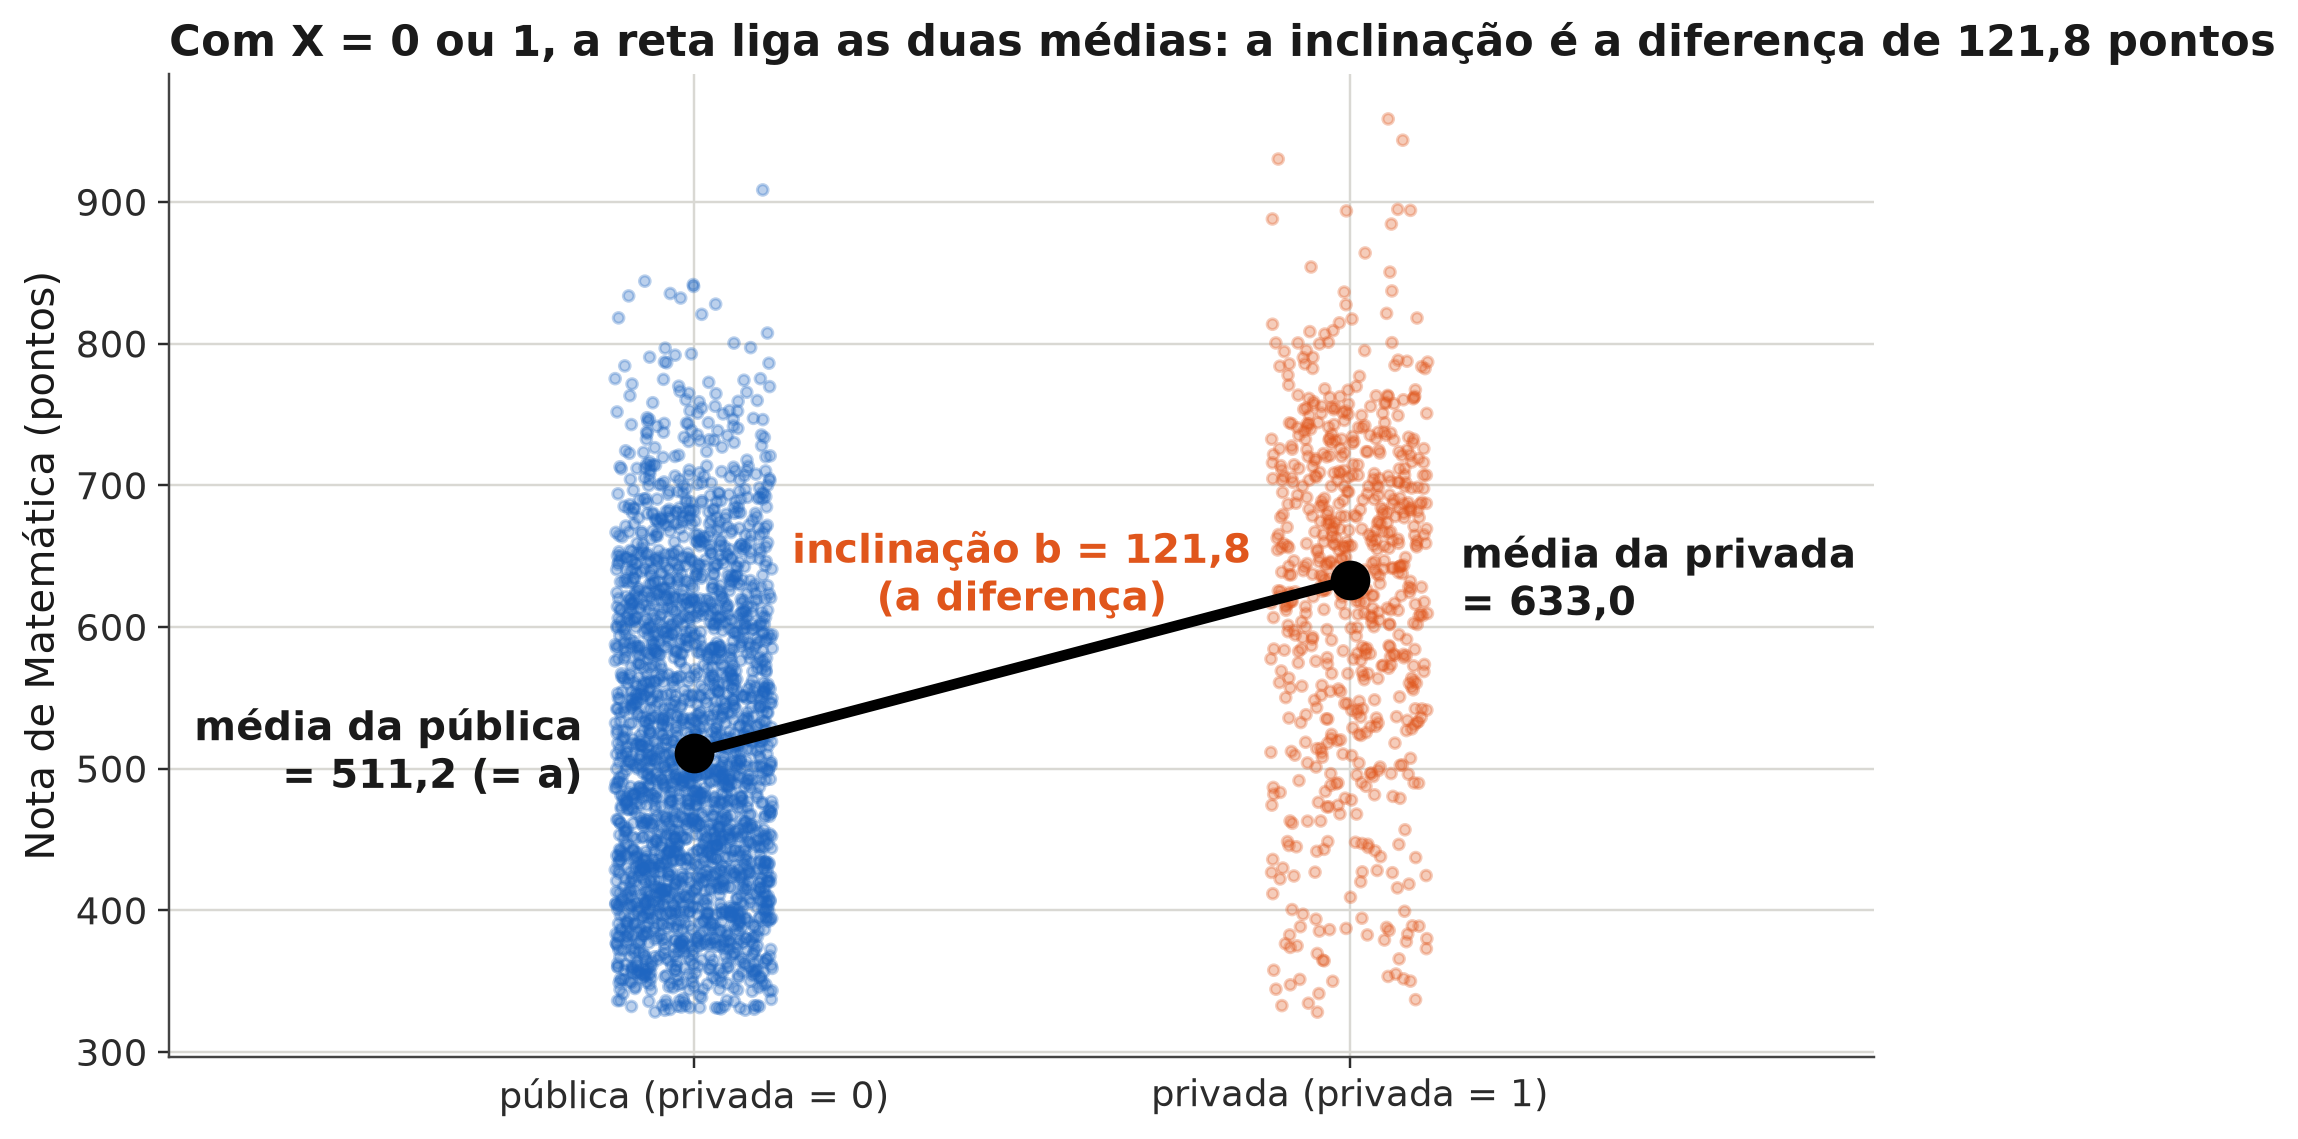

In [56]:
rng = np.random.default_rng(SEMENTE)                                  # gerador desta seção: 3.000 pontos para o gráfico
i_esc = rng.choice(len(conc), 3000, replace=False)
x_esc = conc.privada.to_numpy()[i_esc]
fig, ax = plt.subplots(figsize=(10, 5.8))
ax.scatter(x_esc + rng.uniform(-0.12, 0.12, len(i_esc)), conc.NU_NOTA_MT.to_numpy()[i_esc], s=12, alpha=0.3,
           c=np.where(x_esc == 1, LARANJA, AZUL))                     # pontos espalhados na horizontal só para não se sobreporem
ax.plot([0, 1], [a, a + b], color='black', lw=3.5)
ax.plot([0, 1], [a, a + b], 'o', color='black', ms=12)
ax.text(-0.17, a, f'média da pública\n= {br(a)} (= a)', ha='right', va='center', fontsize=13, fontweight='bold')
ax.text(1.17, a + b, f'média da privada\n= {br(a + b)}', ha='left', va='center', fontsize=13, fontweight='bold')
ax.text(0.5, a + b / 2 + 30, f'inclinação b = {br(b)}\n(a diferença)', ha='center', va='bottom', fontsize=13, color=LARANJA, fontweight='bold')
ax.set_xticks([0, 1], ['pública (privada = 0)', 'privada (privada = 1)'])
ax.set_xlim(-0.8, 1.8)
ax.set_ylabel('Nota de Matemática (pontos)')
ax.set_title(f'Com X = 0 ou 1, a reta liga as duas médias: a inclinação é a diferença de {br(b)} pontos')
plt.show()

**Leitura:** a regressão com a indicadora reproduz a manchete (intercepto = média da pública; inclinação = 121,8) e o teste t. A escola acompanha uma parte relevante da variação, mas a maior parte está **entre alunos do mesmo tipo de escola**. A equação prevê a **média** de cada grupo, não o aluno: o erro típico de uma previsão individual é de cerca de ±112 pontos.

## 7.4 A renda entra na história

Renda e escola andam juntas (Ex. 3). E a renda, sozinha, acompanha quanto da nota? A renda (Q006) é **ordinal**, em 17 faixas. Usar o código da faixa (1 a 17) como número supõe que cada passo de faixa vale o mesmo; o gráfico mostra que a média sobe de forma quase regular, o que torna a suposição aceitável como aproximação.

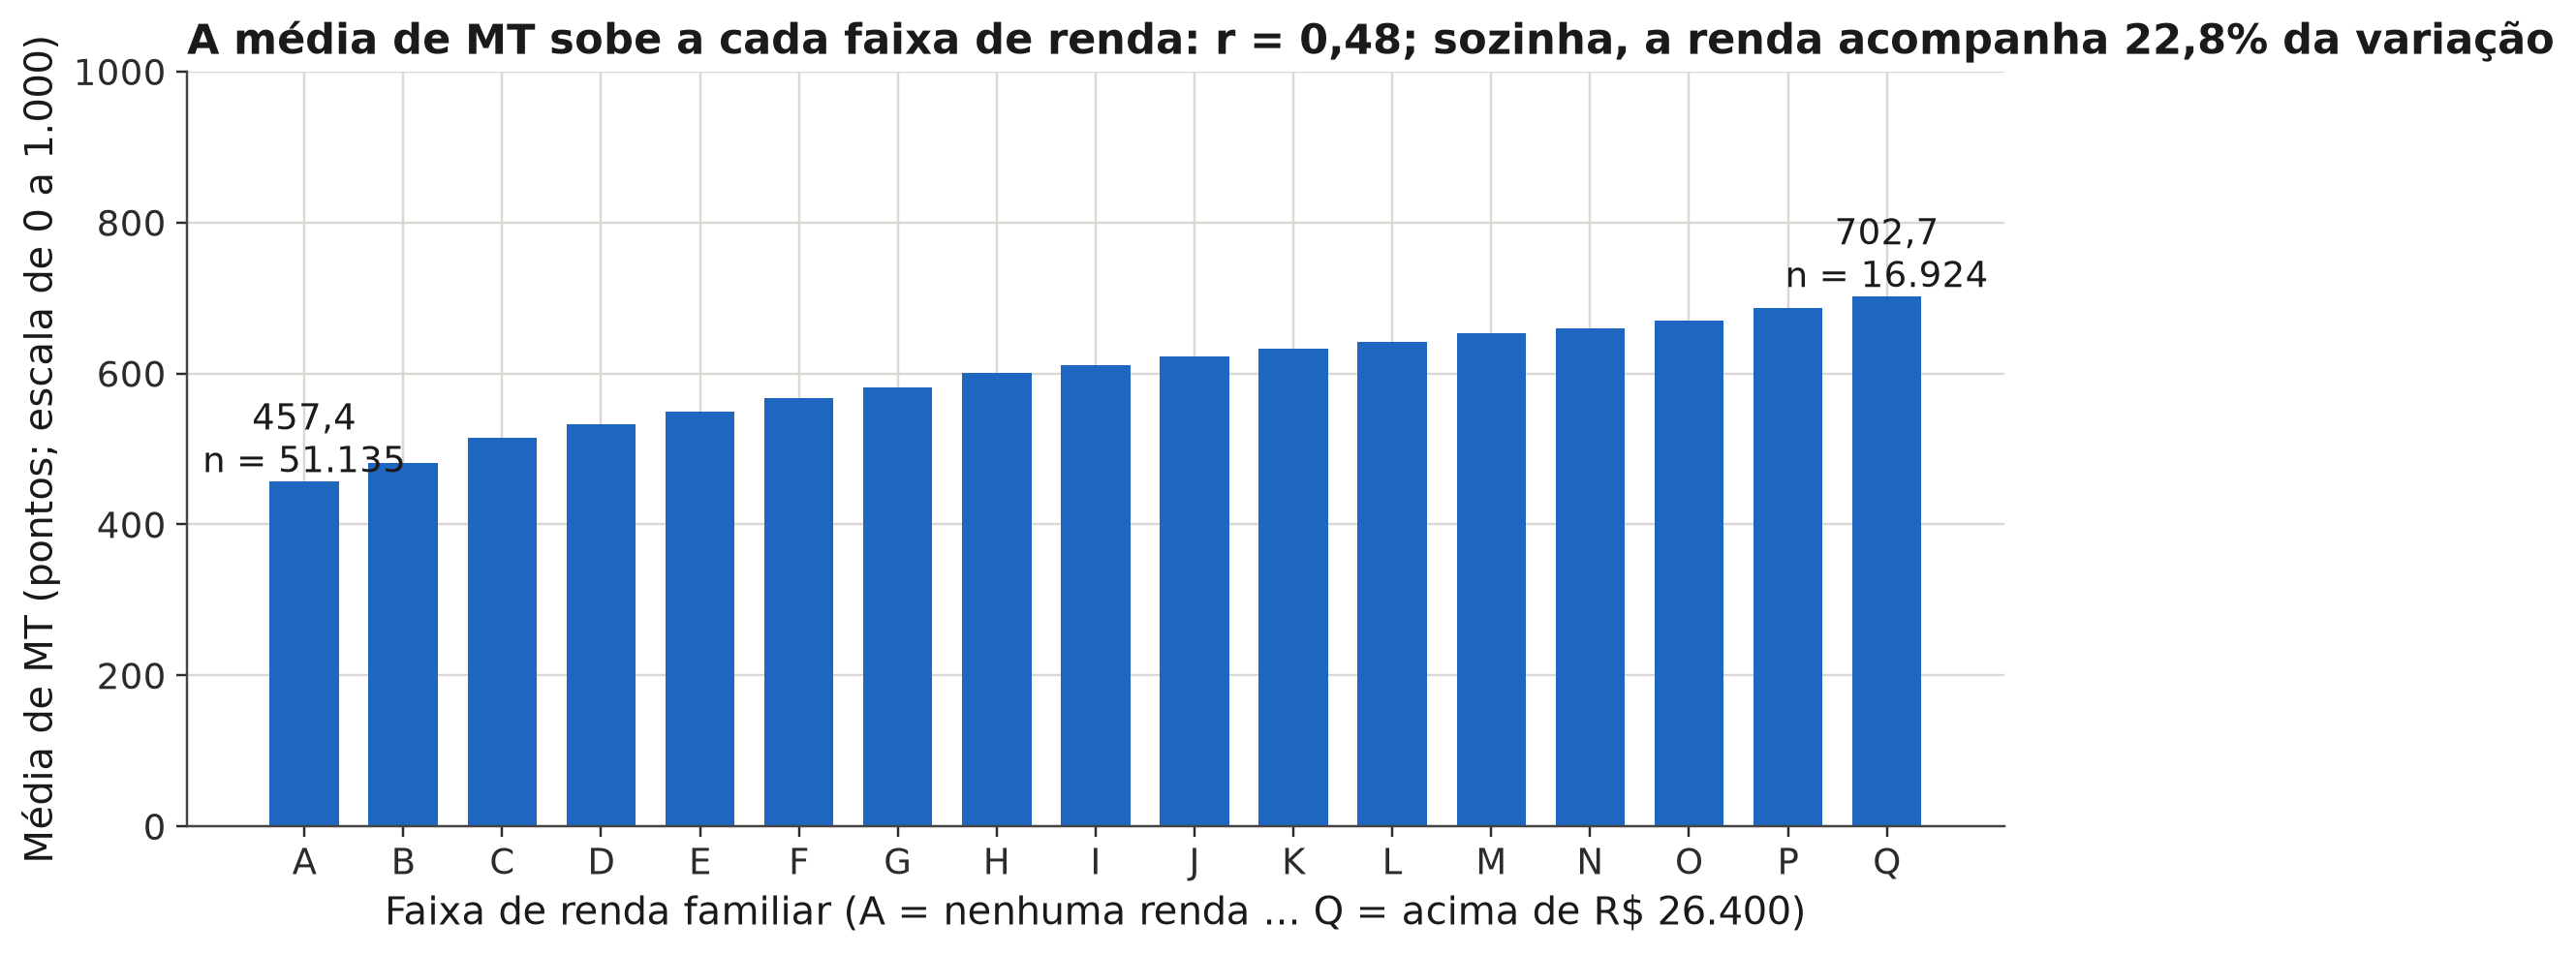

Média de MT: faixa A (sem renda) = 457,4 | faixa Q = 702,7
MT = 460,5 + 15,7 × renda (código 1–17) | R² = 0,228 | r = 0,478 | r² = 0,228
E escola × renda (Ex. 3): V de Cramér = 0,549


In [57]:
por_renda = conc.groupby('Q006').NU_NOTA_MT.agg(n='count', média='mean').loc[FAIXAS_RENDA]
modelo_renda = sm.OLS(conc.NU_NOTA_MT, sm.add_constant(conc[['renda']])).fit()
r_renda = np.corrcoef(conc.renda, conc.NU_NOTA_MT)[0, 1]

fig, ax = plt.subplots(figsize=(11, 4.6))
ax.bar(por_renda.index, por_renda['média'], color=AZUL, width=0.7)
for i in (0, 16):                                              # rótulo só na primeira e na última barra
    ax.text(i, por_renda['média'].iloc[i] + 12, f"{br(por_renda['média'].iloc[i])}\nn = {br(por_renda.n.iloc[i], 0)}", ha='center', fontsize=12)
ax.set_ylim(0, 1000)
ax.set_xlabel('Faixa de renda familiar (A = nenhuma renda ... Q = acima de R$ 26.400)')
ax.set_ylabel('Média de MT (pontos; escala de 0 a 1.000)')
ax.set_title(f'A média de MT sobe a cada faixa de renda: r = {br(r_renda, 2)}; sozinha, a renda acompanha {br(100 * modelo_renda.rsquared, 1)}% da variação')
plt.show()
a_r, b_r = modelo_renda.params
print(f"Média de MT: faixa A (sem renda) = {br(por_renda['média'].iloc[0])} | faixa Q = {br(por_renda['média'].iloc[-1])}")
print(f'MT = {br(a_r)} + {br(b_r)} × renda (código 1–17) | R² = {br(modelo_renda.rsquared, 3)} | r = {br(r_renda, 3)} | r² = {br(r_renda ** 2, 3)}')
print(f'E escola × renda (Ex. 3): V de Cramér = {br(V_POP, 3)}')

**Leitura:** a renda, sozinha, acompanha mais da variação de MT que a escola, e as duas andam juntas. Quando duas explicações concorrentes andam juntas, é preciso pô-las no **mesmo modelo** para ver quanto de cada uma permanece.

## 7.5 Regressão múltipla: o que permanece

Na regressão múltipla, cada coeficiente é a diferença na média de MT associada àquele fator **comparando alunos iguais nos demais fatores do modelo**. Isso controla o confundimento **observado**; o que não foi medido continua lá.

**Como as variáveis entram.** A renda entra como o código da faixa (1 a 17), o que supõe que cada passo de faixa vale o mesmo. As categorias viram **indicadoras** (0 ou 1): `privada` = 1 para escola privada; `mulher` = 1 para mulheres; uma indicadora para cada grupo de cor/raça, com **Branca** (o maior grupo) como referência. Os fatores entram um de cada vez, começando pela escola: assim se vê o que acontece com os 122 pontos a cada passo.

### Prompt para a IA — a regressão múltipla

O prompt que levaria ao código desta seção. Ele segue o molde do curso: **Papel, Contexto, Pergunta, Tarefa, Restrições, Formato**; pede código (não números), dá o contexto e as restrições, e pede as premissas.

```text
Papel: Você é um estatístico revisando uma análise para gestores públicos.

Contexto: DataFrame conc com os concluintes de 2023 que informaram escola (base de análise do ENEM 2023, cerca de 1 milhão). Colunas: NU_NOTA_MT; TP_ESCOLA (2 pública, 3 privada); Q006 (renda, 17 faixas ordinais A–Q); TP_SEXO (M, F); TP_COR_RACA (0 não declarada, 1 branca, 2 preta, 3 parda, 4 amarela, 5 indígena). Dados observacionais.

Pergunta: Quanto da diferença de MT entre escola privada e pública permanece quando renda, sexo e cor/raça entram no modelo?

Tarefa: Escreva código Python (pandas e statsmodels) que: (1) codifique a renda como código 1–17 (diga o que isso supõe) e escola, sexo e cor/raça como indicadoras 0/1, com pública, homem e branca como referência; (2) ajuste quatro modelos OLS, um fator a mais por vez: só escola; + renda; + sexo; + cor/raça; (3) imprima uma tabela com coeficientes, IC95% e R² de cada modelo; (4) faça o diagnóstico: resíduos × ajustados e VIF.

Restrições: Não use "efeito" nem "causa". Diga que variáveis importantes ficaram de fora. Só o código: não execute nem mostre resultados.

Formato: Código comentado; depois, como ler cada coeficiente e quatro frases-modelo de interpretação em linguagem de associação, com lacunas no lugar dos números.
```

**Verificação independente** (o que o analista confere depois de rodar o código que a IA escreveu):
- n = nº de concluintes de 2023 com TP_ESCOLA 2 ou 3 na base de análise (1.002.841).
- No modelo só com a escola, o coeficiente é a diferença bruta (121,8).
- O coeficiente da escola cai quando a renda entra (renda e escola andam juntas).
- Cor/raça como indicadoras 0/1, nunca como número 0–6.
- VIF abaixo de 10 (seção 7.8).
- Texto: "diferença que permanece", não "efeito da escola".

*Nos slides: Parte 7, slide 97.*

> **Demonstração na palestra.** Os quatro modelos abaixo, com o coeficiente da escola caindo quando os controles entram.

In [58]:
conc['mulher'] = (conc.TP_SEXO == 'F').astype(int)                    # 1 = mulher, 0 = homem
conc['preta'] = (conc.TP_COR_RACA == 2).astype(int)                   # cor/raça: referência = branca
conc['parda'] = (conc.TP_COR_RACA == 3).astype(int)
conc['indígena'] = (conc.TP_COR_RACA == 5).astype(int)
conc['amarela ou não decl.'] = conc.TP_COR_RACA.isin([0, 4]).astype(int)
COR = ['preta', 'parda', 'indígena', 'amarela ou não decl.']

etapas = {
    'só escola': ['privada'],
    '+ renda': ['privada', 'renda'],
    '+ sexo': ['privada', 'renda', 'mulher'],
    '+ cor/raça': ['privada', 'renda', 'mulher'] + COR,
}
modelos, linhas = {}, []
for nome, variaveis in etapas.items():
    modelos[nome] = sm.OLS(conc.NU_NOTA_MT, sm.add_constant(conc[variaveis])).fit()     # ajusta o modelo
    linhas.append({'modelo': nome, **modelos[nome].params.drop('const').to_dict(), 'R²': modelos[nome].rsquared})
print('n =', br(len(conc), 0))
pd.DataFrame(linhas).set_index('modelo')[['privada', 'renda', 'mulher'] + COR + ['R²']].round(3)

n = 1.002.841


,privada,renda,mulher,preta,parda,indígena,amarela ou não decl.,R²
modelo,,,,,,,,
só escola,121.800,NaN,NaN,NaN,NaN,NaN,NaN,0.168
+ renda,60.585,11.881,NaN,NaN,NaN,NaN,NaN,0.256
+ sexo,60.729,11.408,-34.041,NaN,NaN,NaN,NaN,0.275
+ cor/raça,57.850,10.395,-34.912,-35.056,-25.67,-56.247,-16.909,0.286


In [59]:
# Intervalos de confiança de 95% dos coeficientes do modelo completo
completo = modelos['+ cor/raça']
ic_coef = completo.conf_int()                                         # duas colunas: limite inferior e superior
pd.DataFrame({'coeficiente': completo.params, 'IC95% inf': ic_coef[0], 'IC95% sup': ic_coef[1]}).round(2)

,coeficiente,IC95% inf,IC95% sup
const,509.67,509.12,510.22
privada,57.85,57.25,58.45
renda,10.39,10.33,10.46
mulher,-34.91,-35.33,-34.50
preta,-35.06,-35.76,-34.35
parda,-25.67,-26.13,-25.21
indígena,-56.25,-59.11,-53.38
amarela ou não decl.,-16.91,-18.21,-15.61


**Leitura:**
- Com a renda no modelo, o coeficiente da escola **cai pela metade**: parte da diferença bruta acompanhava a renda (o **confundidor**: renda alta leva à escola privada e anda com nota alta).
- Sexo quase não muda o coeficiente da escola (meninos e meninas se distribuem de forma parecida entre as redes); cor/raça o reduz um pouco.
- O que **permanece** (cerca de 58 pontos) é a diferença entre alunos de privada e de pública **com a mesma faixa de renda, o mesmo sexo e a mesma cor/raça**. Não é "efeito da escola": é a parte que essas variáveis não explicam.

## 7.6 Quanto cada fator explica

O R² do modelo completo pode ser repartido em três leituras para cada fator: o R² dele **sozinho**; o que ele acrescenta **além dos outros** (R² do modelo completo − R² do modelo sem ele); e a **parte comum**, que ele divide com os outros fatores e que nenhuma regressão consegue atribuir a um só. "Explica" aqui tem sentido **estatístico**: variação associada ao fator, não causa.

In [60]:
fatores = {'escola': ['privada'], 'renda': ['renda'], 'sexo': ['mulher'], 'cor/raça': COR}
todas_vars = sum(fatores.values(), [])
R2_COMPLETO = completo.rsquared
reparticao = {}
for nome, vars_f in fatores.items():
    sozinho = sm.OLS(conc.NU_NOTA_MT, sm.add_constant(conc[vars_f])).fit().rsquared
    sem = sm.OLS(conc.NU_NOTA_MT, sm.add_constant(conc[[v for v in todas_vars if v not in vars_f]])).fit().rsquared
    reparticao[nome] = {'sozinho (%)': 100 * sozinho, 'além dos outros (%)': 100 * (R2_COMPLETO - sem),
                        'parte comum (%)': 100 * (sozinho - (R2_COMPLETO - sem))}
rep = pd.DataFrame(reparticao).T
display(rep.round(1))
soma_unicas = rep['além dos outros (%)'].sum()
print(f'Modelo completo: R² = {br(100 * R2_COMPLETO)}% | soma do que cada fator acrescenta além dos outros = {br(soma_unicas)}% | '
      f'parte comum a mais de um fator = {br(100 * R2_COMPLETO - soma_unicas)}%')
print(f'Fora do modelo: {br(100 * (1 - R2_COMPLETO))}% da variação de MT')

,sozinho (%),além dos outros (%),parte comum (%)
escola,16.8,2.5,14.2
renda,22.8,6.4,16.5
sexo,3.4,1.9,1.4
cor/raça,6.8,1.2,5.7


Modelo completo: R² = 28,6% | soma do que cada fator acrescenta além dos outros = 12,0% | parte comum a mais de um fator = 16,6%
Fora do modelo: 71,4% da variação de MT


**Leitura:** a maior fatia do R² é **comum** a escola e renda: como elas andam juntas, não dá para atribuir essa parte a uma só. Além disso, cada fator acrescenta pouco sozinho. E mais de 70% da variação de MT fica **fora** do modelo.

## 7.7 Mesmos resumos, gráficos diferentes: por que olhar os resíduos

Quatro conjuntos de dados construídos por Anscombe (1973, *The American Statistician* 27(1):17–21) têm a mesma média, a mesma variância, o mesmo r e a mesma reta, e relações completamente diferentes. *(Caso conceitual.)* Lição: o resumo numérico de um modelo não basta; é preciso **olhar os resíduos**.

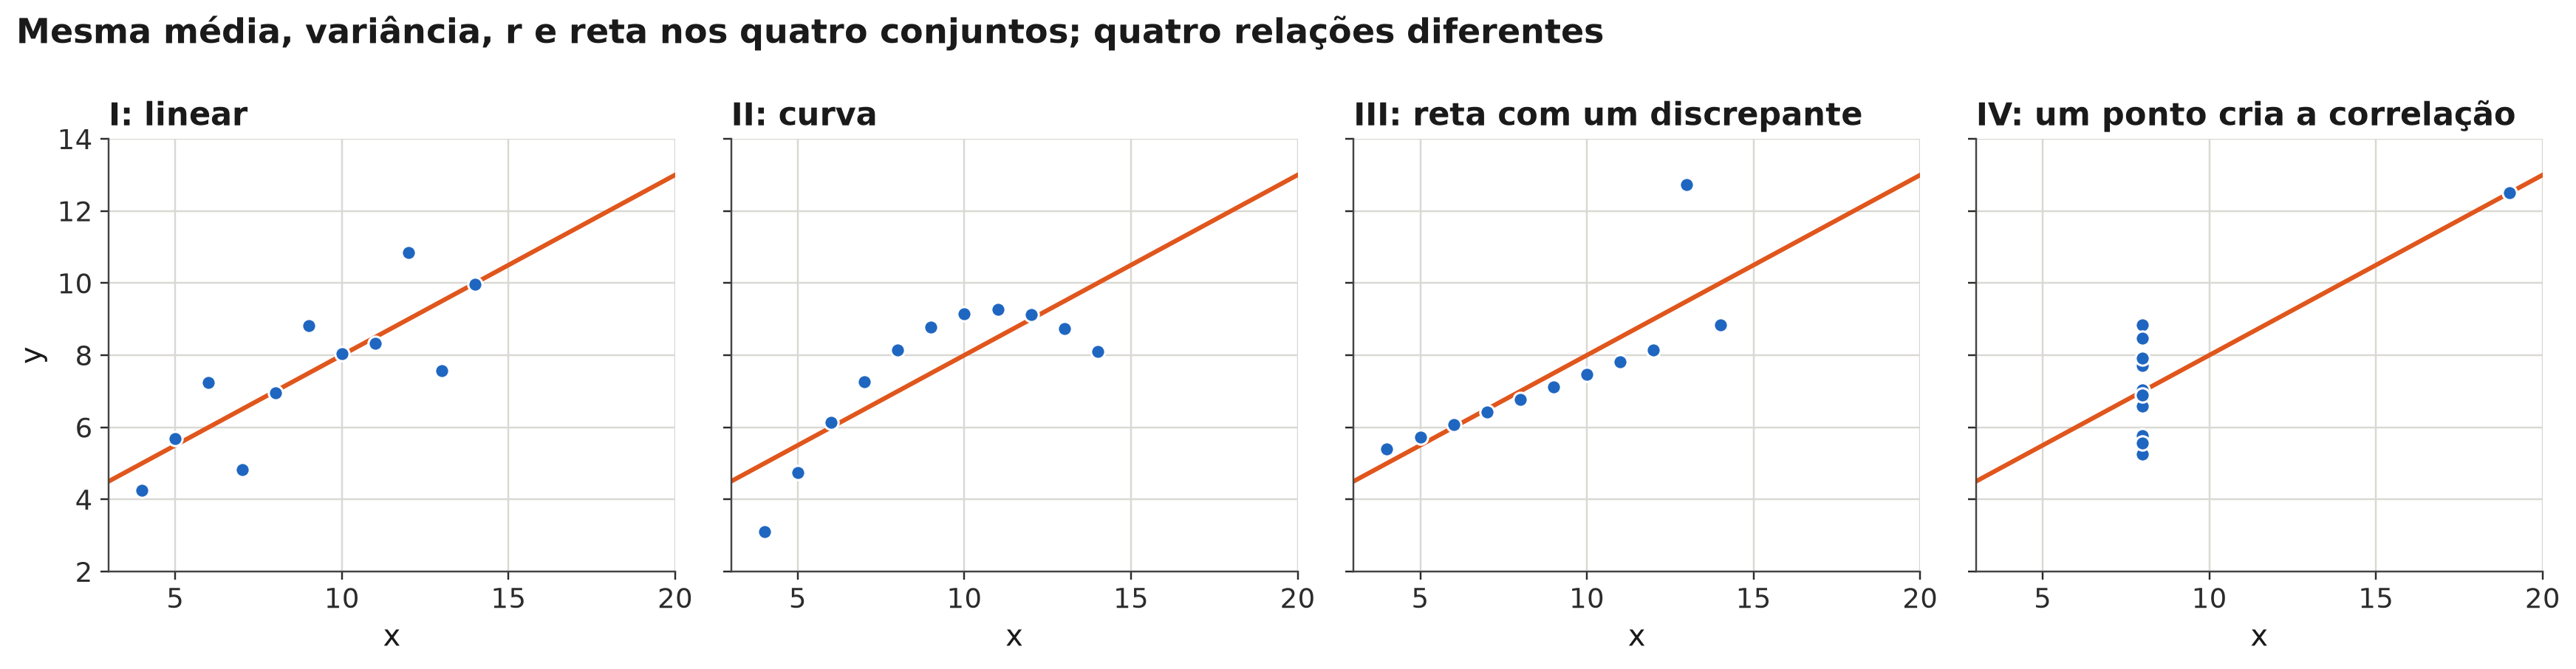

,média x,média y,variância y,r,intercepto,inclinação
I: linear,9.0,7.501,4.127,0.816,3.000,0.5
II: curva,9.0,7.501,4.128,0.816,3.001,0.5
III: reta com um discrepante,9.0,7.500,4.123,0.816,3.002,0.5
IV: um ponto cria a correlação,9.0,7.501,4.123,0.817,3.002,0.5


In [61]:
X_ANS = [10, 8, 13, 9, 11, 14, 6, 4, 12, 7, 5]
ANSCOMBE = {
    'I: linear':                      (X_ANS, [8.04, 6.95, 7.58, 8.81, 8.33, 9.96, 7.24, 4.26, 10.84, 4.82, 5.68]),
    'II: curva':                      (X_ANS, [9.14, 8.14, 8.74, 8.77, 9.26, 8.10, 6.13, 3.10, 9.13, 7.26, 4.74]),
    'III: reta com um discrepante':   (X_ANS, [7.46, 6.77, 12.74, 7.11, 7.81, 8.84, 6.08, 5.39, 8.15, 6.42, 5.73]),
    'IV: um ponto cria a correlação': ([8, 8, 8, 8, 8, 8, 8, 19, 8, 8, 8], [6.58, 5.76, 7.71, 8.84, 8.47, 7.04, 5.25, 12.50, 5.56, 7.91, 6.89]),
}
resumos = {}
fig, eixos = plt.subplots(1, 4, figsize=(16, 4.2), sharex=True, sharey=True)
for ax, (nome, (x, y_a)) in zip(eixos, ANSCOMBE.items()):
    x, y_a = np.array(x, dtype=float), np.array(y_a)
    inclinacao, intercepto = np.polyfit(x, y_a, 1)                    # a reta de mínimos quadrados
    resumos[nome] = {'média x': x.mean(), 'média y': y_a.mean(), 'variância y': y_a.var(ddof=1), 'r': np.corrcoef(x, y_a)[0, 1],
                     'intercepto': intercepto, 'inclinação': inclinacao}
    ax.plot([3, 20], [intercepto + inclinacao * 3, intercepto + inclinacao * 20], color=LARANJA, lw=2)
    ax.scatter(x, y_a, s=40, color=AZUL, edgecolor='white', zorder=3)
    ax.set_title(nome, fontsize=14); ax.set_xlabel('x')
eixos[0].set_ylabel('y'); eixos[0].set_xlim(3, 20); eixos[0].set_ylim(2, 14)
fig.suptitle('Mesma média, variância, r e reta nos quatro conjuntos; quatro relações diferentes', x=0.01, ha='left', fontweight='bold')
plt.tight_layout()
plt.show()
pd.DataFrame(resumos).T.round(3)

## 7.8 Resíduos: o que o R² esconde, no modelo múltiplo

Três conferências: (a) a **codificação** (indicadoras só com 0 e 1); (b) a **colinearidade**, pelo VIF (o quanto cada variável é "explicada" pelas outras; acima de 10 indica problema); (c) os **resíduos**: se o modelo servisse igualmente bem em toda a escala, o resíduo médio ficaria perto de zero e com o mesmo espalhamento em todas as faixas de nota prevista.

In [62]:
# (a) Codificação
print('Indicadoras só com 0 e 1:', bool(conc[['privada', 'mulher'] + COR].isin([0, 1]).all().all()))

# (b) Colinearidade
X = sm.add_constant(conc[todas_vars]).to_numpy(dtype=float)
vif = pd.Series([variance_inflation_factor(X, i) for i in range(1, X.shape[1])], index=todas_vars)
display(vif.round(2).to_frame('VIF'))

# (c) Resíduos por faixa de nota prevista, e por tipo de escola
ajustado, residuo = completo.fittedvalues, completo.resid
faixa_aj = pd.cut(ajustado, [0, 480, 520, 560, 600, 640, 1000])
diag = residuo.groupby(faixa_aj, observed=True).agg(['count', 'mean', 'std']).rename(columns={'count': 'n', 'mean': 'resíduo médio', 'std': 'dp do resíduo'})
display(diag.round(1))
display(residuo.groupby(conc.escola).agg(['mean', 'std']).rename(columns={'mean': 'resíduo médio', 'std': 'dp do resíduo'}).round(1))
print(f'Erro típico de previsão do modelo completo = ±{br(np.sqrt(completo.scale))} pontos (só escola: ±{br(erro_tipico)})')

Indicadoras só com 0 e 1: True


,VIF
privada,1.49
renda,1.57
mulher,1.01
preta,1.16
parda,1.24
indígena,1.01
amarela ou não decl.,1.03


,n,resíduo médio,dp do resíduo
"(0, 480]",169106,-8.0,86.6
"(480, 520]",342036,-0.7,99.6
"(520, 560]",208866,6.6,108.4
"(560, 600]",108595,8.9,113.0
"(600, 640]",71748,4.8,113.8
"(640, 1000]",102490,-10.6,114.0


,resíduo médio,dp do resíduo
escola,,
Privada,0.0,113.0
Pública,-0.0,101.1


Erro típico de previsão do modelo completo = ±103,8 pontos (só escola: ±112,1)


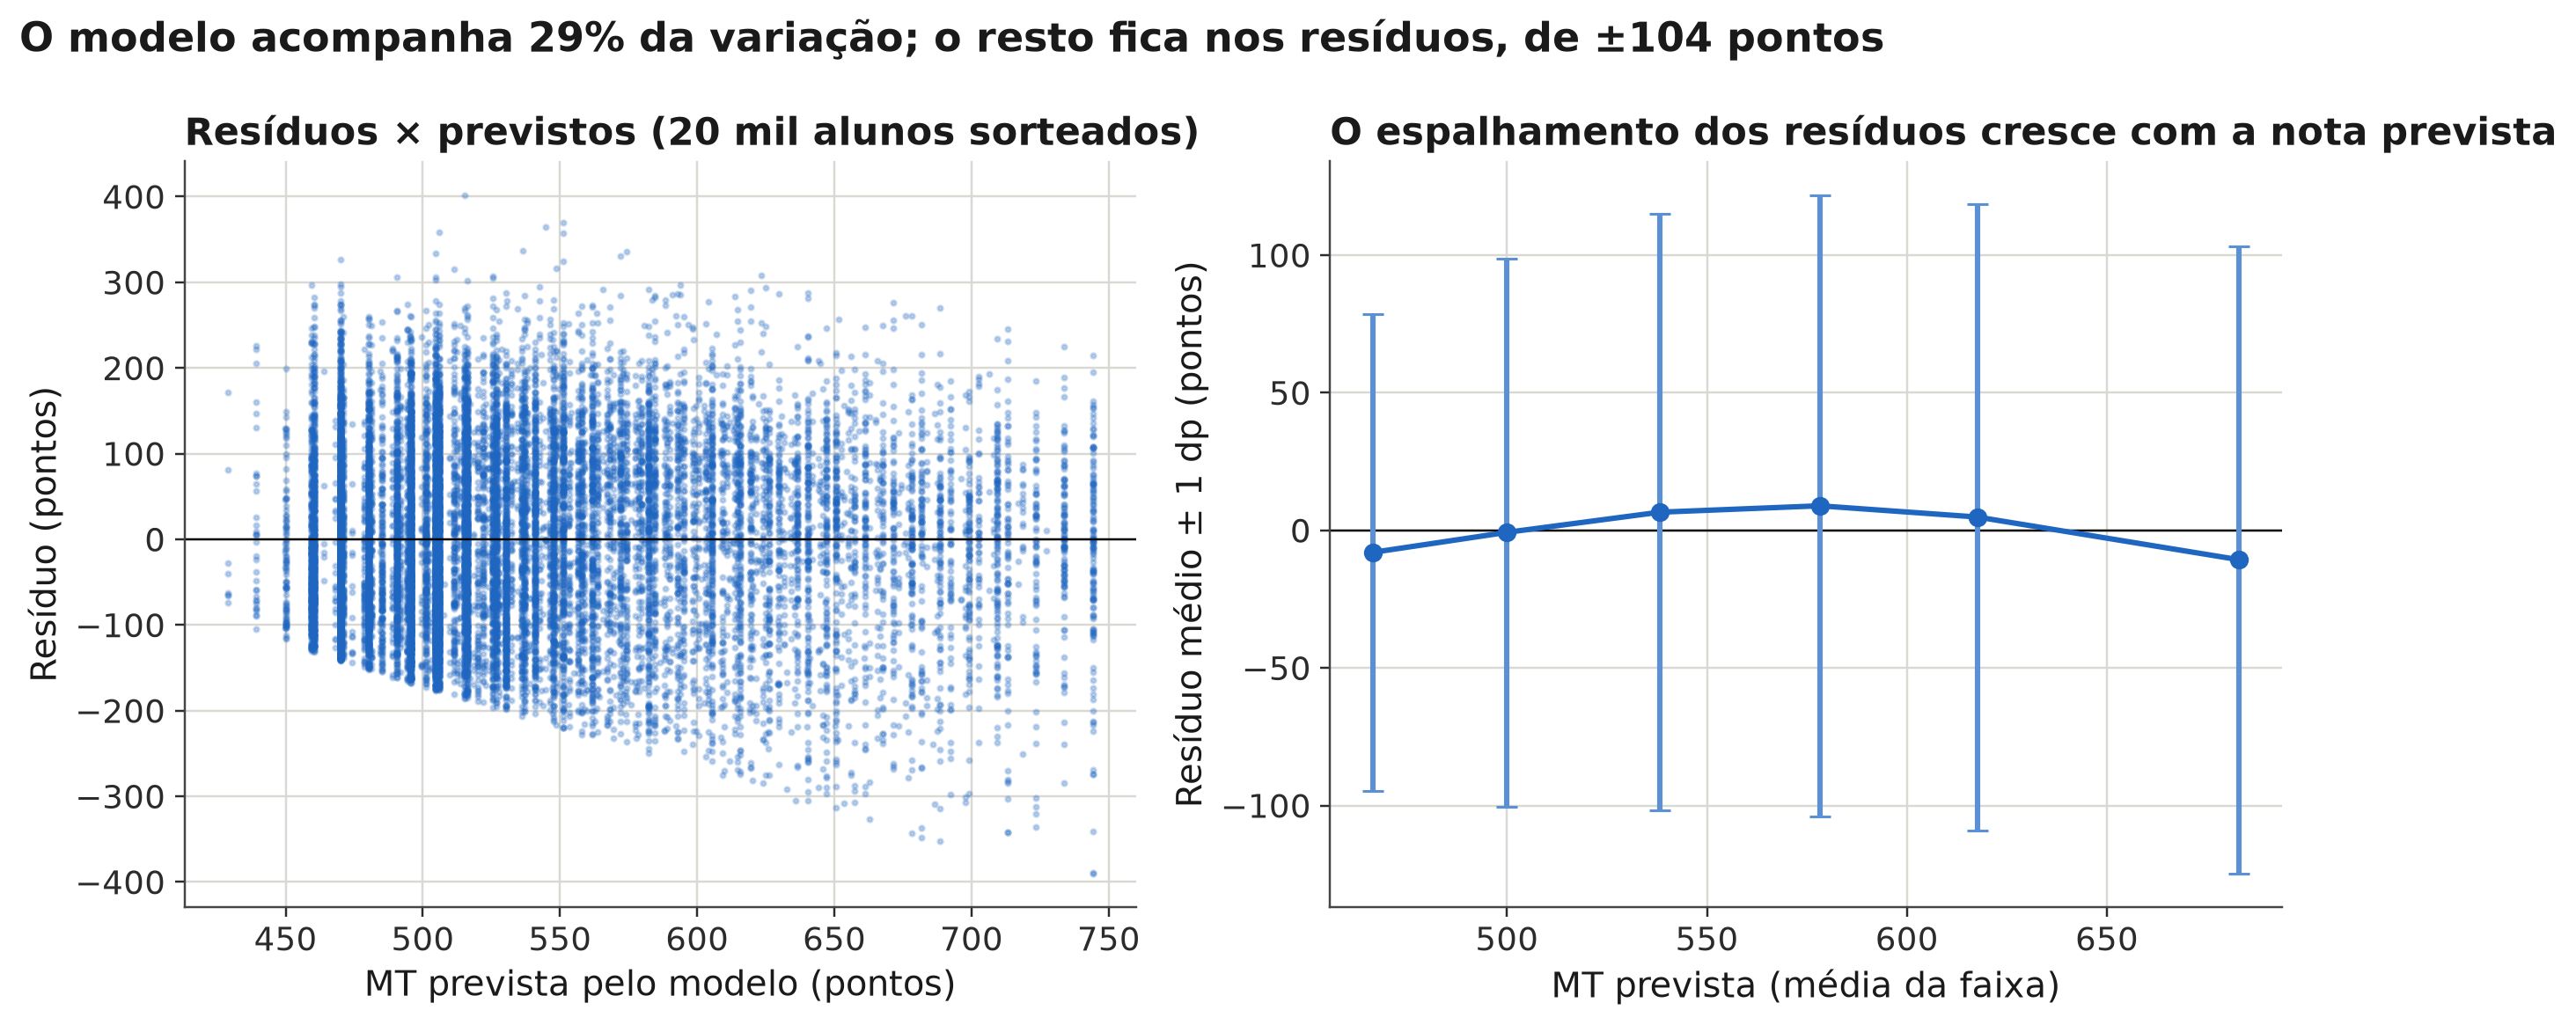

In [63]:
rng = np.random.default_rng(SEMENTE)                                  # gerador desta seção: 20 mil pontos para o gráfico
i = rng.choice(len(conc), 20_000, replace=False)                      # com 1 milhão de pontos, o gráfico vira uma mancha
centros = ajustado.groupby(faixa_aj, observed=True).mean()
fig, eixos = plt.subplots(1, 2, figsize=(12, 5.4))
eixos[0].scatter(ajustado.iloc[i], residuo.iloc[i], s=3, alpha=0.25, color=AZUL)
eixos[0].axhline(0, color='black', lw=0.8)
eixos[0].set_xlabel('MT prevista pelo modelo (pontos)'); eixos[0].set_ylabel('Resíduo (pontos)')
eixos[0].set_title('Resíduos × previstos (20 mil alunos sorteados)', fontsize=14)
eixos[1].axhline(0, color='black', lw=0.8)
eixos[1].errorbar(centros, diag['resíduo médio'], yerr=diag['dp do resíduo'], fmt='o-', color=AZUL, ecolor='#5b8fd6', capsize=4, lw=2)
eixos[1].set_xlabel('MT prevista (média da faixa)'); eixos[1].set_ylabel('Resíduo médio ± 1 dp (pontos)')
eixos[1].set_title('O espalhamento dos resíduos cresce com a nota prevista', fontsize=14)
fig.suptitle(f'O modelo acompanha {br(100 * R2_COMPLETO, 0)}% da variação; o resto fica nos resíduos, de ±{br(np.sqrt(completo.scale), 0)} pontos',
             x=0.01, ha='left', fontweight='bold')
plt.tight_layout()
plt.show()

**Leitura:** os VIF são baixos (não há colinearidade forte). O erro típico de previsão diminui pouco em relação ao modelo só com a escola (de ±112 para ±104 pontos): o modelo descreve **médias de grupos**, não alunos. E o espalhamento dos resíduos muda ao longo da escala (heterocedasticidade): a precisão do modelo não é a mesma para todos.

## 7.9 Associação não é causa

Três armadilhas, todas presentes no problema:
- **Confundidor:** a renda acompanha a escola e a nota. O coeficiente da escola cai de 121,8 para 60,6 quando a renda entra (seção 7.5).
- **Causa reversa:** escolas federais e muitas privadas selecionam alunos por prova: o desempenho leva à escola, e não só a escola ao desempenho.
- **O que não foi medido:** qualidade da escola, apoio da família, trajetória escolar, motivação. "Controlar" só alcança o que está no modelo.

## 7.10 A resposta ao problema

In [64]:
bruto, final = modelos['só escola'].params['privada'], completo.params['privada']
print(f'Diferença bruta (privada − pública): {br(bruto)} pontos (d = {br(D_POP, 2)})')
print(f'Com renda, sexo e cor/raça no modelo: {br(final)} pontos, IC95% [{br(ic_coef.loc["privada", 0])}; {br(ic_coef.loc["privada", 1])}] '
      f'= {br(100 * final / bruto, 0)}% da bruta')
print(f'Fora do modelo: {br(100 * (1 - R2_COMPLETO), 0)}% da variação de MT')
print(f'Quem ficou de fora da comparação: chegam à base {br(fora.loc["Pública", "% que chega à base"])}% dos inscritos de pública '
      f'e {br(fora.loc["Privada", "% que chega à base"])}% dos de privada')

Diferença bruta (privada − pública): 121,8 pontos (d = 1,09)
Com renda, sexo e cor/raça no modelo: 57,9 pontos, IC95% [57,3; 58,4] = 47% da bruta
Fora do modelo: 71% da variação de MT
Quem ficou de fora da comparação: chegam à base 67,2% dos inscritos de pública e 93,4% dos de privada


**Em linguagem de gestor:** comparando concluintes de 2023 com a **mesma** faixa de renda, o mesmo sexo e a mesma cor/raça, os de escola privada têm, em média, cerca de **58 pontos** a mais em Matemática, menos da metade da diferença bruta de 122, porque parte dela acompanhava a renda. A diferença é real (não é acaso: Ex. 1) e relevante (muito acima da margem do plano), mas **não é "efeito da escola"**: é uma associação numa base observacional, que não alcança o que não foi medido e que descreve só quem fez a prova inteira.

## 7.11 O relatório

O relatório é texto para a diretoria. Os números vêm das saídas das seções citadas entre parênteses; nenhum é calculado de cabeça. Ele pode ser redigido com ajuda da IA, desde que ela trabalhe **só** com as saídas do notebook:

### Prompt para a IA — o relatório a partir do notebook

O prompt que levaria ao código desta seção. Ele segue o molde do curso: **Papel, Contexto, Pergunta, Tarefa, Restrições, Formato**; pede código (não números), dá o contexto e as restrições, e pede as premissas.

```text
Papel: Você é um analista que redige relatórios curtos e rigorosos para a diretoria de uma instituição pública.

Contexto: Analisei os microdados do ENEM 2023 num notebook Python. Colo abaixo, para cada seção, o título e as saídas (tabelas e linhas impressas), sem os dados individuais. [colar as saídas das seções 2.5, 2.6, 3.2, 3.6, 3.7, 5.8, 6.5, 6.6, 6.8, 7.5, 7.6 e 7.10] A pergunta da diretoria era: alunos de escola privada tiram 122 pontos a mais em Matemática do que os de pública; de que tamanho é essa diferença, com que segurança podemos afirmá-la, e quanto dela permanece quando levamos em conta renda, sexo e cor/raça?

Pergunta: Quais são os achados principais, com que segurança, e com que limitações?

Tarefa: (1) Escreva um sumário executivo com um item para cada parte da pergunta: tamanho, segurança, o que permanece, e quem ficou de fora. (2) Em cada item, dê a estimativa, o intervalo de confiança ou o tamanho do efeito, a população analisada e a seção de onde saiu o número. (3) Liste as limitações. (4) Liste as afirmações que dependem de hipótese não verificada.

Restrições: Use SOMENTE os números das saídas coladas; não calcule nem arredonde de outro jeito; se faltar um número, escreva [FALTA] em vez de estimar. Linguagem de associação: nada de "efeito", "causa", "impacto" ou "prova". Não use "significativo" sem o tamanho do efeito.

Formato: Markdown, no máximo uma página, frases curtas, sem jargão; ao final, uma tabela "número citado → seção de origem".
```

**Verificação independente** (o que o analista confere depois de rodar o código que a IA escreveu):
- Conferir cada número do texto na saída da seção citada (a tabela "número → seção" serve para isso).
- Procurar números que não estavam nas saídas coladas: são invenção e saem do texto.
- Procurar palavras causais ("efeito", "impacto", "causa", "leva a") e trocá-las por linguagem de associação.
- Verificar se toda comparação de escola diz "concluintes de 2023" e se a seleção de quem comparece aparece nas limitações.

*Só no notebook.*

### Relatório: a diferença de Matemática entre escola privada e pública no ENEM 2023

**Fonte:** INEP, microdados do ENEM 2023. **Comparação:** 1.002.841 concluintes do ensino médio em 2023 que informaram o tipo de escola e fizeram a prova inteira, com redação sem problemas e nenhuma prova objetiva em branco (783.634 de escola pública e 219.207 de privada; seção 2.5). Todas as afirmações são de **associação** em dados observacionais.

**Sumário executivo**

1. **Tamanho.** A média de Matemática é de 633,0 pontos na escola privada e 511,2 na pública: diferença de 121,8 pontos, ou d = 1,09, cerca de um desvio padrão e mais de cinco vezes o mínimo relevante fixado no plano (d = 0,2 ≈ 23,1 pontos). As distribuições se sobrepõem: 15,9% dos alunos de pública ficam acima da média da privada (3.2, 3.4, 3.6).
2. **Segurança.** Numa amostra planejada de 394 alunos por grupo (n pelo poder), a diferença estimada é de 134,8 pontos (IC95% de 118,4 a 151,2; p < 0,001): o intervalo está inteiro acima da margem de relevância, e a diferença verdadeira está dentro dele (6.5).
3. **O que permanece.** Dentro de cada faixa de renda, a diferença fica entre 61,7 e 77,1 pontos (3.7). Com renda, sexo e cor/raça no modelo, ela é de 57,9 pontos (IC95% de 57,3 a 58,4), menos da metade da bruta; a renda é o fator que mais a reduz, porque escola e renda estão fortemente associadas (V de Cramér = 0,549). O modelo acompanha 28,6% da variação de Matemática (6.8, 7.5, 7.6).
4. **Quem ficou de fora.** Chegam à comparação 67,2% dos inscritos concluintes de escola pública e 93,4% dos de privada; a diferença vem sobretudo da presença na prova (71,4% × 94,5%), que também cresce com a renda (2.6, 5.8).

**Limitações**
1. **Seleção:** só quem fez a prova inteira está na comparação, e quem falta é mais pobre e mais de escola pública; é provável, mas não verificável, que a diferença entre todos os inscritos seja maior.
2. **Escola** só para concluintes de 2023; quem já concluiu o ensino médio não informa a escola.
3. **Questionário autodeclarado** (renda, cor/raça); renda em faixas, não em reais.
4. **Observacional:** controlar fatores medidos não remove o confundimento pelo que não foi medido (qualidade da escola, apoio familiar, seleção de alunos por prova).
5. **Privacidade:** nenhum recorte por município × cor/raça × escola, para não reidentificar pessoas.

### Checklist do relatório

- [x] Pergunta, hipótese e margem de relevância escritas antes (seção 1.5)
- [x] População analisada e quem ficou de fora (Parte 2 e seção 5.8)
- [x] Plano amostral e justificativa do n (Partes 5 e 6)
- [x] Efeito + IC95% + tamanho do efeito + valor-p, nunca só o valor-p
- [x] Leitura do IC contra a margem de relevância
- [x] Gráficos honestos: título com a conclusão, eixos com unidade, barras a partir de zero, n visível
- [x] Linguagem de associação, nunca de causa
- [ ] Verificação independente de cada número vindo de IA, e registro do uso (abaixo)

### Registro de uso de IA (regra 7)

Uma linha por prompt usado na análise. Exemplo de preenchimento:

| Data | Ferramenta/modelo | Seção | Prompt (resumo) | O que foi aproveitado | Verificação independente | Resultado |
|---|---|---|---|---|---|---|
| dd/mm/aaaa | (nome e versão) | 6.5 | Ex. 1: teste t, n pelo poder, controle negativo | código do sorteio e do teste | t à mão; controle negativo; IC × valor verdadeiro | conferiu |
| | | | | | | |

**A assinatura no relatório é sua, não da IA.**